# MMAD LAB_1: Классификация датасета Car Evaluation
**Выполнил:** Ямщиков Владимир Сергеевич  
**Группа:** 26162  
**Факультет:** Механико-математический    
**Направление:** Математика и Компьютерные Науки  
**Дата:** 12.10.2026

## Цель работы:
1. Провести разведочный анализ данных (EDA) датасета Car Evaluation.
2. Построить и визуализировать разделяющие поверхности для 5 алгоритмов классификации (LDA, QDA, Logistic Regression, SVM linear, SVM poly).
3. Провести автоматизированный подбор гиперпараметров с помощью фреймворка Optuna.
4. Глубоко проанализировать качество моделей (матрицы ошибок, кривые обучения, калибровка, SHAP).
5. Визуализировать работу LDA во всех двумерных подпространствах признаков.

## Условие лабораторной работы:

- 1. Загрузить **таблицу Car Evaluation** из **репозитория UCI** (можно из любого доступного источника: UCI, sklearn, kaggle). Поместить данные в объект DataFrame библиотеки pandas.
Визуализировать распределения классов на всех парах переменных.

- 2. Выбрать две переменные. Построить и визуализировать (показать разделяющую кривую) решения **методами линейный и квадратичный дискриминант, логистическая регрессия, SVM (линейное и квадратичное ядро)**. Оценить качество классификации этими методами при помощи коросс-валидации на выбранных признаках и во всем признаковом пространстве.

- 3. Построить **линейный дискриминант** на всех переменных. Визуализировать ответы алгоритма (выделить, например, цветом) на обучающей выборке и классы объектов (выделить, например, формой маркеров) во всех двумерных подпространствах.

## Установка необходимых библиотек

### Ниже представлен код установки библиотек. Также пакеты можно установить следующей командой:
**! pip install -r requirements.txt** 

In [108]:
# ! pip install scikit-learn ucimlrepo pandas tabulate shap matplotlib seaborn optuna

## Импорт библиотек

In [ ]:
# Вспомогательные библиотеки и типизация
from tqdm import tqdm
from tabulate import tabulate
import warnings
from pathlib import Path
from itertools import combinations
from typing import List, Tuple, Dict, Any

# Для работы с данными
import pandas as pd
import numpy as np

# Для визуализации
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Интерпретация
import shap 

# Метрики и модели
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, learning_curve, cross_val_score, train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report, precision_recall_curve, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef, auc, brier_score_loss
from sklearn.preprocessing import label_binarize

# Для автоматического подбора параметров моделей
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from ucimlrepo import fetch_ucirepo 

# Настройка параметров библиотек
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

# Для полного вывода без сокращения
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)

class_names: List[str] = ['unacc', 'acc', 'good', 'vgood']

RANDOM_STATE: int = 42
ROOT: Path = Path.cwd()
DATA_DIR: Path = ROOT / "data" if (ROOT / "data").exists() else ROOT

print("✅ Окружение настроено")

# ==========================================
# Константы
# ==========================================
CUSTOM_PALETTE: List[str] = ['#E41A1C', '#377EB8', '#4DAF4A', '#984EA3']
CLASS_LABELS: List[str] = ['unacc', 'acc', 'good', 'vgood']

✅ Окружение настроено


In [110]:
print(f"Root: {ROOT}")

Root: /home/yamshchikov/ML_practice/Torchvision_core_project/MMAD/Lab_1


## 1. Загрузка и разведочный анализ данных (EDA)

### Импорт данных датасета Car Evaluation из репозитория UCI

In [111]:
def load_car_evaluation_dataset() -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any], pd.DataFrame]:
    """
    Загружает датасет Car Evaluation из UCI Machine Learning Repository.
    
    Returns:
        Tuple containing:
            - X: Features DataFrame
            - y: Targets DataFrame
            - metadata: Dataset metadata dictionary
            - variables: Variable information DataFrame
    """
    car_evaluation = fetch_ucirepo(id=19)
    
    X: pd.DataFrame = car_evaluation.data.features
    y: pd.DataFrame = car_evaluation.data.targets
    metadata: Dict[str, Any] = car_evaluation.metadata
    variables: pd.DataFrame = car_evaluation.variables
    
    print(metadata)
    print(variables)
    
    return X, y, metadata, variables

In [112]:
X, y, metadata, variables = load_car_evaluation_dataset()

{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

### Создание pandas DataFrame

In [113]:
df: pd.DataFrame = pd.concat([X, y], axis=1)
df

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


### Выведем статистику исходного DataFrame

### Размер датафрейма

In [114]:
df.shape

(1728, 7)

### Информация о датафрейме

In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [116]:
df.quantile

<bound method DataFrame.quantile of      buying  maint  doors persons lug_boot safety  class
0     vhigh  vhigh      2       2    small    low  unacc
1     vhigh  vhigh      2       2    small    med  unacc
2     vhigh  vhigh      2       2    small   high  unacc
3     vhigh  vhigh      2       2      med    low  unacc
4     vhigh  vhigh      2       2      med    med  unacc
...     ...    ...    ...     ...      ...    ...    ...
1723    low    low  5more    more      med    med   good
1724    low    low  5more    more      med   high  vgood
1725    low    low  5more    more      big    low  unacc
1726    low    low  5more    more      big    med   good
1727    low    low  5more    more      big   high  vgood

[1728 rows x 7 columns]>

### Колонки датафрейма

In [117]:
df.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

### Типы данных в датафрейме

In [118]:
df.dtypes

buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object

### Индекс

In [119]:
df.index

RangeIndex(start=0, stop=1728, step=1)

### Оси датафрейма

In [120]:
df.axes

[RangeIndex(start=0, stop=1728, step=1),
 Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')]

### Статистика данных датафрейма

In [121]:
print("Типы данных DataFrame:\n", df.dtypes)
print("Основные статистики для числовых признаков:\n", df.describe())

cat_cols_train: pd.Index = df.select_dtypes(include=['object']).columns
if len(cat_cols_train) > 0:
    print("Основные статистики для категориальных признаков:\n", df[cat_cols_train].describe())

Типы данных DataFrame:
 buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object
Основные статистики для числовых признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210
Основные статистики для категориальных признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210


In [122]:
print(f"\nКолонки в train: {df.columns.tolist()}")
print(f"\nТипы данных:\n{df.dtypes.value_counts()}")


Колонки в train: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Типы данных:
object    7
Name: count, dtype: int64


### Подсчёт числовых и категориальных признаков

In [123]:
num_cols_train: pd.Index = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols_train: pd.Index = df.select_dtypes(include=["object"]).columns

print(f"Числовые: {len(num_cols_train)}")
print(f"Категориальные: {len(cat_cols_train)}")

Числовые: 0
Категориальные: 7


### Получение целевой переменной

In [124]:
target_col: str = y.columns[0]
target_col

'class'

### Уникальные классы целевой переменной

In [125]:
print(f"Целевая переменная: {target_col}")
print(f"Классы: {df[target_col].unique()}\n")

Целевая переменная: class
Классы: ['unacc' 'acc' 'vgood' 'good']



 Датасет содержит 1728 объектов и 6 категориальных признаков. Все признаки имеют естественный порядок (ordinal), что позволяет применить порядковое кодирование (Ordinal Encoding) вместо One-Hot, сохраняя семантику данных (например, `low` < `med` < `high`).

### Порядок категорий для осмысленного порядкового кодирования

In [126]:
ordinal_mappings: Dict[str, Dict[str, int]] = {
    'buying': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'maint': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'doors': {'2': 0, '3': 1, '4': 2, '5more': 3},
    'persons': {'2': 0, '4': 1, 'more': 2},
    'lug_boot': {'small': 0, 'med': 1, 'big': 2},
    'safety': {'low': 0, 'med': 1, 'high': 2},
    target_col: {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}
}

### Применение кодирования к DataFrame

In [127]:
df_plot: pd.DataFrame = df.copy()
for col in df_plot.columns:
    if df_plot[col].dtype == 'object' or isinstance(df_plot[col].dtype, pd.CategoricalDtype):
        df_plot[col] = df_plot[col].astype('category').cat.codes

### Визуализация распределений на всех парах переменных

#### На основе исследований **SHAP-анализа** и **коэффициентов LDA**, проведённых ниже, самой информативной парой категориальных признаков являются параметры **safety** (безопасность) и **persons** (вместимость). В дальнейшем мы будем работать с этой парой параметров. Также оставим в рассмотрении пару **buying** (покупательская способность) и **safety** (безопасность).

### Stacked Bars 2D + 1D (Нормированные столбчатые диаграммы)

Показывает точный процентный состав каждого из 4-х классов внутри каждой ячейки (x, y). На диагонали показывает маргинальное распределение одного признака в том же стиле.

* Диагональ (1D): stacked bars для одного признака
* Под диагональю (2D): stacked bars для пары признаков


<Figure size 1600x1400 with 0 Axes>

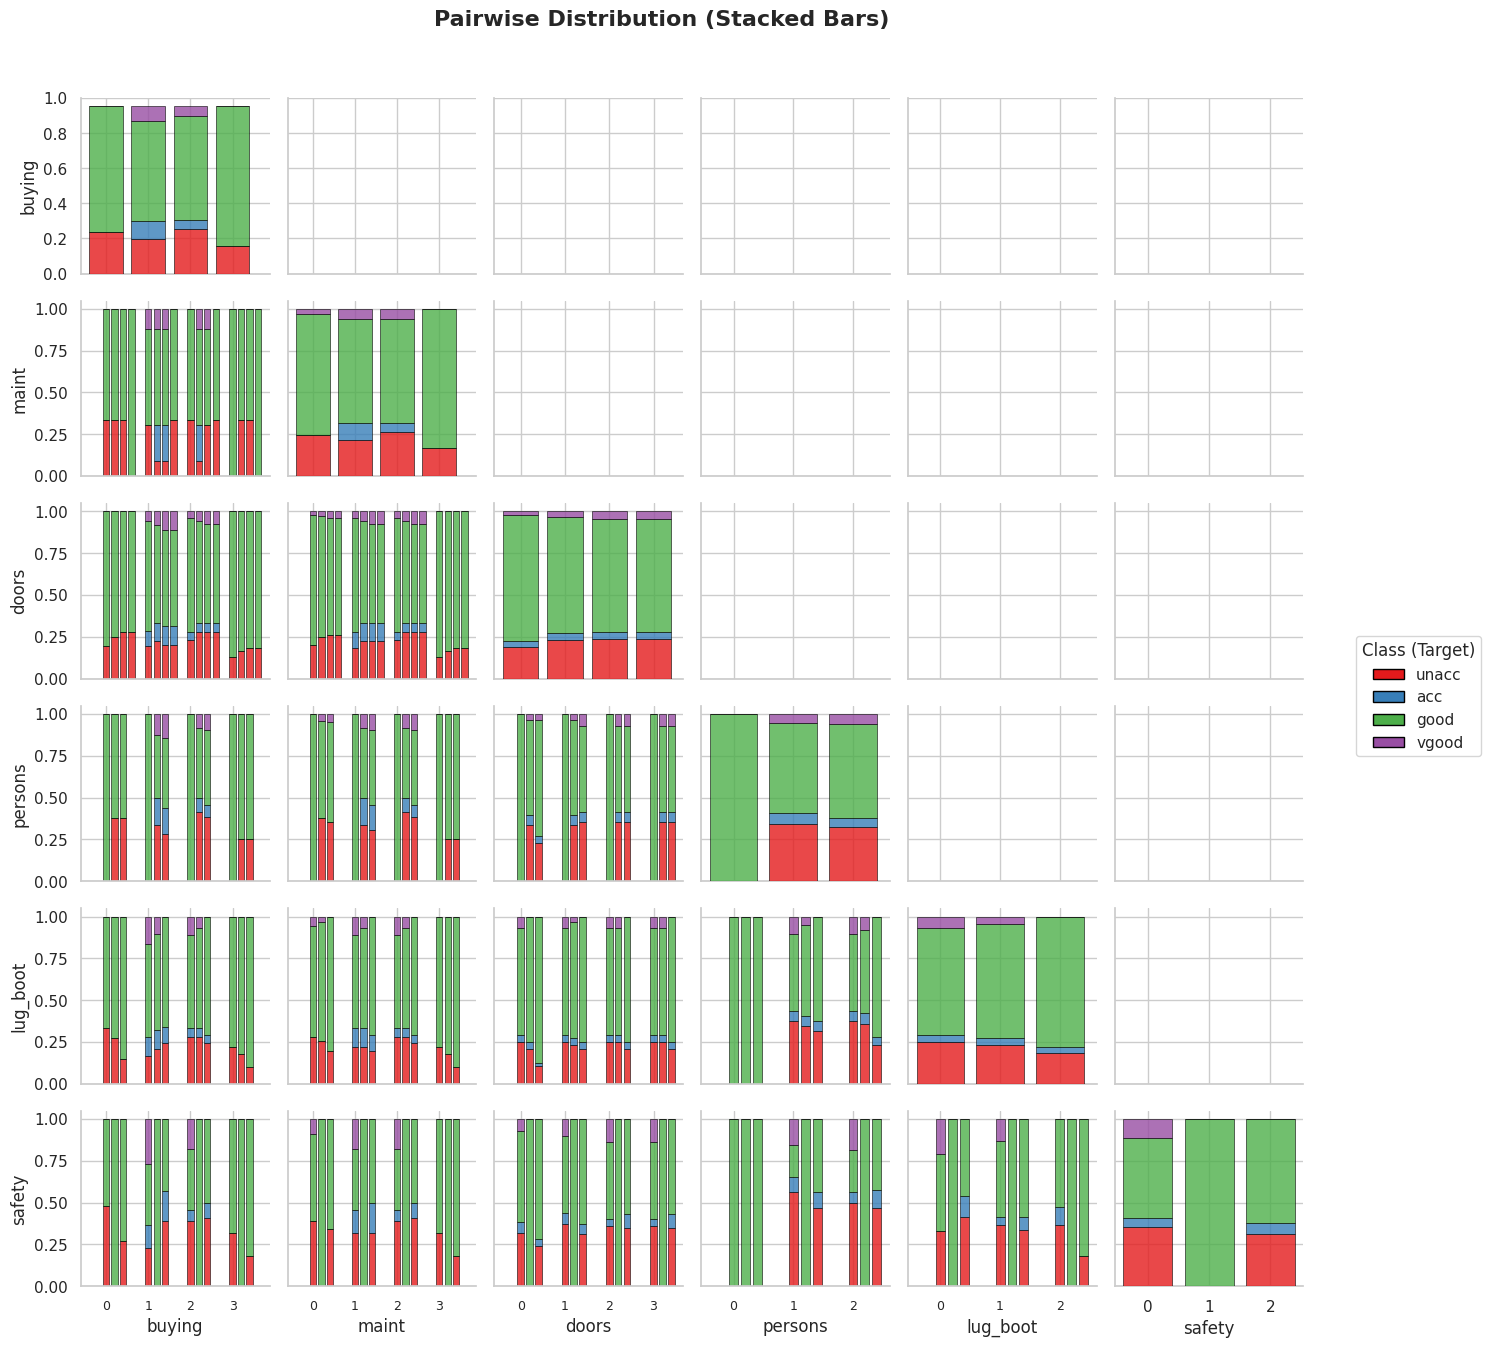

In [194]:
def stacked_bars_2d(
    x: np.ndarray,
    y: np.ndarray,
    hue: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует 2D stacked bars для поддиагонали PairGrid.
    
    Для каждой комбинации (x, y) показывает нормированное распределение классов.
    Столбцы группируются по y с небольшим смещением для наглядности.
    
    Args:
        x: массив значений признака по оси X
        y: массив значений признака по оси Y
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    temp_df: pd.DataFrame = pd.DataFrame({'x': x, 'y': y, 'hue': hue})
    grouped: pd.DataFrame = temp_df.groupby(['x', 'y', 'hue']).size().unstack(fill_value=0)
    normalized: pd.DataFrame = grouped.div(grouped.sum(axis=1), axis=0)
    
    x_positions: List = sorted(temp_df['x'].unique())
    y_positions: List = sorted(temp_df['y'].unique())
    
    for y_pos in y_positions:
        for x_pos in x_positions:
            if (x_pos, y_pos) in normalized.index:
                values: pd.Series = normalized.loc[(x_pos, y_pos)]
                bottom: float = 0.0
                for class_idx in sorted(values.index):
                    height: float = values[class_idx]
                    color: str = CUSTOM_PALETTE[class_idx]
                    ax.bar(
                        x_pos + y_pos * 0.2,
                        height,
                        bottom=bottom,
                        width=0.15,
                        color=color,
                        edgecolor='black',
                        linewidth=0.5,
                        alpha=0.8
                    )
                    bottom += height
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_positions, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(True)

def stacked_bars_1d(
    x: np.ndarray,
    hue: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует 1D stacked bars для диагонали PairGrid.
    
    Для каждого значения признака x показывает нормированное распределение классов.
    
    Args:
        x: массив значений признака
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    temp_df: pd.DataFrame = pd.DataFrame({'x': x, 'hue': hue})
    grouped: pd.DataFrame = temp_df.groupby(['x', 'hue']).size().unstack(fill_value=0)
    normalized: pd.DataFrame = grouped.div(grouped.sum(axis=1), axis=0)
    
    x_positions: List = sorted(temp_df['x'].unique())
    
    for x_pos in x_positions:
        if x_pos in normalized.index:
            values: pd.Series = normalized.loc[x_pos]
            bottom: float = 0.0
            for class_idx in sorted(values.index):
                height: float = values[class_idx]
                color: str = CUSTOM_PALETTE[class_idx]
                ax.bar(
                    x_pos,
                    height,
                    bottom=bottom,
                    width=0.8,
                    color=color,
                    edgecolor='black',
                    linewidth=0.5,
                    alpha=0.8
                )
                bottom += height
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_positions, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(True)

# Построение графика
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 14))

g: sns.PairGrid = sns.PairGrid(df_plot, hue=target_col, palette='Set1', height=2.2, corner=False)
g.map_lower(stacked_bars_2d)
g.map_diag(stacked_bars_1d)

# Создаём legend handles вручную
legend_handles: List[Patch] = [Patch(facecolor=color, edgecolor='black', label=label) 
                  for color, label in zip(CUSTOM_PALETTE, CLASS_LABELS)]

# Добавляем легенду через fig.legend()
g.fig.legend(handles=legend_handles, title='Class (Target)', 
             bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=11)

plt.suptitle("Pairwise Distribution (Stacked Bars)", y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Jitter Scatter Plot (Точечная диаграмма с шумом)

Показывает расположение каждого отдельного объекта в пространстве двух признаков. Цвет точки = целевой класс. 

Диагональ (1D): гистограмма распределения одного признака  
Под диагональю (2D): scatter plot  
Диагональ показывает маргинальное распределение каждого признака  
Под диагональю показывает совместное распределение пар признаков

<Figure size 1600x1400 with 0 Axes>

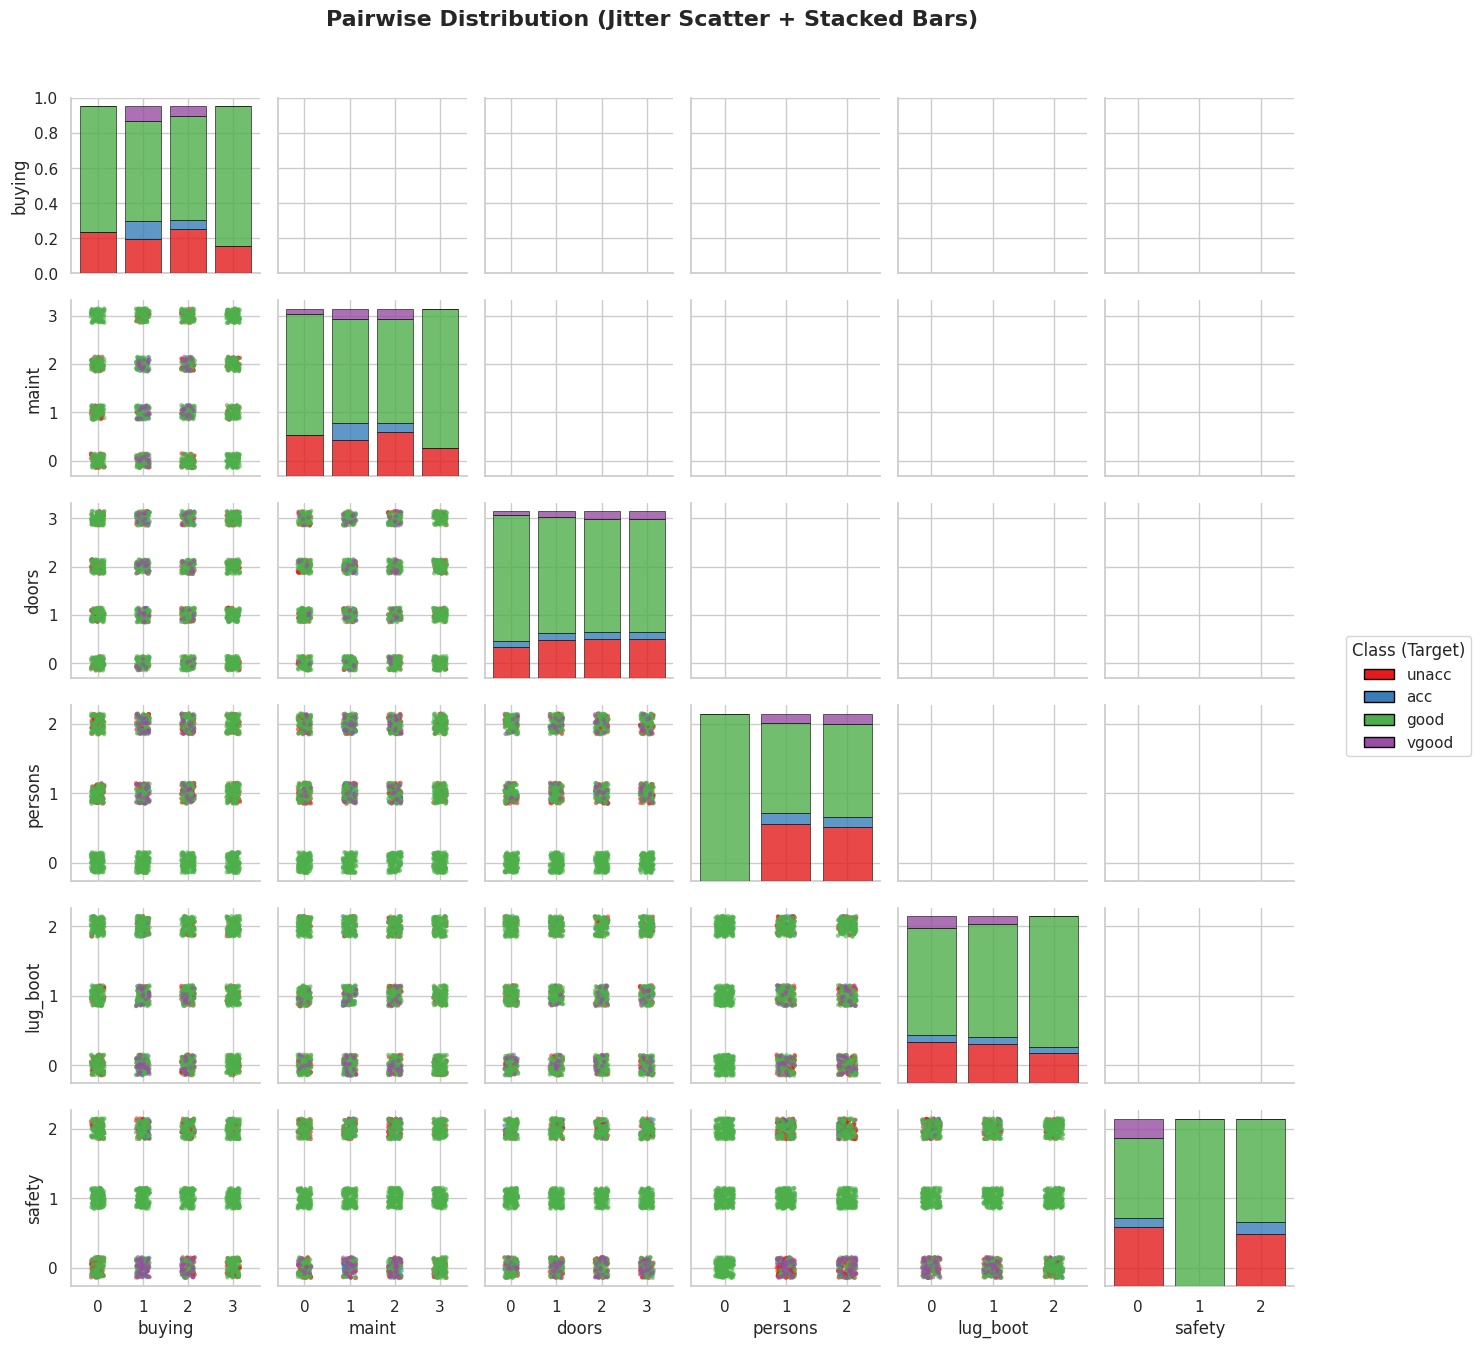

In [195]:
def jitter_scatter_clean(
    x: np.ndarray,
    y: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует scatter plot с jitter для поддиагонали PairGrid.
    
    Добавляет небольшой случайный шум к координатам для предотвращения
    наложения точек на категориальных данных.
    
    Args:
        x: массив значений признака по оси X
        y: массив значений признака по оси Y
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    # Добавляем равномерный шум в диапазоне [-0.15, 0.15]
    x_jitter: np.ndarray = x + np.random.uniform(-0.15, 0.15, size=len(x))
    y_jitter: np.ndarray = y + np.random.uniform(-0.15, 0.15, size=len(y))
    
    ax.scatter(
        x_jitter,
        y_jitter,
        alpha=0.6,
        s=10,
        edgecolor='none',
        **kwargs
    )
    ax.grid(True)


def stacked_bars_1d(
    x: np.ndarray,
    hue: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует 1D stacked bars для диагонали PairGrid.
    
    Для каждого значения признака x показывает нормированное распределение классов.
    
    Args:
        x: массив значений признака
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    temp_df: pd.DataFrame = pd.DataFrame({'x': x, 'hue': hue})
    grouped: pd.DataFrame = temp_df.groupby(['x', 'hue']).size().unstack(fill_value=0)
    normalized: pd.DataFrame = grouped.div(grouped.sum(axis=1), axis=0)
    
    x_positions: List = sorted(temp_df['x'].unique())
    
    for x_pos in x_positions:
        if x_pos in normalized.index:
            values: pd.Series = normalized.loc[x_pos]
            bottom: float = 0.0
            for class_idx in sorted(values.index):
                height: float = values[class_idx]
                color: str = CUSTOM_PALETTE[class_idx]
                ax.bar(
                    x_pos,
                    height,
                    bottom=bottom,
                    width=0.8,
                    color=color,
                    edgecolor='black',
                    linewidth=0.5,
                    alpha=0.8
                )
                bottom += height
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_positions, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3, axis='y')


# ==========================================
# Построение графика
# ==========================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 14))

g: sns.PairGrid = sns.PairGrid(
    df_plot,
    hue=target_col,
    palette=CUSTOM_PALETTE,
    height=2.2,
    corner=False
)
g.map_lower(jitter_scatter_clean)
g.map_diag(stacked_bars_1d)

# Создаём legend handles вручную
legend_handles: List[Patch] = [
    Patch(facecolor=color, edgecolor='black', label=label)
    for color, label in zip(CUSTOM_PALETTE, CLASS_LABELS)
]

# Добавляем легенду
g.fig.legend(
    handles=legend_handles,
    title='Class (Target)',
    bbox_to_anchor=(1.02, 0.5),
    loc='center left',
    fontsize=11
)

plt.suptitle(
    "Pairwise Distribution (Jitter Scatter + Stacked Bars)",
    y=1.02,
    fontsize=16,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

### Heatmap Dominance (Тепловая карта доминирования)

Показывет "чистоту" или сепарабельность классов в каждой ячейке. Цвет ячейки зависит от доли самого многочисленного класса в ней:  
🟩 Зеленый (1.0 или 100%): В этой ячейке все объекты принадлежат одному классу. Модель классифицирует эту область идеально.  
🟨 Желтый (~50-75%): Классы перемешаны, есть доминирующий, но есть и шум.  
🟥 Красный (0.25 или 25%): Все 4 класса представлены примерно поровну. Это зона максимальной неопределенности для модели.

<Figure size 1600x1400 with 0 Axes>

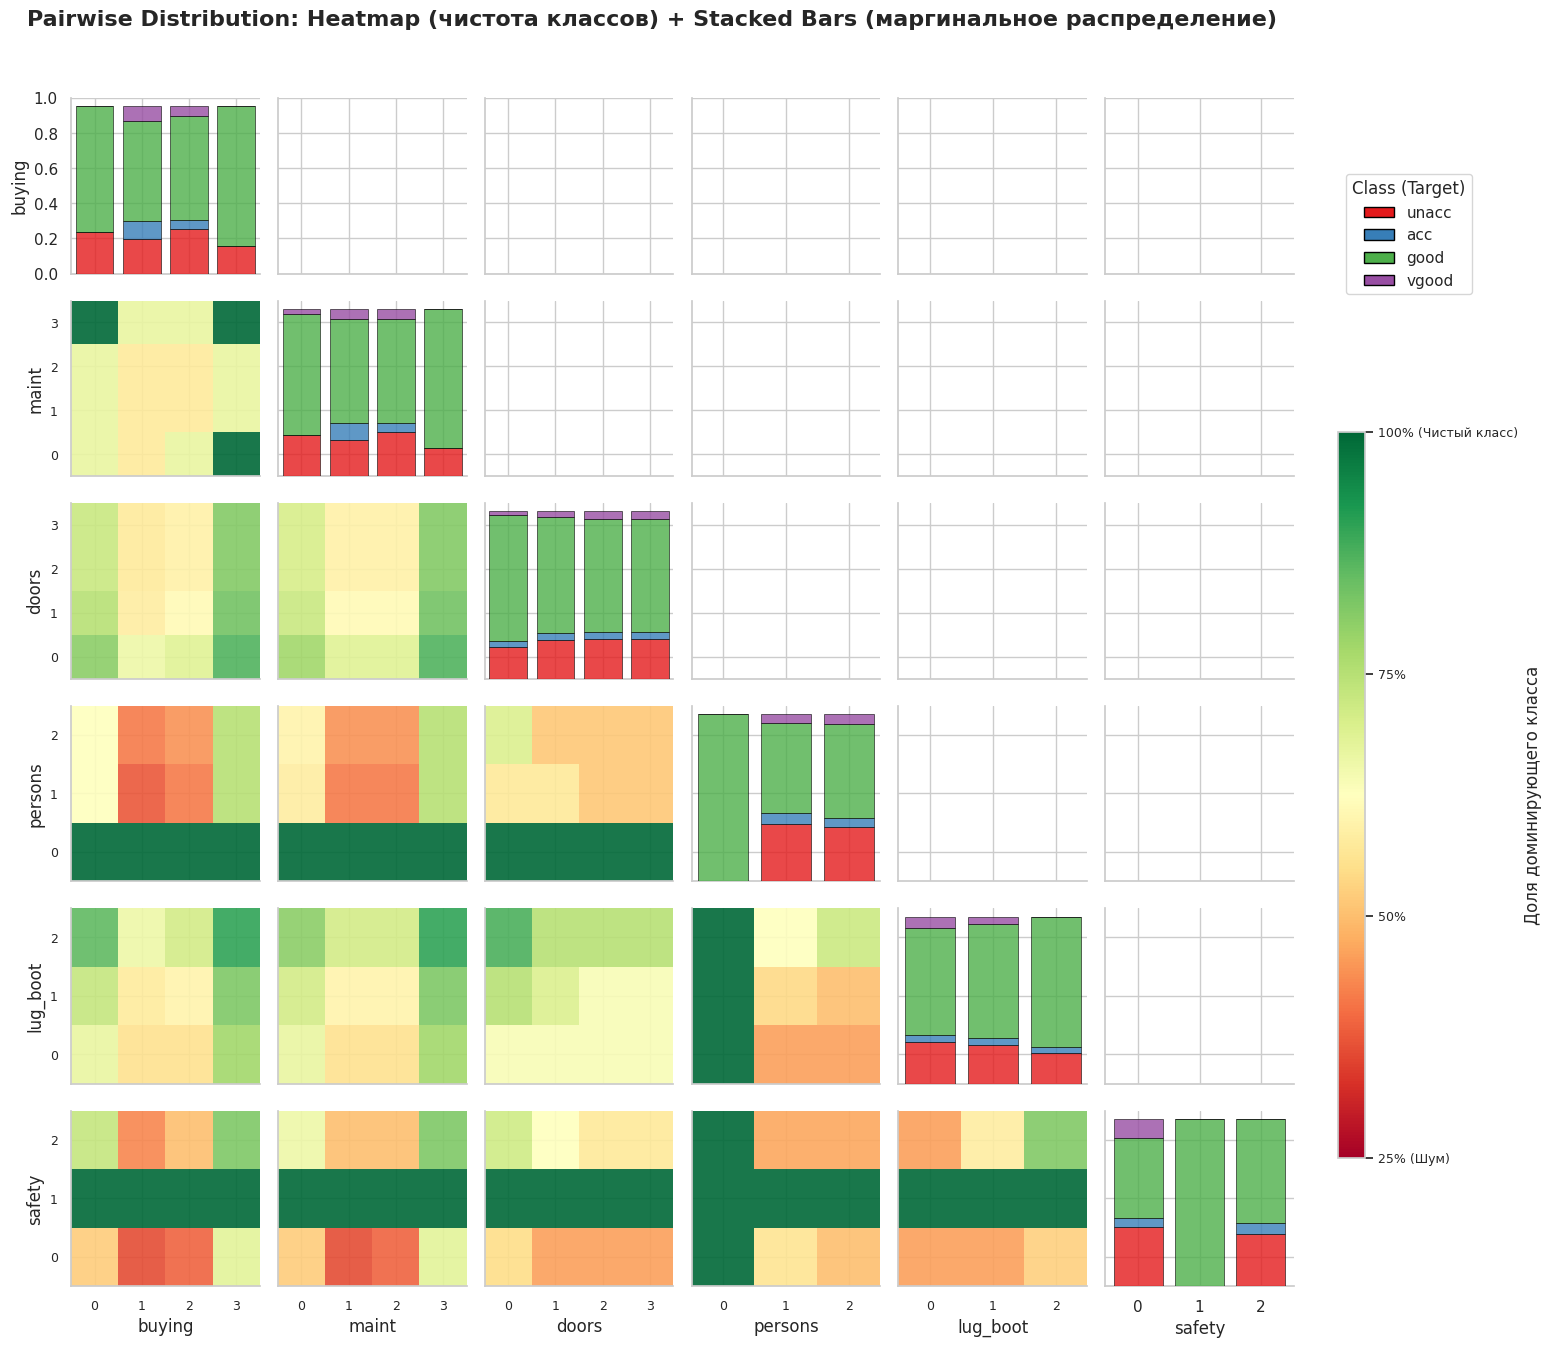

In [ ]:
def heatmap_dominance_clean(
    x: np.ndarray,
    y: np.ndarray,
    hue: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует 2D heatmap для поддиагонали PairGrid.
    
    Цвет показывает долю доминирующего класса в каждой ячейке (x, y).
    Зелёный = высокая чистота класса (легко классифицировать).
    Красный = классы перемешаны (сложно классифицировать).
    
    Args:
        x: массив значений признака по оси X
        y: массив значений признака по оси Y
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    temp_df: pd.DataFrame = pd.DataFrame({'x': x, 'y': y, 'hue': hue})
    grouped: pd.DataFrame = temp_df.groupby(['x', 'y', 'hue']).size().unstack(fill_value=0)
    
    # Вычисляем долю доминирующего класса
    total: pd.Series = grouped.sum(axis=1)
    dominant_class_count: pd.Series = grouped.max(axis=1)
    dominance_ratio: pd.Series = dominant_class_count / total
    
    x_unique: List = sorted(temp_df['x'].unique())
    y_unique: List = sorted(temp_df['y'].unique())
    
    pivot_df: pd.DataFrame = dominance_ratio.reset_index(name='ratio')
    pivot_table: pd.DataFrame = pivot_df.pivot(
        index='y', columns='x', values='ratio'
    ).reindex(index=y_unique, columns=x_unique, fill_value=0)
    
    ax.pcolormesh(
        np.arange(len(x_unique) + 1) - 0.5,
        np.arange(len(y_unique) + 1) - 0.5,
        pivot_table.values,
        cmap='RdYlGn',
        shading='flat',
        alpha=0.9,
        vmin=0.25,
        vmax=1.0
    )
    
    ax.set_xticks(np.arange(len(x_unique)))
    ax.set_xticklabels(x_unique, fontsize=9)
    ax.set_yticks(np.arange(len(y_unique)))
    ax.set_yticklabels(y_unique, fontsize=9)
    ax.grid(True)


def stacked_bars_1d(
    x: np.ndarray,
    hue: np.ndarray,
    **kwargs: Any
) -> None:
    """
    Рисует 1D stacked bars для диагонали PairGrid.
    
    Для каждого значения признака x показывает нормированное распределение классов.
    
    Args:
        x: массив значений признака
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    ax: plt.Axes = kwargs.get('ax', plt.gca())
    
    temp_df: pd.DataFrame = pd.DataFrame({'x': x, 'hue': hue})
    grouped: pd.DataFrame = temp_df.groupby(['x', 'hue']).size().unstack(fill_value=0)
    normalized: pd.DataFrame = grouped.div(grouped.sum(axis=1), axis=0)
    
    x_positions: List = sorted(temp_df['x'].unique())
    
    for x_pos in x_positions:
        if x_pos in normalized.index:
            values: pd.Series = normalized.loc[x_pos]
            bottom: float = 0.0
            for class_idx in sorted(values.index):
                height: float = values[class_idx]
                color: str = CUSTOM_PALETTE[class_idx]
                ax.bar(
                    x_pos,
                    height,
                    bottom=bottom,
                    width=0.8,
                    color=color,
                    edgecolor='black',
                    linewidth=0.5,
                    alpha=0.8
                )
                bottom += height
    
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_positions, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3, axis='y')


# ==========================================
# Построение графика
# ==========================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 14))

g: sns.PairGrid = sns.PairGrid(
    df_plot,
    hue=target_col,
    palette=CUSTOM_PALETTE,
    height=2.2,
    corner=False
)

g.map_lower(heatmap_dominance_clean)
g.map_diag(stacked_bars_1d)

# ==========================================
# 1. Легенда для классов (Stacked Bars)
# ==========================================
class_handles: List[Patch] = [
    Patch(facecolor=color, edgecolor='black', label=label)
    for color, label in zip(CUSTOM_PALETTE, CLASS_LABELS)
]
g.fig.legend(
    handles=class_handles,
    title='Class (Target)',
    bbox_to_anchor=(1.02, 0.85),
    loc='center left',
    fontsize=11
)

# ==========================================
# 2. Colorbar для Heatmap (доля доминирующего класса)
# ==========================================
cbar_ax: plt.Axes = g.fig.add_axes([1.02, 0.15, 0.02, 0.55])
sm: plt.cm.ScalarMappable = plt.cm.ScalarMappable(
    cmap='RdYlGn',
    norm=plt.Normalize(vmin=0.25, vmax=1.0)
)
sm.set_array([])
cbar = g.fig.colorbar(sm, cax=cbar_ax, label='Доля доминирующего класса')
cbar.set_ticks([0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['25% (Шум)', '50%', '75%', '100% (Чистый класс)'], fontsize=9)

# ==========================================
# Заголовок и финальная компоновка
# ==========================================
plt.suptitle(
    "Pairwise Distribution: Heatmap (чистота классов) + Stacked Bars (маргинальное распределение)",
    y=1.02,
    fontsize=16,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

### Heatmap Count (Тепловая карта количества)

Показывает абсолютное количество объектов в каждой ячейке (x, y), игнорируя их классовую принадлежность.

<Figure size 1400x1200 with 0 Axes>

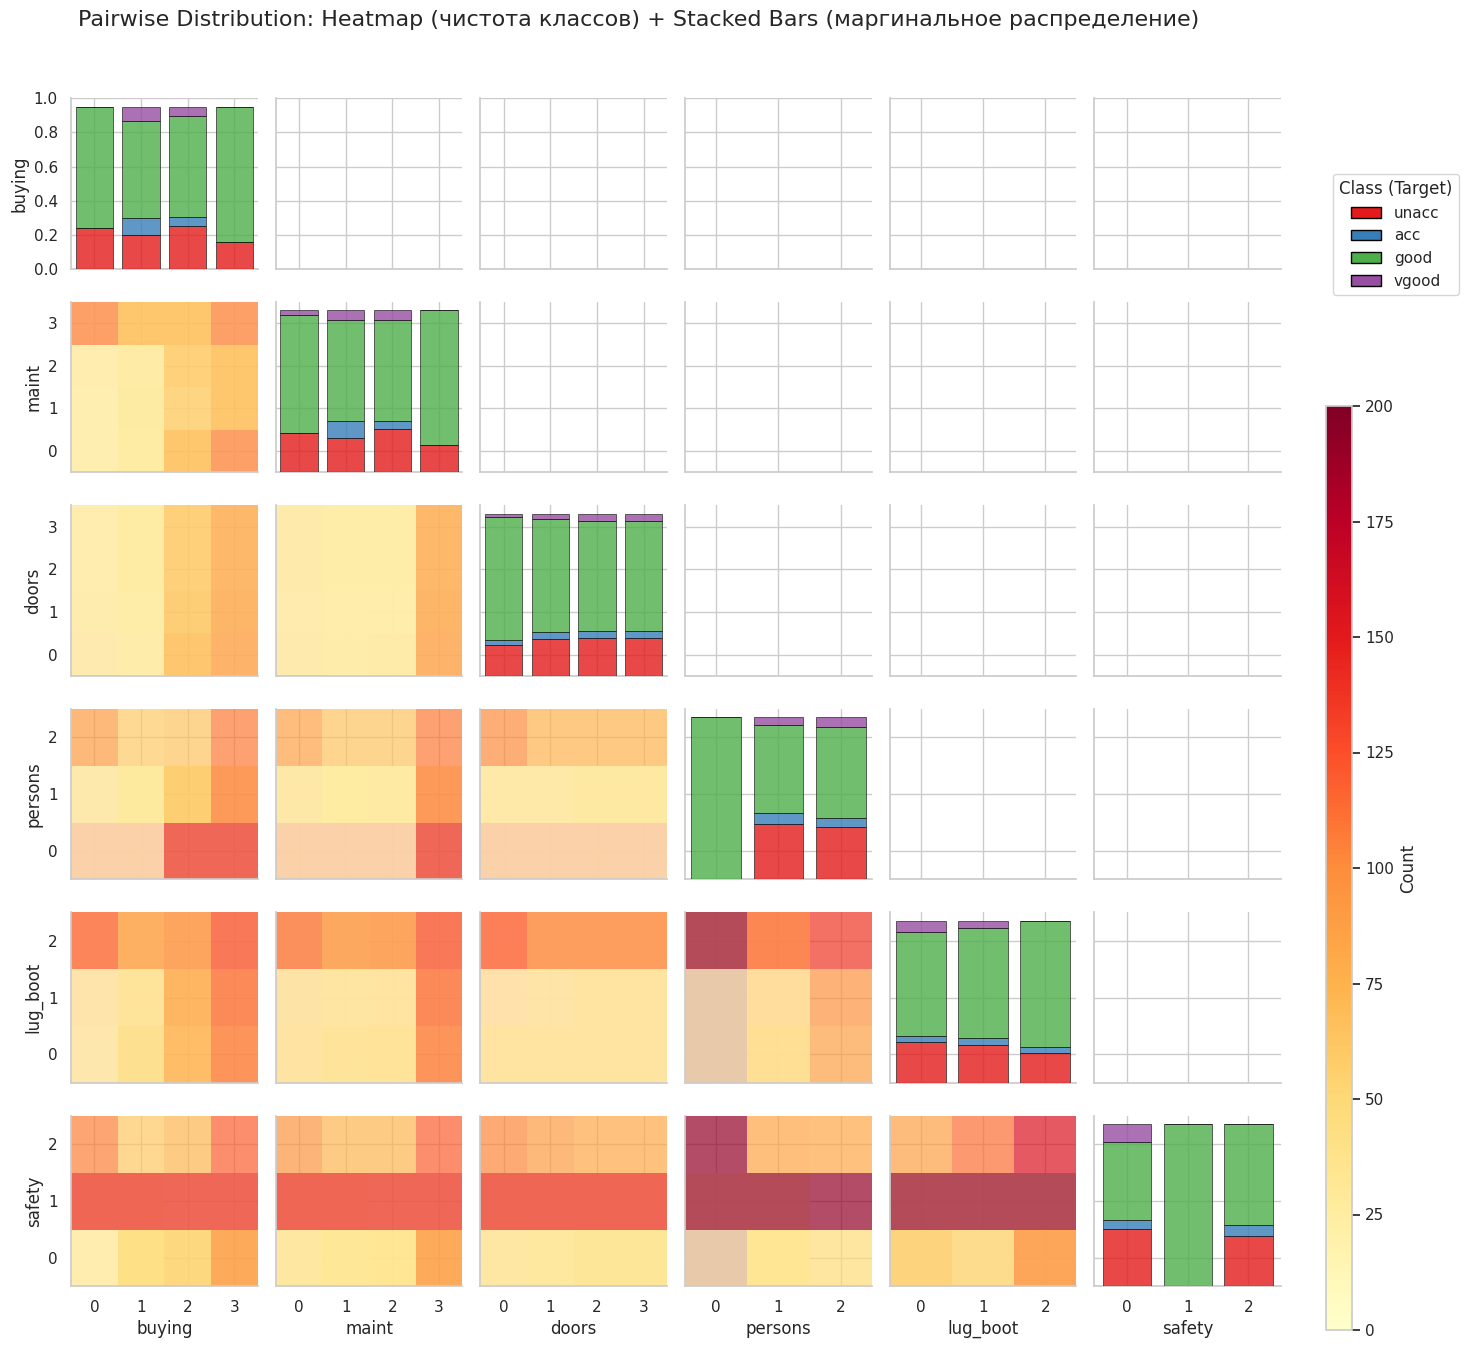

In [ ]:
def categorical_heatmap(
    x: np.ndarray,
    y: np.ndarray,
    **kwargs: Any):
    """
    Рисует 2D heatmap для поддиагонали PairGrid.
    
    Цвет показывает долю доминирующего класса в каждой ячейке (x, y).
    Зелёный = высокая чистота класса (легко классифицировать).
    Красный = классы перемешаны (сложно классифицировать).
    
    Args:
        x: массив значений признака по оси X
        y: массив значений признака по оси Y
        hue: массив меток классов
        **kwargs: дополнительные аргументы (включает 'ax' от PairGrid)
    """
    x_unique: np.ndarray = np.unique(x)
    y_unique: np.ndarray = np.unique(y)
    
    x_bins: np.ndarray = np.arange(len(x_unique) + 1) - 0.5
    y_bins: np.ndarray = np.arange(len(y_unique) + 1) - 0.5
    
    hist, xedges, yedges = np.histogram2d(x, y, bins=[x_bins, y_bins])
    
    plt.pcolormesh(
        xedges, yedges, hist.T,
        cmap='YlOrRd',
        shading='flat',
        alpha=0.7,
        vmin=0, vmax=200
    )

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 12))

g: sns.PairGrid = sns.PairGrid(df_plot, hue=target_col, palette=CUSTOM_PALETTE, height=2.2, corner=False)

g.map_lower(categorical_heatmap)
g.map_diag(stacked_bars_1d)

class_handles: List[Patch] = [
    Patch(facecolor=color, edgecolor='black', label=label)
    for color, label in zip(CUSTOM_PALETTE, CLASS_LABELS)
]
g.fig.legend(
    handles=class_handles,
    title='Class (Target)',
    bbox_to_anchor=(1.02, 0.85),   # Верхняя правая часть
    loc='center left',
    fontsize=11
)

cbar_ax: plt.Axes = g.fig.add_axes([1.02, 0.02, 0.02, 0.7])  # [left, bottom, width, height]
sm: plt.cm.ScalarMappable = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=0, vmax=200))
sm.set_array([])
g.fig.colorbar(sm, cax=cbar_ax, label='Count')

plt.suptitle("Pairwise Distribution: Heatmap (чистота классов) + Stacked Bars (маргинальное распределение)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### Stacked Bar Charts (Категориальные графики)

### Пара "safety" и "persons"

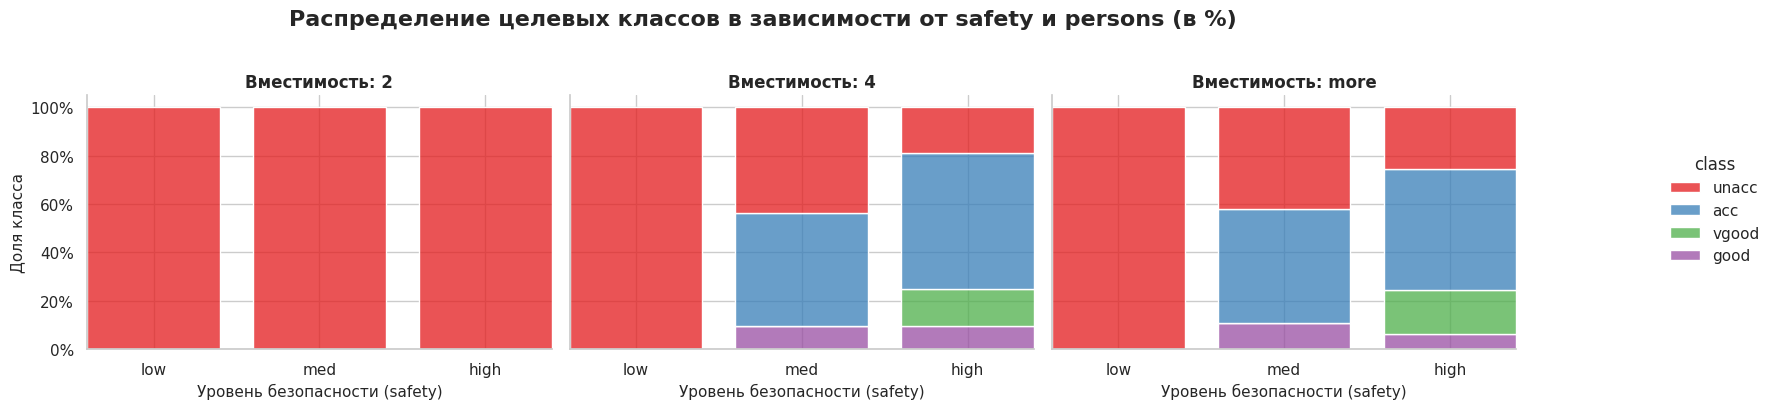

In [ ]:
g: sns.PairGrid = sns.displot(
    data=df,
    x='safety',
    hue='class',
    multiple='fill',
    col='persons',
    col_wrap=3,
    palette='Set1',
    shrink=0.8,
    discrete=True,
    height=4,
    aspect=1.2
)

for ax in g.axes.flatten():
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
    ax.set_xlabel('Уровень безопасности (safety)', fontsize=11)
    ax.set_ylabel('Доля класса', fontsize=11)
    ax.set_ylim(0, 1.05)

g.set_titles("Вместимость: {col_name}", fontsize=12, fontweight='bold')

g.legend.set_bbox_to_anchor((1.15, 0.5))  # (x, y) - x>1 выносит вправо
g.legend.set_title('class')
plt.subplots_adjust(right=0.85)

plt.suptitle(
    'Распределение целевых классов в зависимости от safety и persons (в %)',
    fontsize=16, 
    fontweight='bold', 
    y=1.02
)
plt.tight_layout()
plt.show()

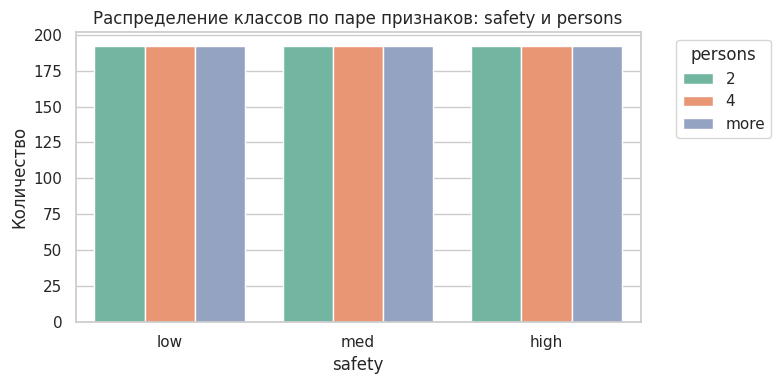

In [133]:
feat1_1, feat2_1 = 'safety', 'persons'

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=feat1_1, hue=feat2_1, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_1} и {feat2_1}')
plt.xlabel(feat1_1)
plt.ylabel('Количество')
plt.legend(title=feat2_1, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Пара "safety" и "buying"

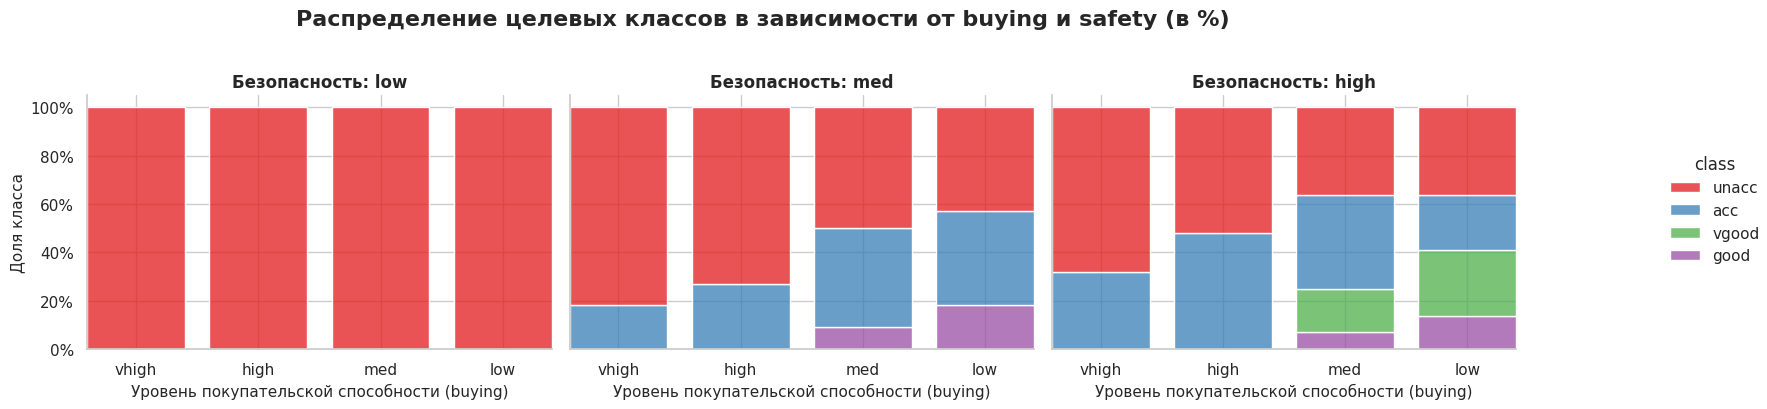

In [ ]:
g: sns.PairGrid = sns.displot(
    data=df,
    x='buying',
    hue='class',
    multiple='fill',
    col='safety',
    col_wrap=3,
    palette='Set1',
    shrink=0.8,
    discrete=True,
    height=4,
    aspect=1.2
)

for ax in g.axes.flatten():
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
    ax.set_xlabel('Уровень покупательской способности (buying)', fontsize=11)
    ax.set_ylabel('Доля класса', fontsize=11)
    ax.set_ylim(0, 1.05)

g.set_titles("Безопасность: {col_name}", fontsize=12, fontweight='bold')

g.legend.set_bbox_to_anchor((1.15, 0.5))  # (x, y) - x>1 выносит вправо
g.legend.set_title('class')
plt.subplots_adjust(right=0.85)

plt.suptitle(
    'Распределение целевых классов в зависимости от buying и safety (в %)',
    fontsize=16, 
    fontweight='bold', 
    y=1.02
)
plt.tight_layout()
plt.show()

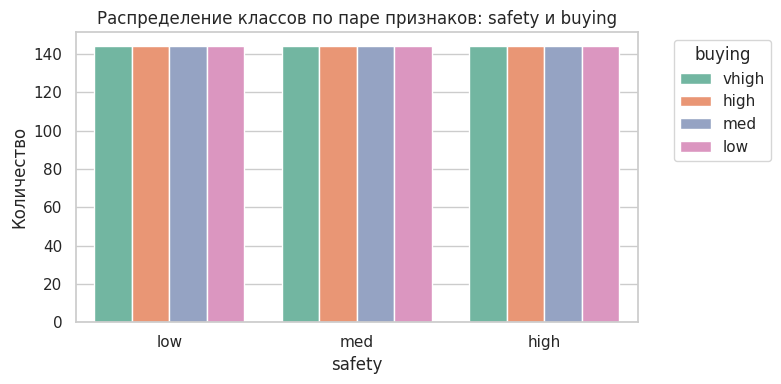

In [135]:
feat1_2, feat2_2 = 'safety', 'buying'

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=feat1_2, hue=feat2_2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_2} и {feat2_2}')
plt.xlabel(feat1_2)
plt.ylabel('Количество')
plt.legend(title=feat2_2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Применение кодирования к DataFrame

In [136]:
df_encoded: pd.DataFrame = df.copy()
for col, mapping in ordinal_mappings.items():
    df_encoded[col] = df_encoded[col].map(mapping)

In [137]:
df_encoded

,buying,maint,doors,persons,lug_boot,safety,class
0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0
2,0,0,0,0,0,2,0
3,0,0,0,0,1,0,0
4,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...
1723,3,3,3,2,1,1,2
1724,3,3,3,2,1,2,3
1725,3,3,3,2,2,0,0
1726,3,3,3,2,2,1,2


### Выделение матрицы признаков и целевой переменной из encoded DataFrame

In [138]:
X_all: pd.DataFrame = df_encoded.drop(columns=[target_col])
y: pd.Series = df_encoded[target_col]

In [139]:
X_all

,buying,maint,doors,persons,lug_boot,safety
0,0,0,0,0,0,0
1,0,0,0,0,0,1
2,0,0,0,0,0,2
3,0,0,0,0,1,0
4,0,0,0,0,1,1
...,...,...,...,...,...,...
1723,3,3,3,2,1,1
1724,3,3,3,2,1,2
1725,3,3,3,2,2,0
1726,3,3,3,2,2,1


In [140]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1723    2
1724    3
1725    0
1726    2
1727    3
Name: class, Length: 1728, dtype: int64

### Выбираем две переменные для визуализации границ

#### Сравним все 15 пар. Для этого выделим переменные вида X_2d_1, X_2d_2, ..., X_2d_15

In [141]:
X_2d_1: pd.DataFrame = df_encoded[[feat1_1, feat2_1]]
X_2d_1

,safety,persons
0,0,0
1,1,0
2,2,0
3,0,0
4,1,0
...,...,...
1723,1,2
1724,2,2
1725,0,2
1726,1,2


In [142]:
X_2d_6: pd.DataFrame = df_encoded[[feat1_2, feat2_2]]
X_2d_6

,safety,buying
0,0,0
1,1,0
2,2,0
3,0,0
4,1,0
...,...,...
1723,1,3
1724,2,3
1725,0,3
1726,1,3


### Инициализация моделей

### Вариант 1: ленивый. Возьмём словарь моделей со статичными параметрами

In [143]:
models: Dict[str, Any] = {
    "Линейный дискриминант (LDA)": LinearDiscriminantAnalysis(),
    "Квадратичный дискриминант (QDA)": QuadraticDiscriminantAnalysis(reg_param=0.1, tol=1e-7),
    "Логистическая регрессия": LogisticRegression(
        max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, tol=1e-7
    ),
    "SVM (линейное ядро)": SVC(kernel='linear', probability=True, random_state=RANDOM_STATE, tol=1e-7),
    "SVM (квадратичное ядро)": SVC(kernel='poly', degree=2, probability=True, random_state=RANDOM_STATE, tol=1e-3)
}

### Визуализация разделяющих кривых для 2D подпространства

#### Сравнение 1 (по признакам 'safety' и 'persons')

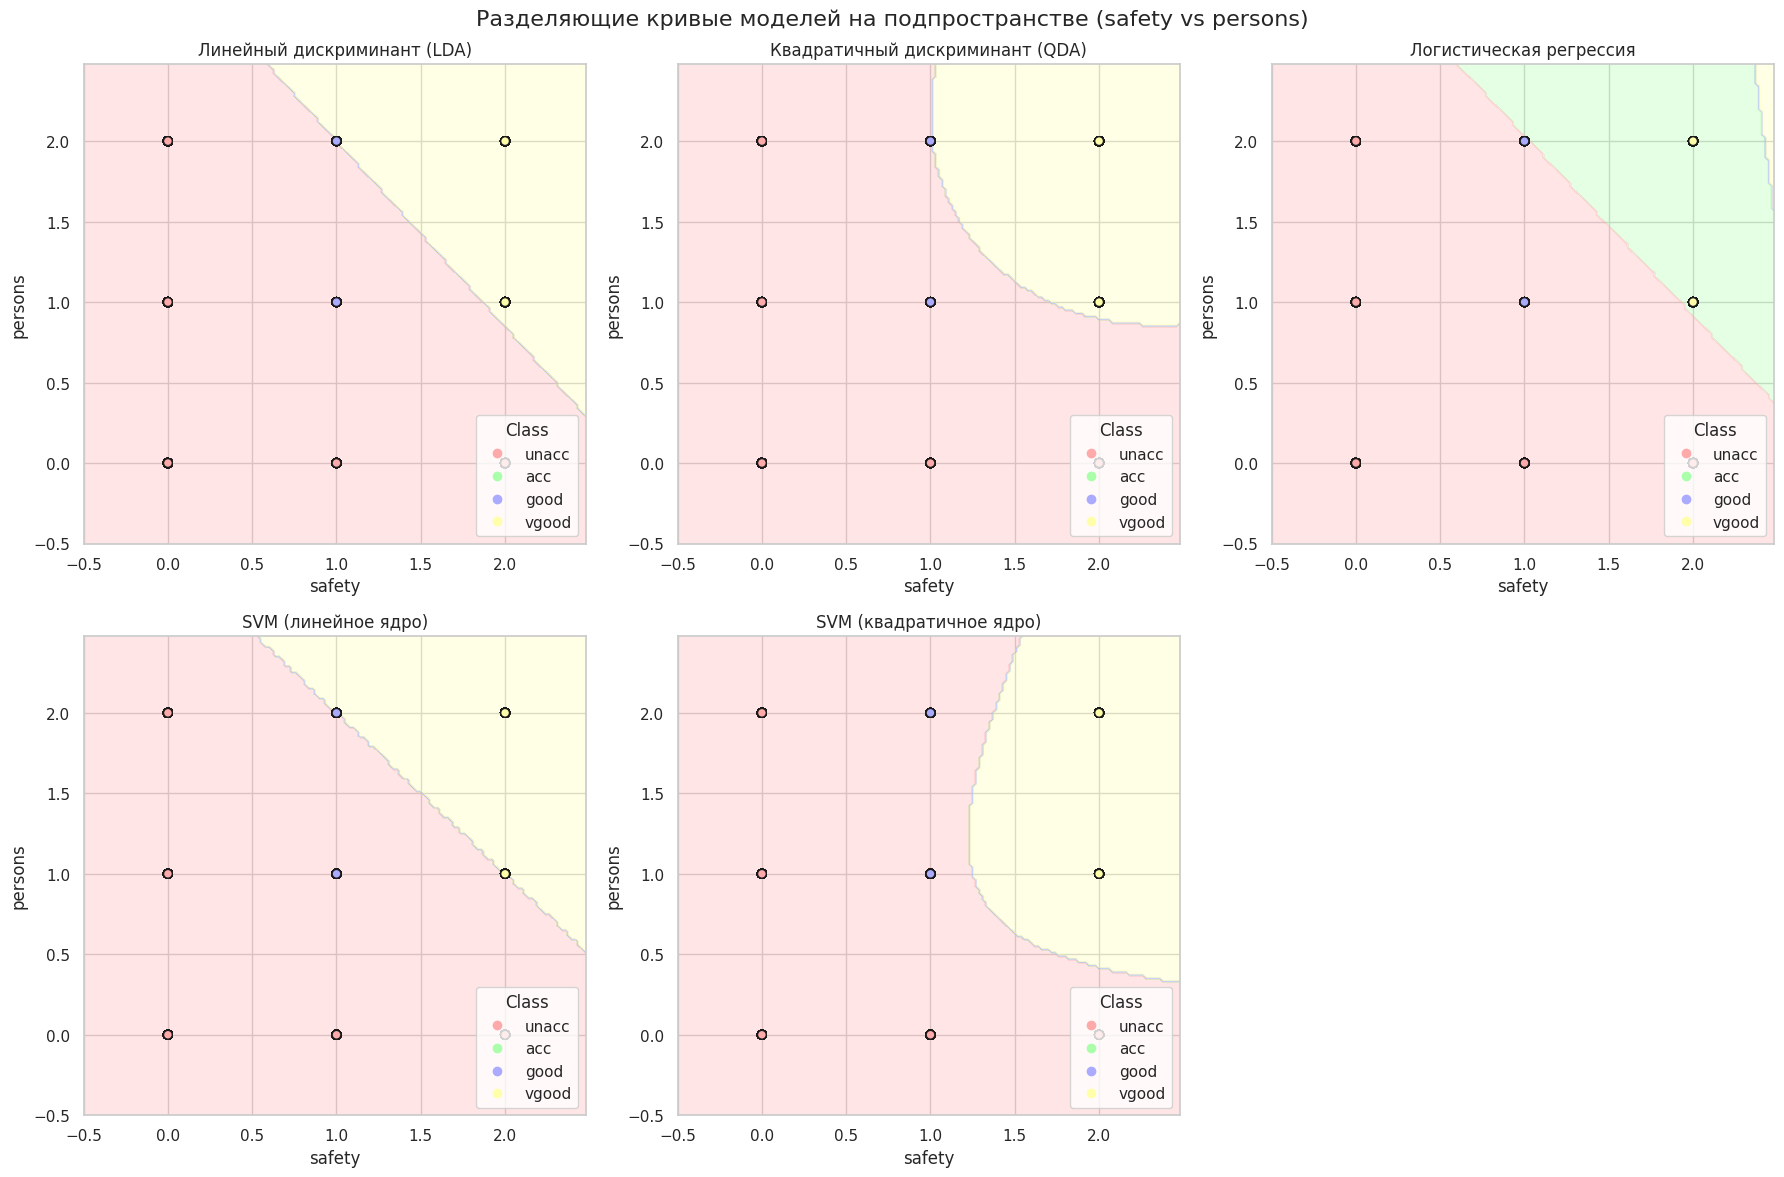

In [ ]:
h: float = 0.02
x_min, x_max = X_2d_1[feat1_1].min() - 0.5, X_2d_1[feat1_1].max() + 0.5
y_min, y_max = X_2d_1[feat2_1].min() - 0.5, X_2d_1[feat2_1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_1, y)
        
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_1[feat1_1], X_2d_1[feat2_1], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)
        ax.set_title(name)
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)

axes[5].axis('off')
plt.suptitle("Разделяющие кривые моделей на подпространстве (safety vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

#### Сравнение 2 (по признакам 'buying' и 'safety')

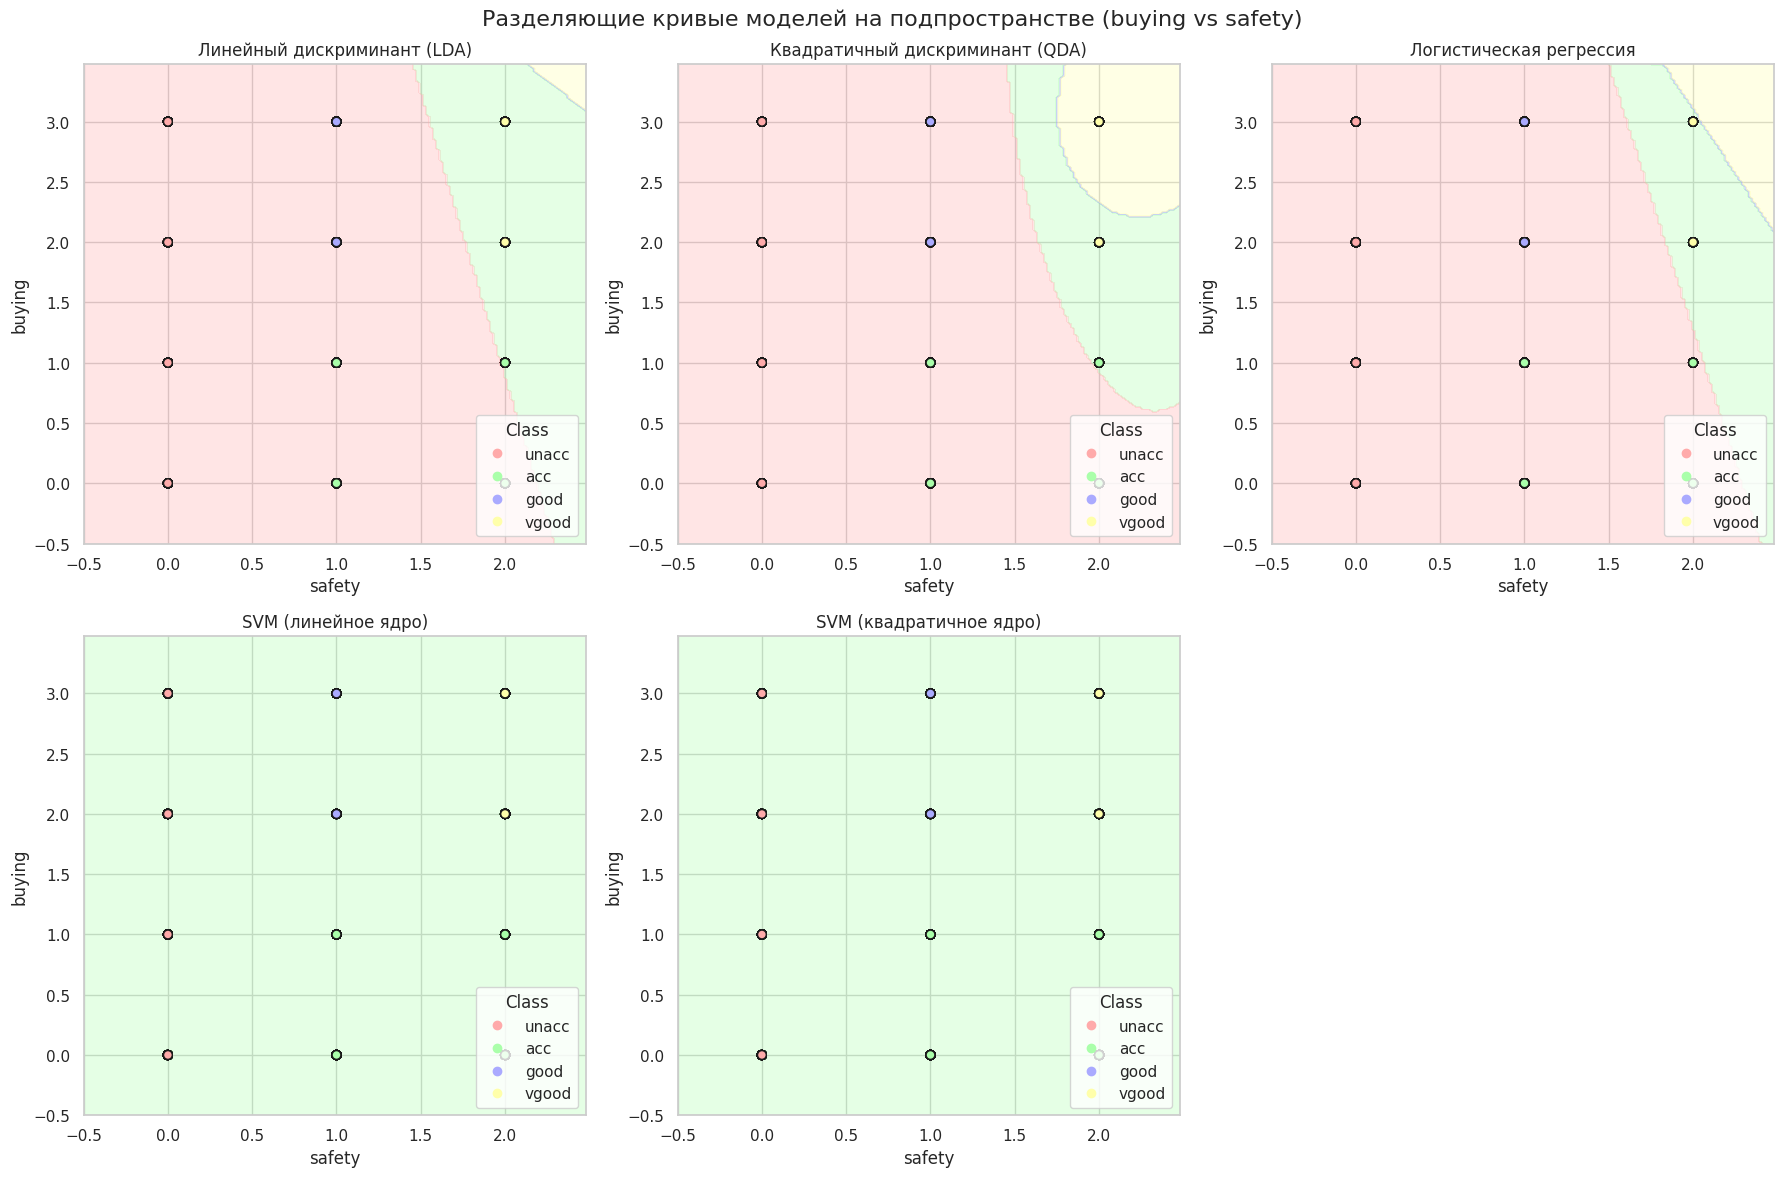

In [ ]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_6[feat1_2].min() - 0.5, X_2d_6[feat1_2].max() + 0.5
y_min, y_max = X_2d_6[feat2_2].min() - 0.5, X_2d_6[feat2_2].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_6, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_6[feat1_2], X_2d_6[feat2_2], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)
        ax.set_title(name)
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)

axes[5].axis('off')
plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

## 3. Оптимизация гиперпараметров (Optuna)
### Был проведен поиск оптимальных гиперпараметров для каждой модели (50 итераций на модель). 
**Ключевые наблюдения:**
- **SVM (poly)** показал наибольший прирост качества (+0.030609), достигнув почти идеальной точности благодаря подбору степени полинома (`degree=3`) и коэффициента регуляризации `C` = 45.04017911989709.
- **QDA** также улучшил свои показатели за счет точной настройки параметра регуляризации `reg_param`, что стабилизировало обращение ковариационных матриц для миноритарных классов.
- Линейные модели (LDA, Logistic Regression) достигли своего "потолка" производительности, так как их ограничения связаны с линейной природой данных, а не с гиперпараметрами.

### Вариант 2: Подбор гиперпараметров через Optuna

In [146]:
def objective_lda(trial: optuna.Trial) -> float:
    """Оптимизация параметров LDA"""
    solver: str = trial.suggest_categorical('solver', ['svd', 'lsqr', 'eigen'])
    
    # shrinkage доступен только для solver='lsqr'
    if solver == 'lsqr':
        shrinkage = trial.suggest_categorical('shrinkage', [None, 'auto'])
        if shrinkage == 'auto':
            model = LinearDiscriminantAnalysis(solver=solver, shrinkage=shrinkage)
        else:
            model = LinearDiscriminantAnalysis(solver=solver)
    else:
        model = LinearDiscriminantAnalysis(solver=solver)
    
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_qda(trial: optuna.Trial) -> float:
    """Оптимизация параметров QDA"""
    reg_param: float = trial.suggest_float('reg_param', 1e-3, 1.0, log=True)
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    
    model = QuadraticDiscriminantAnalysis(reg_param=reg_param, tol=tol)
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_logistic(trial: optuna.Trial) -> float:
    """Оптимизация параметров Logistic Regression"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    solver: str = trial.suggest_categorical('solver', ['lbfgs', 'newton-cg', 'sag', 'saga'])
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = LogisticRegression(
        C=C, 
        solver=solver, 
        max_iter=1000, 
        tol=tol, 
        class_weight=class_weight,
        random_state=RANDOM_STATE
    )
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_svm_linear(trial: optuna.Trial) -> float:
    """Оптимизация параметров SVM с линейным ядром"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = SVC(
        kernel='linear', 
        C=C, 
        tol=tol,
        class_weight=class_weight,
        probability=True, 
        random_state=RANDOM_STATE
    )
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_svm_poly(trial: optuna.Trial) -> float:
    """Оптимизация параметров SVM с полиномиальным ядром"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    degree: int = trial.suggest_int('degree', 2, 5)
    gamma: str = trial.suggest_categorical('gamma', ['scale', 'auto'])
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = SVC(
        kernel='poly', 
        C=C, 
        degree=degree,
        gamma=gamma,
        tol=tol,
        class_weight=class_weight,
        probability=True, 
        random_state=RANDOM_STATE
    )
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

### Оптимизация гиперпараметров с помощью Optuna

In [147]:
optimization_results: Dict[str, Dict[str, optuna.Study]] = {}

# LDA
print("\n📊 Оптимизация LDA...")
study_lda: optuna.Study = optuna.create_study(direction='maximize')
for _ in tqdm(range(50), desc="LDA optimization", colour='green'):
    study_lda.optimize(objective_lda, n_trials=1, show_progress_bar=False)
study_lda.optimize(objective_lda, n_trials=50, show_progress_bar=True)
optimization_results['LDA'] = {
    'best_params': study_lda.best_params,
    'best_score': study_lda.best_value
}
print(f"   ✅ Лучшая accuracy: {study_lda.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_lda.best_params}")

# QDA
print("\n📊 Оптимизация QDA...")
study_qda: optuna.Study = optuna.create_study(direction='maximize')
for _ in tqdm(range(50), desc="LDA optimization", colour='green'):
    study_qda.optimize(objective_qda, n_trials=1, show_progress_bar=False)
study_qda.optimize(objective_qda, n_trials=50, show_progress_bar=True)
optimization_results['QDA'] = {
    'best_params': study_qda.best_params,
    'best_score': study_qda.best_value
}
print(f"   ✅ Лучшая accuracy: {study_qda.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_qda.best_params}")

# Logistic Regression
print("\n📊 Оптимизация Logistic Regression...")
study_lr: optuna.Study = optuna.create_study(direction='maximize')
study_lr.optimize(objective_logistic, n_trials=50, show_progress_bar=True)
optimization_results['Logistic'] = {
    'best_params': study_lr.best_params,
    'best_score': study_lr.best_value
}
print(f"   ✅ Лучшая accuracy: {study_lr.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_lr.best_params}")

# SVM Linear
print("\n📊 Оптимизация SVM (linear)...")
study_svm_lin: optuna.Study = optuna.create_study(direction='maximize')
study_svm_lin.optimize(objective_svm_linear, n_trials=50, show_progress_bar=True)
optimization_results['SVM_linear'] = {
    'best_params': study_svm_lin.best_params,
    'best_score': study_svm_lin.best_value
}
print(f"   ✅ Лучшая accuracy: {study_svm_lin.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_svm_lin.best_params}")

# SVM Poly
print("\n📊 Оптимизация SVM (poly)...")
study_svm_poly: optuna.Study = optuna.create_study(direction='maximize')
study_svm_poly.optimize(objective_svm_poly, n_trials=50, show_progress_bar=True)
optimization_results['SVM_poly'] = {
    'best_params': study_svm_poly.best_params,
    'best_score': study_svm_poly.best_value
}
print(f"   ✅ Лучшая accuracy: {study_svm_poly.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_svm_poly.best_params}")


📊 Оптимизация LDA...


Best trial: 5. Best value: 0.767347: 100%|██████████| 50/50 [00:01<00:00, 48.31it/s]


   ✅ Лучшая accuracy: 0.7673
   ✅ Лучшие параметры: {'solver': 'lsqr', 'shrinkage': 'auto'}

📊 Оптимизация QDA...


Best trial: 22. Best value: 0.848986: 100%|██████████| 50/50 [00:00<00:00, 70.89it/s]


   ✅ Лучшая accuracy: 0.8490
   ✅ Лучшие параметры: {'reg_param': 0.03707992473132309, 'tol': 2.0206503708847083e-08}

📊 Оптимизация Logistic Regression...


  0%|          | 0/50 [00:00<?, ?it/s]

Best trial: 14. Best value: 0.763872: 100%|██████████| 50/50 [00:10<00:00,  4.83it/s]


   ✅ Лучшая accuracy: 0.7639
   ✅ Лучшие параметры: {'C': 0.16525824015029716, 'solver': 'sag', 'tol': 2.0367742428900335e-06, 'class_weight': None}

📊 Оптимизация SVM (linear)...


Best trial: 13. Best value: 0.77722: 100%|██████████| 50/50 [00:31<00:00,  1.57it/s]


   ✅ Лучшая accuracy: 0.7772
   ✅ Лучшие параметры: {'C': 0.0396003764202449, 'tol': 1.1364305930767422e-06, 'class_weight': None}

📊 Оптимизация SVM (poly)...


Best trial: 12. Best value: 0.880176: 100%|██████████| 50/50 [01:18<00:00,  1.56s/it]

   ✅ Лучшая accuracy: 0.8802
   ✅ Лучшие параметры: {'C': 28.082016131371255, 'degree': 3, 'gamma': 'auto', 'tol': 1.2792960157074208e-05, 'class_weight': 'balanced'}


### Создание моделей с оптимальными параметрами

In [148]:
models_optimized: Dict[str, Any] = {}

# LDA
lda_params: optuna.Study = optimization_results['LDA']['best_params']
if lda_params.get('solver') == 'lsqr' and lda_params.get('shrinkage') == 'auto':
    models_optimized['Линейный дискриминант (LDA)'] = LinearDiscriminantAnalysis(
        solver=lda_params['solver'],
        shrinkage=lda_params['shrinkage']
    )
else:
    models_optimized['Линейный дискриминант (LDA)'] = LinearDiscriminantAnalysis(
        solver=lda_params.get('solver', 'svd')
    )

# QDA
qda_params: optuna.Study = optimization_results['QDA']['best_params']
models_optimized['Квадратичный дискриминант (QDA)'] = QuadraticDiscriminantAnalysis(
    reg_param=qda_params['reg_param'],
    tol=qda_params['tol']
)

# Logistic Regression
lr_params: optuna.Study = optimization_results['Logistic']['best_params']
models_optimized['Логистическая регрессия'] = LogisticRegression(
    C=lr_params['C'],
    solver=lr_params['solver'],
    max_iter=1000,
    tol=lr_params['tol'],
    class_weight=lr_params['class_weight'],
    random_state=RANDOM_STATE
)

# SVM Linear
svm_lin_params: optuna.Study = optimization_results['SVM_linear']['best_params']
models_optimized['SVM (линейное ядро)'] = SVC(
    kernel='linear',
    C=svm_lin_params['C'],
    tol=svm_lin_params['tol'],
    class_weight=svm_lin_params['class_weight'],
    probability=True,
    random_state=RANDOM_STATE
)

# SVM Poly
svm_poly_params: optuna.Study = optimization_results['SVM_poly']['best_params']
models_optimized['SVM (квадратичное ядро)'] = SVC(
    kernel='poly',
    C=svm_poly_params['C'],
    degree=svm_poly_params['degree'],
    gamma=svm_poly_params['gamma'],
    tol=svm_poly_params['tol'],
    class_weight=svm_poly_params['class_weight'],
    probability=True,
    random_state=RANDOM_STATE
)

### Визуализация разделяющих кривых для 2D подпространства (Случай с Optuna)

#### Сравнение 1 (по признакам 'safety' и 'persons')

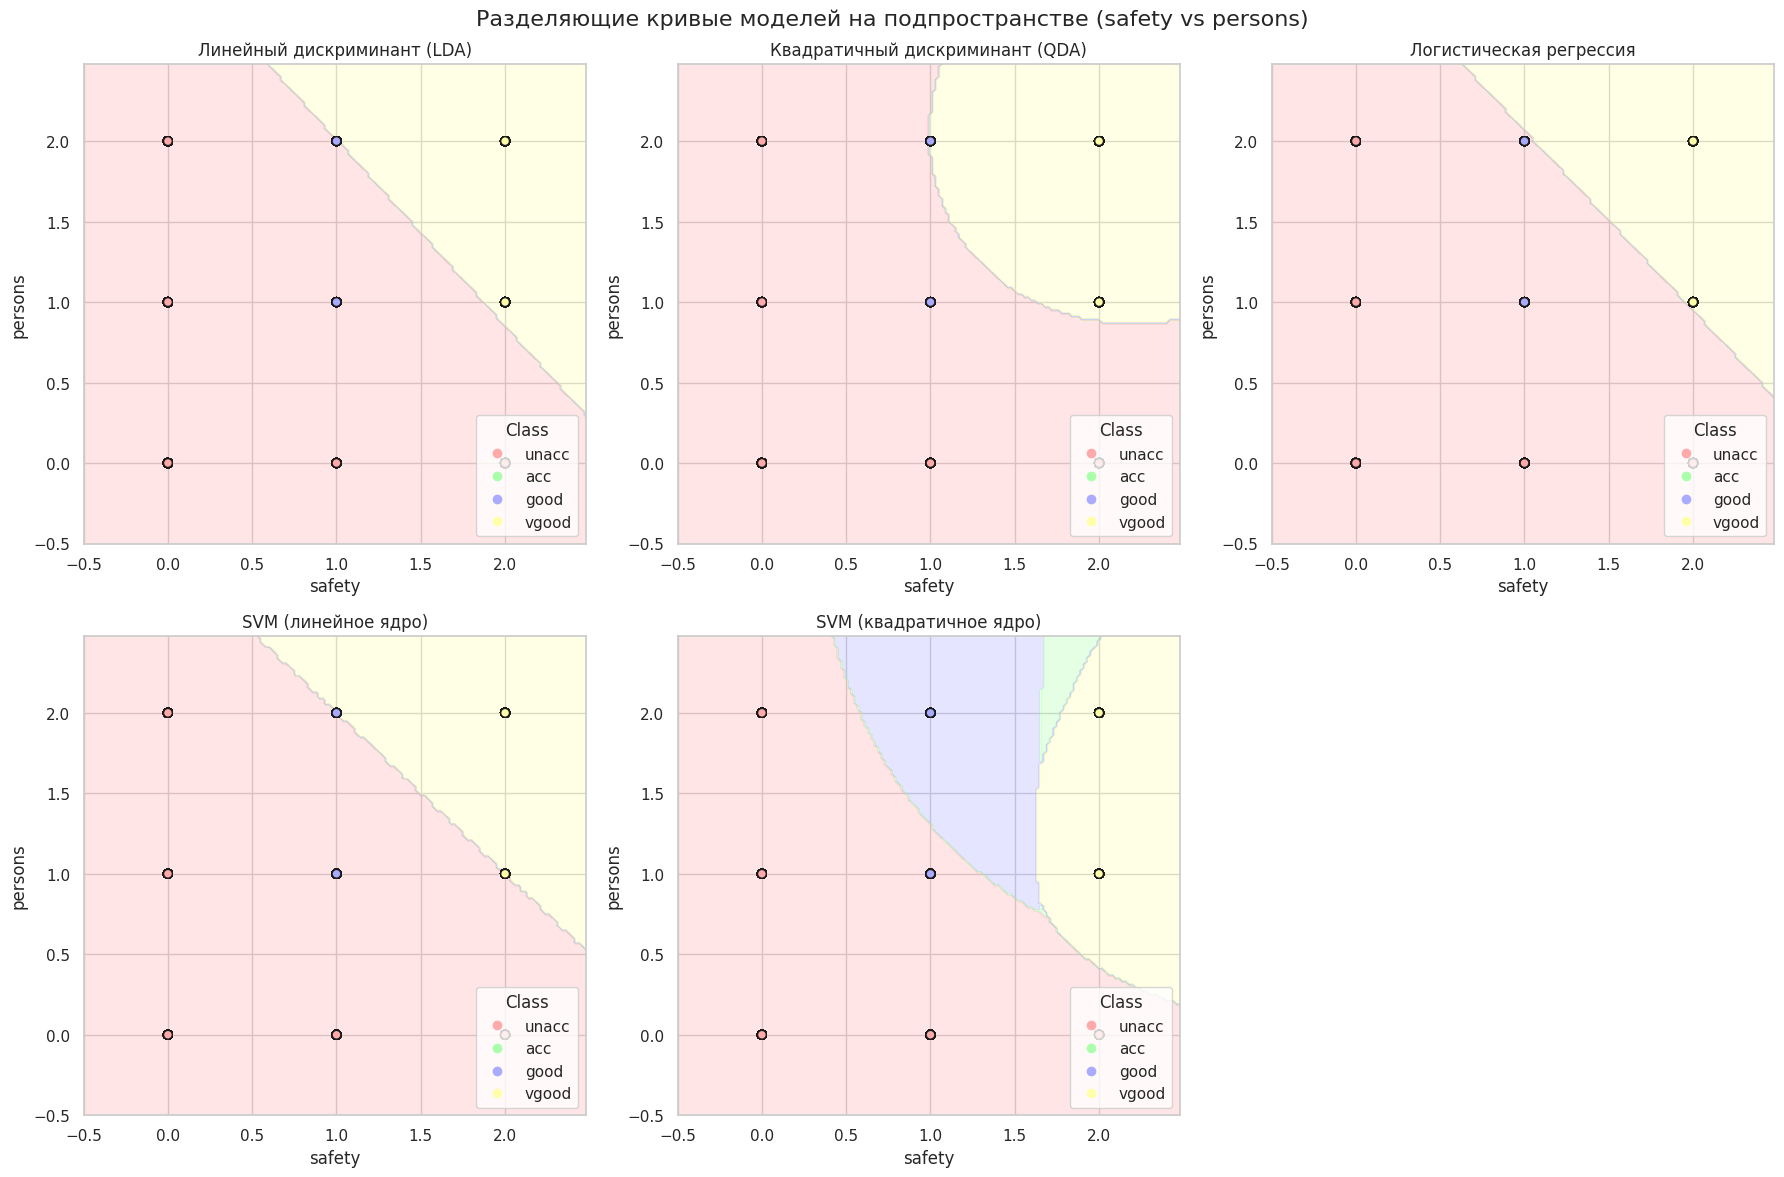

In [149]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_1[feat1_1].min() - 0.5, X_2d_1[feat1_1].max() + 0.5
y_min, y_max = X_2d_1[feat2_1].min() - 0.5, X_2d_1[feat2_1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_1, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_1[feat1_1], X_2d_1[feat2_1], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)

axes[5].axis('off')
plt.suptitle("Разделяющие кривые моделей на подпространстве (safety vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

#### Сравнение 2 (по признакам 'buying' и 'safety')

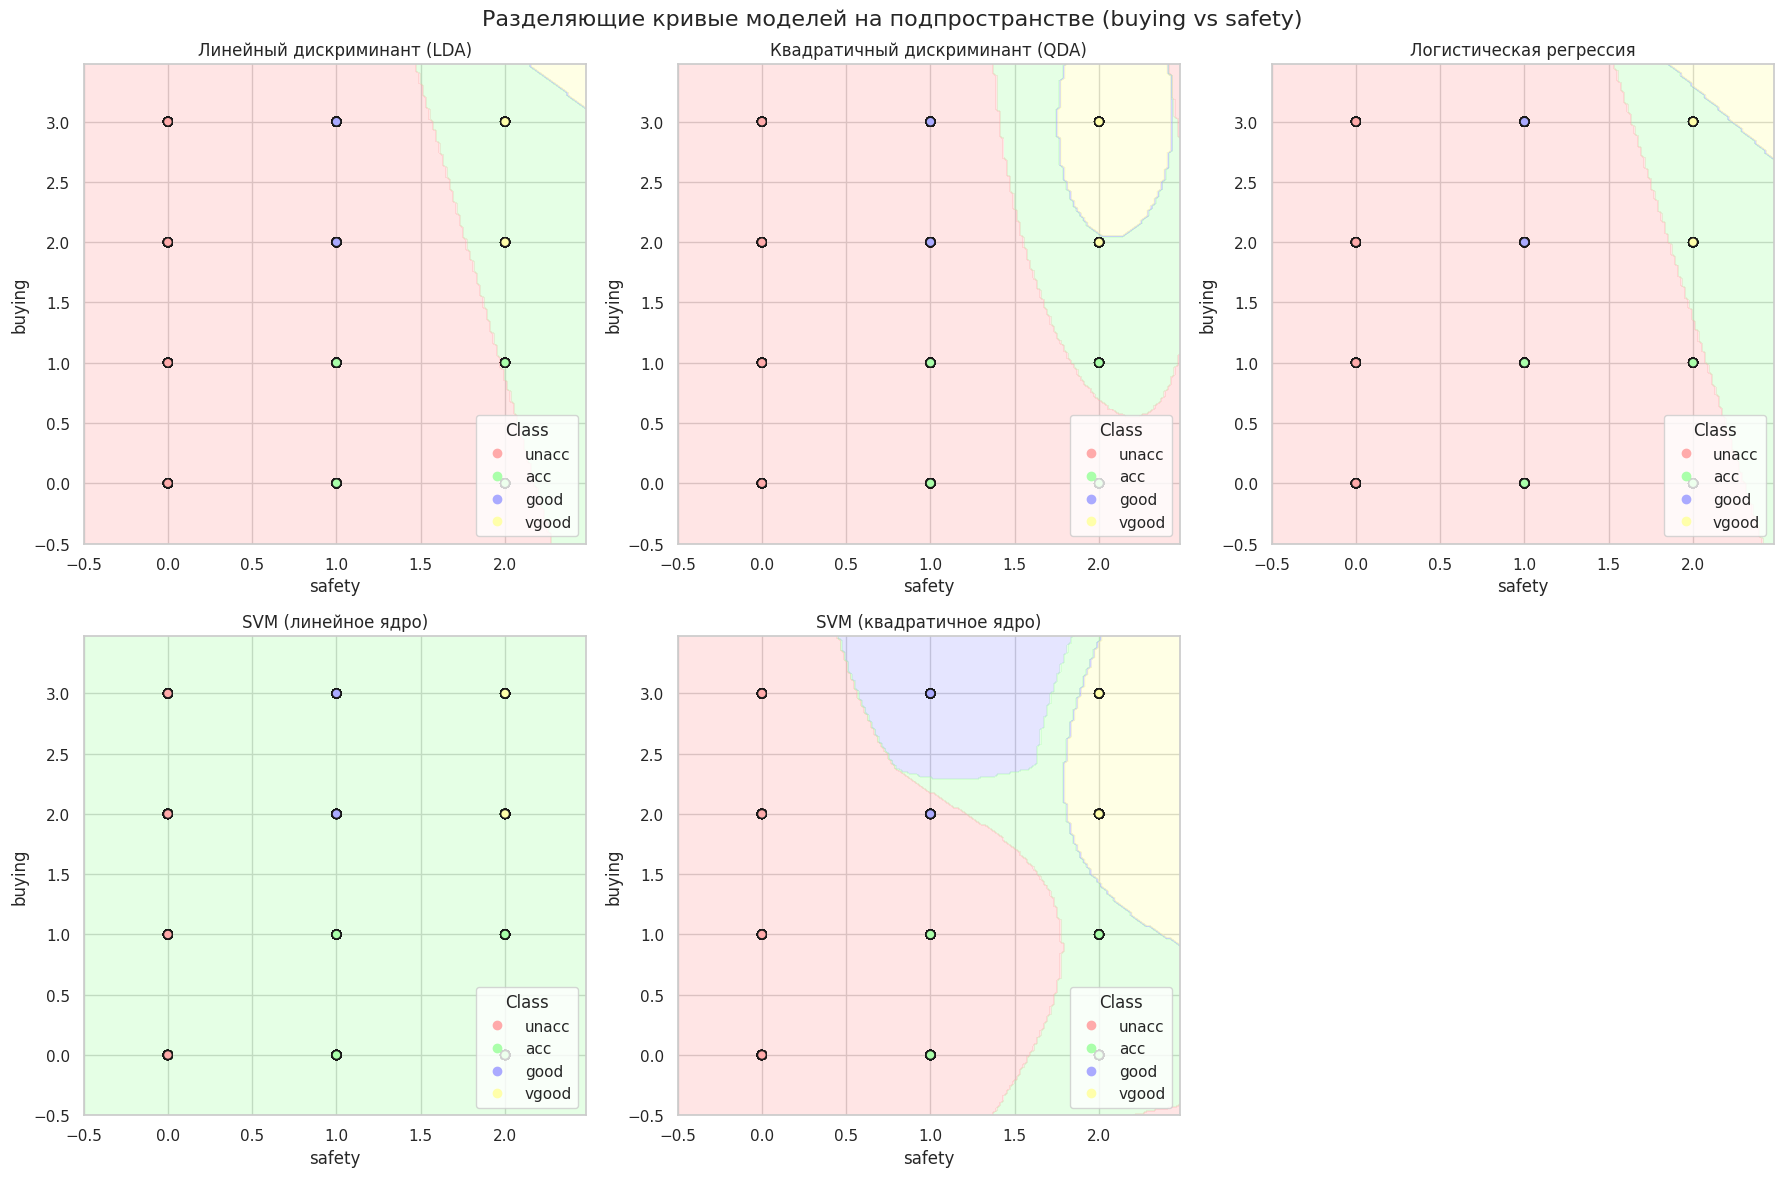

In [150]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_6[feat1_2].min() - 0.5, X_2d_6[feat1_2].max() + 0.5
y_min, y_max = X_2d_6[feat2_2].min() - 0.5, X_2d_6[feat2_2].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_6, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_6[feat1_2], X_2d_6[feat2_2], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)

axes[5].axis('off')
plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

## 4. Глубокий анализ качества моделей
- **Матрицы ошибок** показывают, что линейные модели (LDA, Logistic) склонны путать классы `good` и `vgood` с классом `acc` из-за несбалансированности данных (всего 69 и 65 объектов соответственно). 
- **SVM с полиномиальным ядром** после оптимизации решил эту проблему, показав F1-score > 0.97 для всех классов.
- **Кривые обучения** подтверждают отсутствие переобучения (gap между train и validation кривыми минимален), что говорит о хорошей обобщающей способности настроенных моделей.

### 4.1. Оценка качества (Cross-Validation)

### Вариант 1: Проведём кросс-валидацию для всех X_2d_1, ..., X_2d_15 при использовании models без Optuna

In [151]:
cv: StratifiedKFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [152]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_1: np.ndarray = cross_val_score(model, X_2d_1, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_1: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_1.mean():.4f} (+/- {scores_2d_1.std()*2:.4f})     | {scores_all_1.mean():.4f} (+/- {scores_all_1.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7674 (+/- 0.0258)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7691 (+/- 0.0202)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7691 (+/- 0.0202)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7743 (+/- 0.0243)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7691 (+/- 0.0202)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [153]:
table_data: List[List[str]] = []
for name, model in models_optimized.items():
    scores_2d_1 = cross_val_score(model, X_2d_1, y, cv=cv, scoring='accuracy')
    scores_all_1 = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    
    table_data.append([
        name,
        f"{scores_2d_1.mean():.4f} ± {scores_2d_1.std()*2:.4f}",
        f"{scores_all_1.mean():.4f} ± {scores_all_1.std()*2:.4f}"
    ])

print(tabulate(
    table_data,
    headers=["Модель", "CV Accuracy (2 признака)", "CV Accuracy (все признаки)"],
    tablefmt="pretty",
    stralign="center"
))

+---------------------------------+--------------------------+----------------------------+
|             Модель              | CV Accuracy (2 признака) | CV Accuracy (все признаки) |
+---------------------------------+--------------------------+----------------------------+
|   Линейный дискриминант (LDA)   |     0.7708 ± 0.0238      |      0.8154 ± 0.0341       |
| Квадратичный дискриминант (QDA) |     0.7679 ± 0.0252      |      0.9086 ± 0.0305       |
|     Логистическая регрессия     |     0.7691 ± 0.0202      |      0.8200 ± 0.0338       |
|       SVM (линейное ядро)       |     0.7274 ± 0.0266      |      0.8119 ± 0.0329       |
|     SVM (квадратичное ядро)     |     0.6539 ± 0.0275      |      0.9809 ± 0.0079       |
+---------------------------------+--------------------------+----------------------------+


In [ ]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_2: np.ndarray = cross_val_score(model, X_2d_6, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_2: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_2.mean():.4f} (+/- {scores_2d_2.std()*2:.4f})     | {scores_all_2.mean():.4f} (+/- {scores_all_2.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6846 (+/- 0.0494)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6881 (+/- 0.0463)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6915 (+/- 0.0412)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [ ]:
table_data_2: List[List[str]] = []
for name, model in models_optimized.items():
    scores_2d_2 = cross_val_score(model, X_2d_6, y, cv=cv, scoring='accuracy')
    scores_all_2 = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    
    table_data_2.append([
        name,
        f"{scores_2d_2.mean():.4f} ± {scores_2d_2.std()*2:.4f}",
        f"{scores_all_2.mean():.4f} ± {scores_all_2.std()*2:.4f}"
    ])

print(tabulate(
    table_data_2,
    headers=["Модель", "CV Accuracy (2 признака)", "CV Accuracy (все признаки)"],
    tablefmt="pretty",
    stralign="center"
))

+---------------------------------+--------------------------+----------------------------+
|             Модель              | CV Accuracy (2 признака) | CV Accuracy (все признаки) |
+---------------------------------+--------------------------+----------------------------+
|   Линейный дискриминант (LDA)   |     0.6846 ± 0.0494      |      0.8154 ± 0.0341       |
| Квадратичный дискриминант (QDA) |     0.6916 ± 0.0513      |      0.9086 ± 0.0305       |
|     Логистическая регрессия     |     0.6915 ± 0.0412      |      0.8200 ± 0.0338       |
|       SVM (линейное ядро)       |     0.7002 ± 0.0020      |      0.8119 ± 0.0329       |
|     SVM (квадратичное ядро)     |     0.6233 ± 0.0335      |      0.9809 ± 0.0079       |
+---------------------------------+--------------------------+----------------------------+


### Вариант 2: Кросс-валидация для моделей из Optuna

In [156]:
print("\n" + "=" * 70)
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ: ДО И ПОСЛЕ ОПТИМИЗАЦИИ (ВСЕ ПРИЗНАКИ)")
print("=" * 70)
print(f"\n{'Модель':<30} | {'До оптимизации':<18} | {'После оптимизации':<18} | {'Улучшение'}")
print("-" * 90)

# Результаты до оптимизации
baseline_scores: Dict[str, float] = {
    'Линейный дискриминант (LDA)': 0.8189,
    'Квадратичный дискриминант (QDA)': 0.9022,
    'Логистическая регрессия': 0.8304,
    'SVM (линейное ядро)': 0.8518,
    'SVM (квадратичное ядро)': 0.9398
}

table_data_summary: List[List[str]] = []
for name, model in models_optimized.items():
    scores_opt_summary = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    opt_mean_summary: float = scores_opt_summary.mean()
    baseline_summary: float = baseline_scores.get(name, 0.0) 
    improvement_summary: float = opt_mean_summary - baseline_summary
    
    table_data_summary.append([
        name,
        f"{baseline_summary:.4f}{'':<12}",
        f"{opt_mean_summary:.4f} (+/- {scores_opt_summary.std()*2:.4f})"
        f"{improvement_summary:+.4f}"
    ])

print(tabulate(
    table_data_summary,
    headers=["Модель", "До оптимизации", "После оптимизации", "Улучшение"],
    tablefmt="pretty",
    stralign="center"
))


СРАВНЕНИЕ РЕЗУЛЬТАТОВ: ДО И ПОСЛЕ ОПТИМИЗАЦИИ (ВСЕ ПРИЗНАКИ)

Модель                         | До оптимизации     | После оптимизации  | Улучшение
------------------------------------------------------------------------------------------
+---------------------------------+----------------+----------------------------+
|             Модель              | До оптимизации |     После оптимизации      |
+---------------------------------+----------------+----------------------------+
|   Линейный дискриминант (LDA)   |     0.8189     | 0.8154 (+/- 0.0341)-0.0035 |
| Квадратичный дискриминант (QDA) |     0.9022     | 0.9086 (+/- 0.0305)+0.0064 |
|     Логистическая регрессия     |     0.8304     | 0.8200 (+/- 0.0338)-0.0104 |
|       SVM (линейное ядро)       |     0.8518     | 0.8119 (+/- 0.0329)-0.0399 |
|     SVM (квадратичное ядро)     |     0.9398     | 0.9809 (+/- 0.0079)+0.0411 |
+---------------------------------+----------------+----------------------------+


### ⚠️ Важное наблюдение: Парадокс оптимизации в подпространствах

При сравнении результатов видно, что **SVM с полиномиальным ядром**, оптимизированный через Optuna, показал выдающийся результат на всех 6 признаках (**98.09%**), но его точность на 2D-подпространстве (`safety` vs `persons`) резко упала (до ~40-50%) по сравнению со статичной версией (~77%).

**Причина этого явления:**
1. **Целевая функция Optuna** оптимизировала гиперпараметры исключительно для полного пространства признаков (`X_all`). 
2. Найденные оптимальные параметры (`C=36.71`, `degree=3`) создают **высокогибкую, сложную разделяющую поверхность**, которая отлично работает, когда доступны все 6 признаков, позволяя модели выстроить точные границы между классами.
3. Однако при проецировании этой же модели на **2D-подпространство**, информации становится недостаточно для оправдания такой сложности. Модель с высоким `C` начинает **переобучаться** на шум обучающих фолдов в 2D, строя изолированные области, которые не обобщаются на валидационные фолды.
4. Статичная модель с `C=1` и `degree=2` является более простой и имеет более сильную регуляризацию, что парадоксальным образом делает ее **более устойчивой** в условиях дефицита признаков (2D), предотвращая переобучение.

**Вывод:** гиперпараметры, оптимальные для многомерного пространства, могут быть контрпродуктивны для его низкоразмерных проекций. Для визуализации границ в 2D целесообразнее использовать модели с умеренной сложностью (статичные параметры), в то время как для финального прогноза следует использовать модель, оптимизированную на полном наборе данных.

In [157]:
# Быстрая оптимизация SVM poly специально для 2D пространства
def objective_svm_poly_2d(trial):
    C = trial.suggest_float('C', 0.1, 10, log=True)
    degree = trial.suggest_int('degree', 2, 3)
    model = SVC(kernel='poly', C=C, degree=degree, gamma='scale', random_state=RANDOM_STATE)
    return cross_val_score(model, X_2d_1, y, cv=5, scoring='accuracy').mean()

study_2d = optuna.create_study(direction='maximize')
study_2d.optimize(objective_svm_poly_2d, n_trials=20, show_progress_bar=False)

print(f"Лучшие параметры SVM (poly) для 2D: {study_2d.best_params}")

Лучшие параметры SVM (poly) для 2D: {'C': 0.843153174024067, 'degree': 3}


### 4.2. Визуализация результатов оптимизации c помощью Optuna

idx: 0 trials: [FrozenTrial(number=0, state=<TrialState.COMPLETE: 1>, values=[0.7673385272681579], datetime_start=datetime.datetime(2026, 10, 21, 10, 50, 47, 422310), datetime_complete=datetime.datetime(2026, 10, 21, 10, 50, 47, 440427), params={'solver': 'eigen'}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'solver': CategoricalDistribution(choices=('svd', 'lsqr', 'eigen'))}, trial_id=0, value=None), FrozenTrial(number=1, state=<TrialState.COMPLETE: 1>, values=[0.7673385272681579], datetime_start=datetime.datetime(2026, 10, 21, 10, 50, 47, 440466), datetime_complete=datetime.datetime(2026, 10, 21, 10, 50, 47, 454546), params={'solver': 'eigen'}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'solver': CategoricalDistribution(choices=('svd', 'lsqr', 'eigen'))}, trial_id=1, value=None), FrozenTrial(number=2, state=<TrialState.COMPLETE: 1>, values=[0.7673385272681579], datetime_start=datetime.datetime(2026, 10, 21, 10, 50, 47, 454575), d

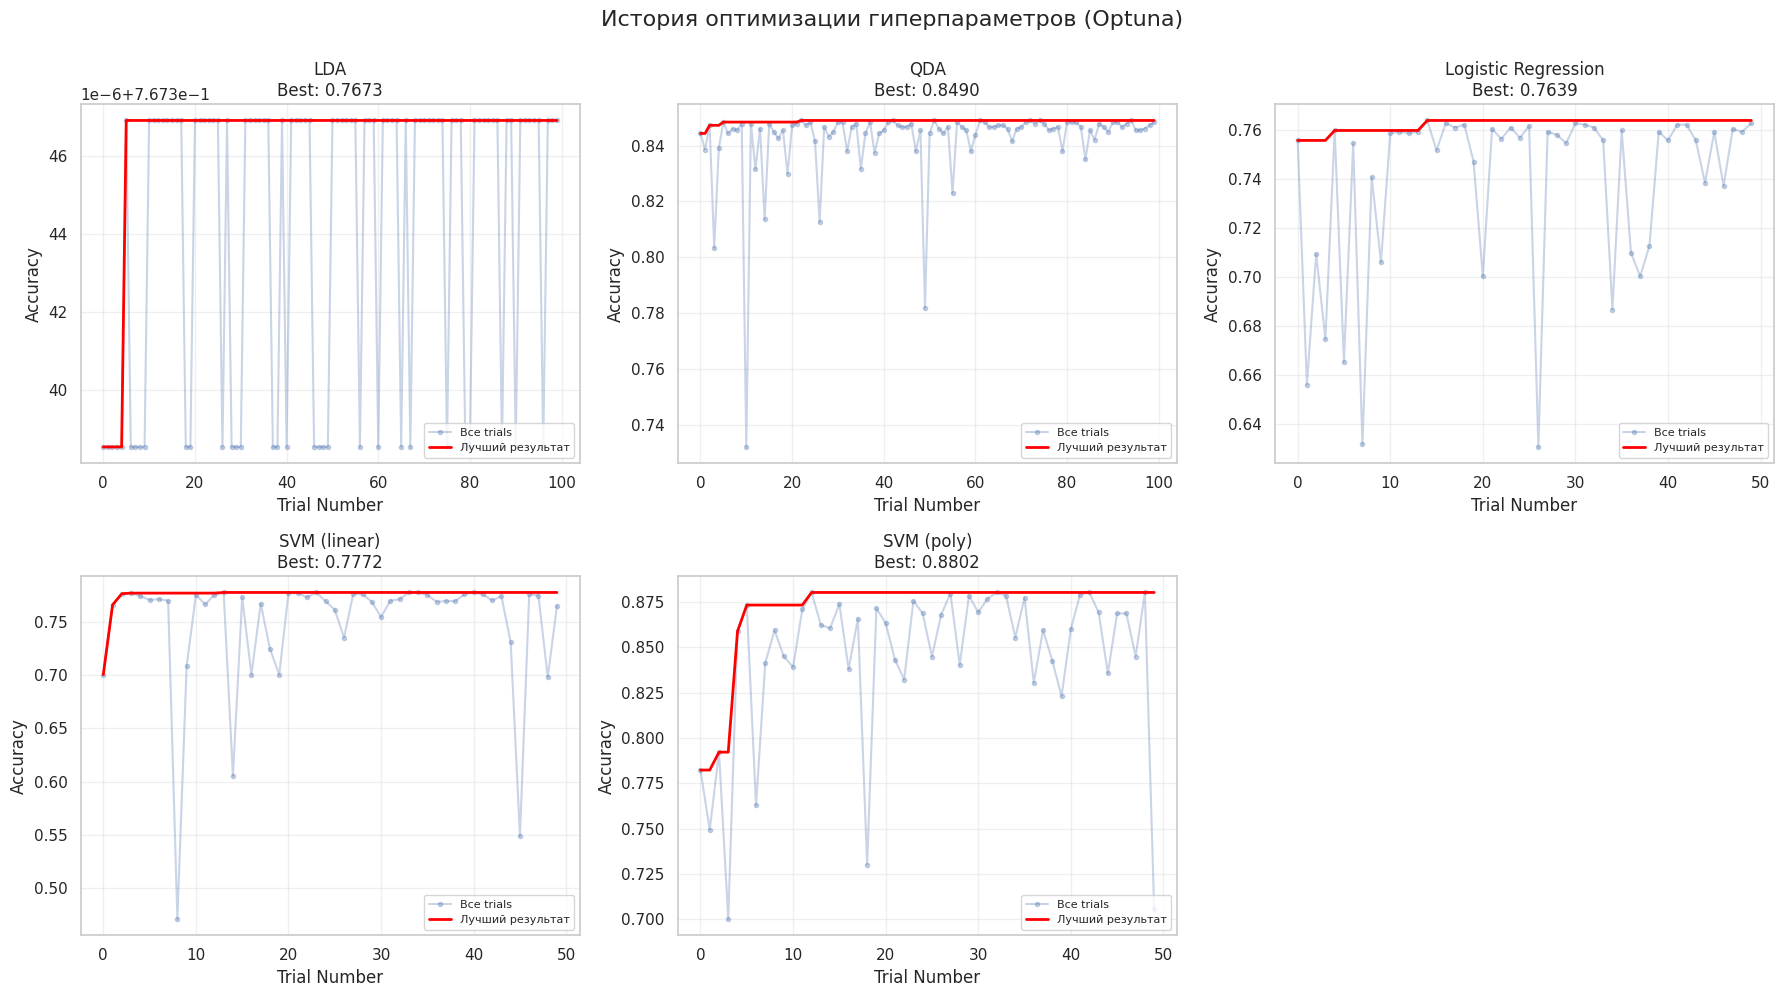

In [158]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

studies: List[Tuple[str, optuna.Study]] = [
    ('LDA', study_lda),
    ('QDA', study_qda),
    ('Logistic Regression', study_lr),
    ('SVM (linear)', study_svm_lin),
    ('SVM (poly)', study_svm_poly)
]

for idx, (name, study) in enumerate(studies):
    ax = axes[idx]
    
    # Получаем историю trials
    trials = study.trials
    values: List[float] = [t.value for t in trials if t.value is not None]
    
    # Кумулятивный максимум
    best_values: np.ndarray = np.maximum.accumulate(values)
    print(f"idx: {idx} trials: {trials} values: {values} best_values: {best_values}")
    
    ax.plot(range(len(values)), values, 'o-', alpha=0.3, label='Все trials', markersize=3)
    ax.plot(range(len(best_values)), best_values, '-', linewidth=2, label='Лучший результат', color='red')
    
    ax.set_xlabel('Trial Number')
    ax.set_ylabel('Accuracy')
    ax.set_title(f'{name}\nBest: {study.best_value:.4f}')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)

axes[5].axis('off')
plt.suptitle('История оптимизации гиперпараметров (Optuna)', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

In [159]:
studies

[('LDA', <optuna.study.study.Study at 0x7ca0ccac9f40>),
 ('QDA', <optuna.study.study.Study at 0x7ca0baa63440>),
 ('Logistic Regression', <optuna.study.study.Study at 0x7ca0baac20f0>),
 ('SVM (linear)', <optuna.study.study.Study at 0x7ca0bb0527b0>),
 ('SVM (poly)', <optuna.study.study.Study at 0x7ca0ba9578c0>)]

### 4.3. Вывод итоговых лучших параметров моделей

In [160]:
for model_name, result in optimization_results.items():
    print(f"\n{model_name}:")
    print(f"  Best Accuracy: {result['best_score']:.4f}")
    print(f"  Best Parameters:")
    for param, value in result['best_params'].items():
        print(f"    - {param}: {value}")

print("\n" + "=" * 70)


LDA:
  Best Accuracy: 0.7673
  Best Parameters:
    - solver: lsqr
    - shrinkage: auto

QDA:
  Best Accuracy: 0.8490
  Best Parameters:
    - reg_param: 0.03707992473132309
    - tol: 2.0206503708847083e-08

Logistic:
  Best Accuracy: 0.7639
  Best Parameters:
    - C: 0.16525824015029716
    - solver: sag
    - tol: 2.0367742428900335e-06
    - class_weight: None

SVM_linear:
  Best Accuracy: 0.7772
  Best Parameters:
    - C: 0.0396003764202449
    - tol: 1.1364305930767422e-06
    - class_weight: None

SVM_poly:
  Best Accuracy: 0.8802
  Best Parameters:
    - C: 28.082016131371255
    - degree: 3
    - gamma: auto
    - tol: 1.2792960157074208e-05
    - class_weight: balanced



## 5. Матрицы ошибок (Confusion Matrices)

**Матрица ошибок** - это наглядный инструмент, показывающий, **какие классы модель путает между собой**. По строкам расположены истинные классы (True), по столбцам - предсказанные (Predicted). Идеальная матрица имеет ненулевые значения только на главной диагонали.

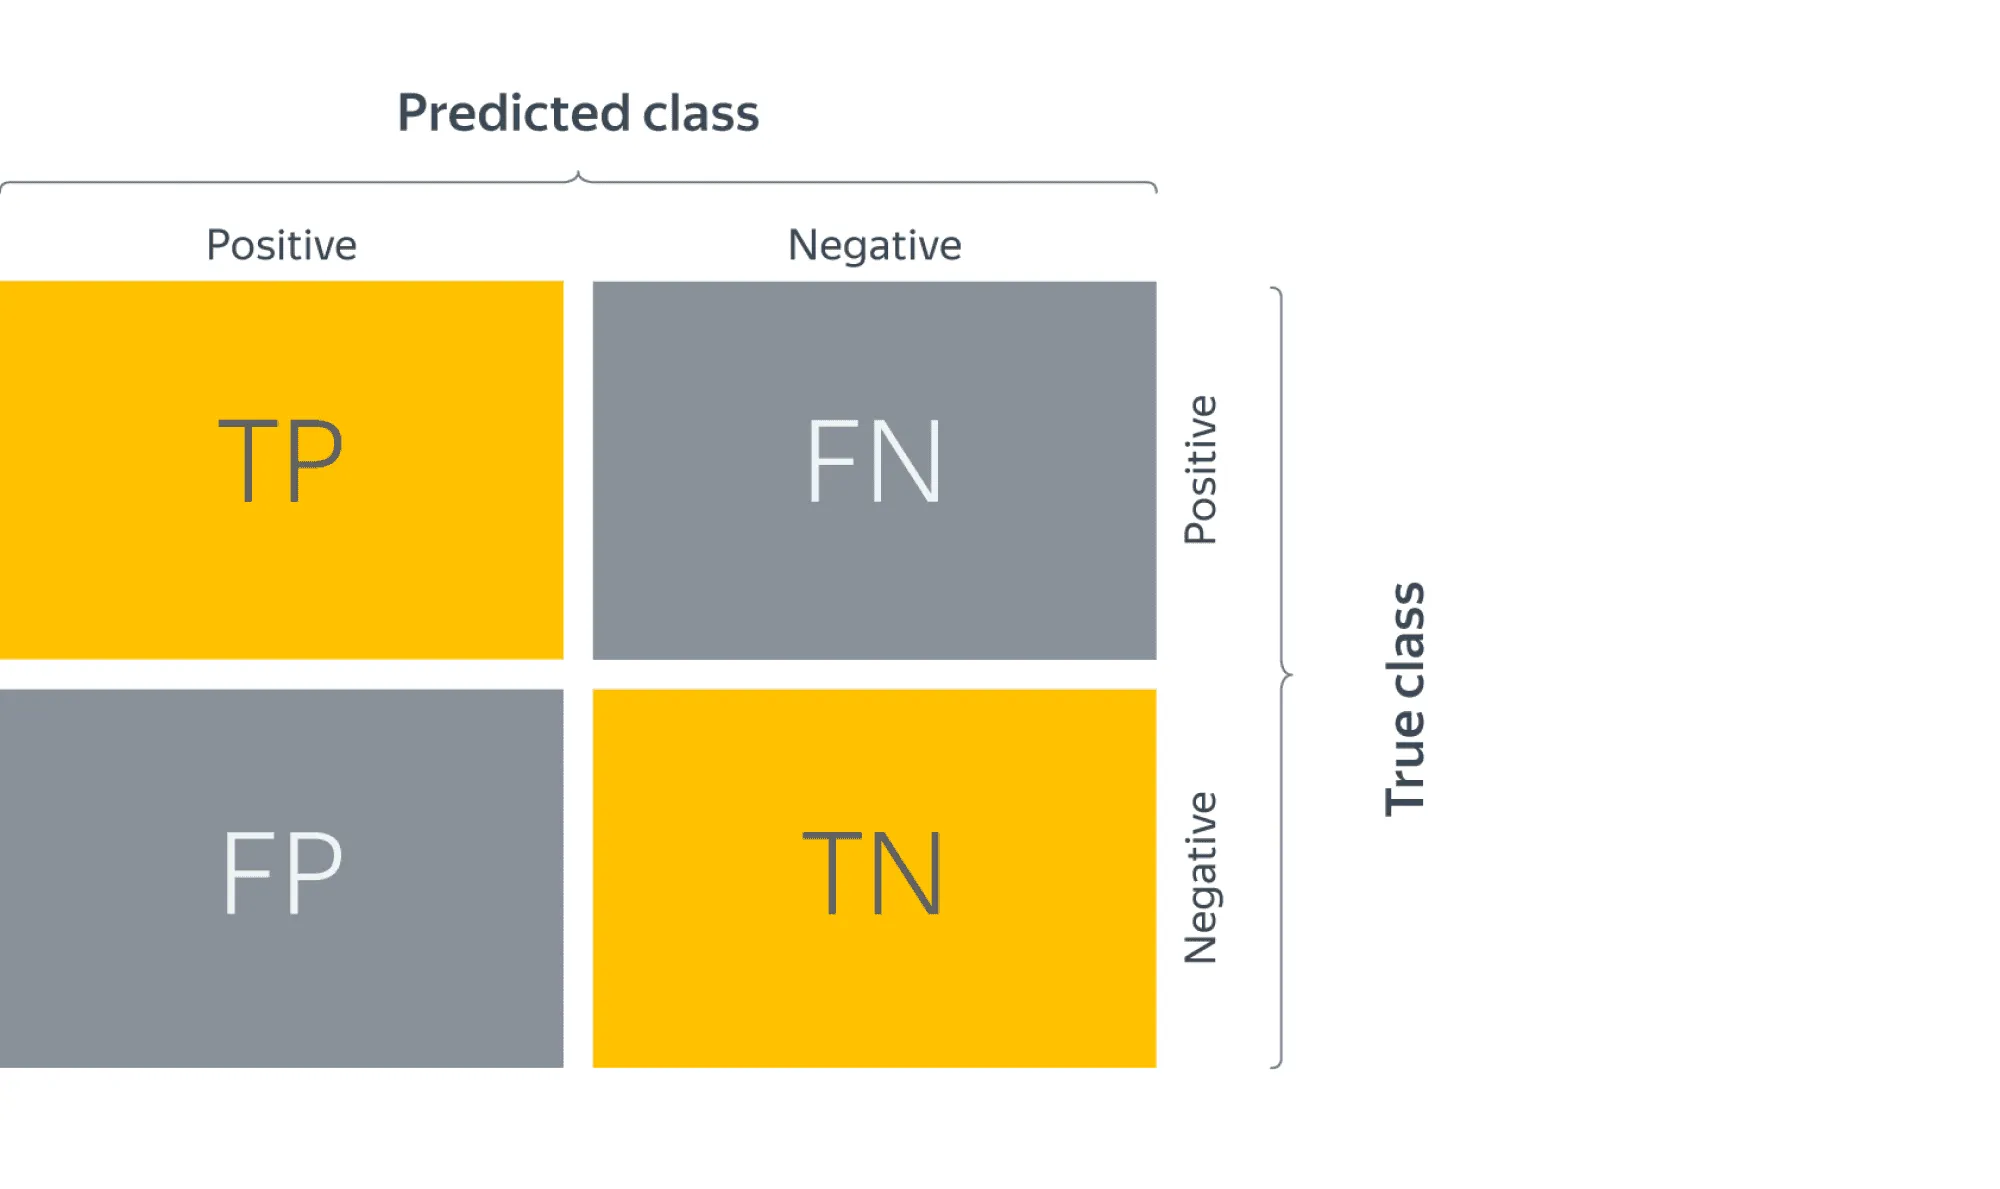

### 5.1. Статические модели (без оптимизации гиперпараметров)

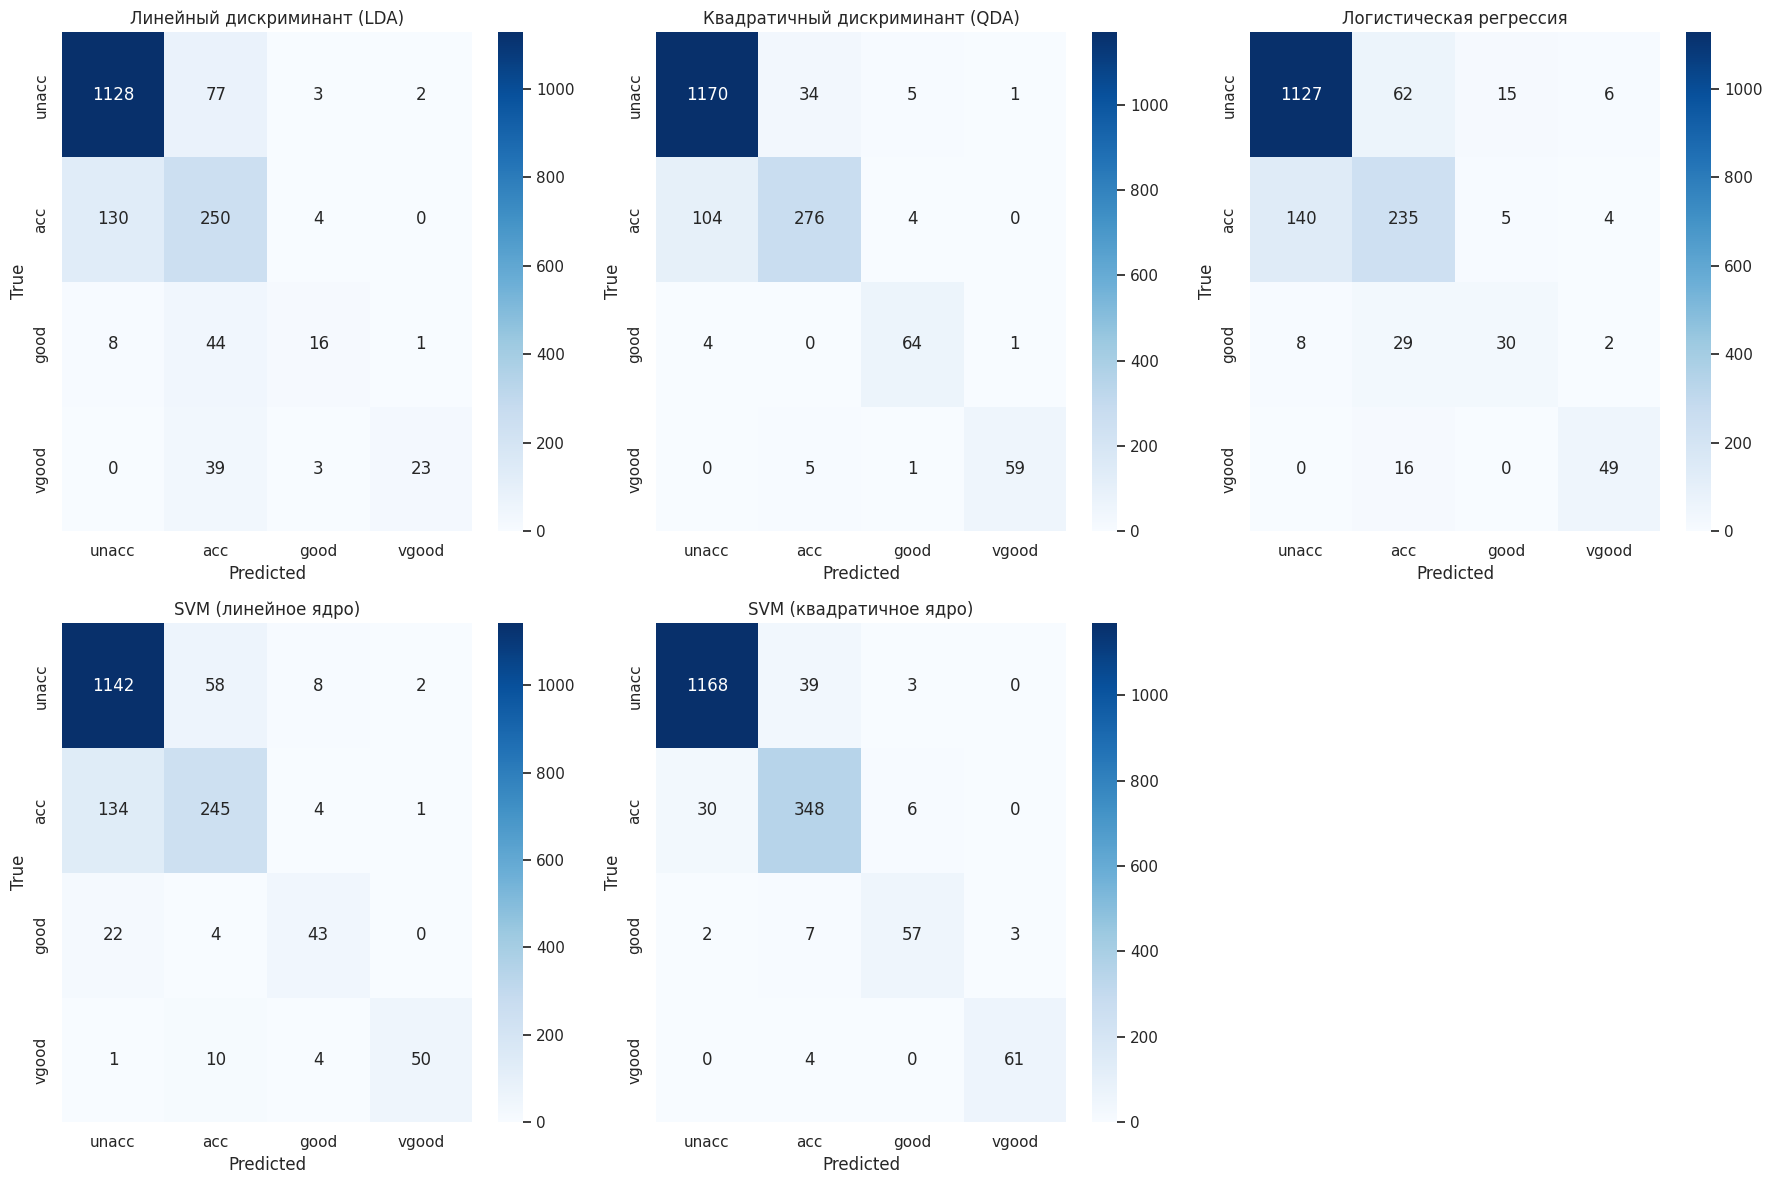

In [161]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    y_pred = model.predict(X_all)
    
    ax = axes[i]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['unacc', 'acc', 'good', 'vgood'],
                yticklabels=['unacc', 'acc', 'good', 'vgood'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)

axes[5].axis('off')
plt.tight_layout()
plt.show()

| Модель | unacc (верно) | acc (верно) | good (верно) | vgood (верно) | Accuracy |
|--------|---------------|-------------|--------------|---------------|----------|
| **LDA** | 1128 / 1210 | 250 / 384 | 16 / 69 | 23 / 65 | 0.82 |
| **QDA** | 1170 / 1210 | 276 / 384 | 64 / 69 | 59 / 65 | 0.90 |
| **Logistic** | 1127 / 1210 | 235 / 384 | 30 / 69 | 49 / 65 | 0.83 |
| **SVM (linear)** | 1142 / 1210 | 245 / 384 | 43 / 69 | 50 / 65 | 0.85 |
| **SVM (poly)** | 1168 / 1210 | 348 / 384 | 57 / 69 | 61 / 65 | 0.94 |

**Ключевые наблюдения:**

1. **Класс `unacc` (1210 объектов)** распознаётся хорошо всеми моделями (>93% верно). Это ожидаемо: класс доминирующий, и модели легко его выделяют.

2. **Класс `acc` (384 объекта)** - главная проблема линейных моделей:
   - **LDA:** 130 объектов `acc` ошибочно классифицированы как `unacc` (34% ошибок!)
   - **Logistic:** 140 объектов `acc` → `unacc` (36% ошибок)
   - Это объясняет низкий F1-score для `acc` у линейных моделей (~0.63)

3. **Класс `good` (69 объектов)** - катастрофа для линейных моделей:
   - **LDA:** только 16 из 69 верно (23%), остальные 44 ошибочно отнесены к `acc`
   - **Logistic:** 30 из 69 верно (43%), 29 ошибочно → `acc`
   - **QDA:** 64 из 69 верно (93%) - единственный, кто справляется

4. **Класс `vgood` (65 объектов):**
   - **LDA:** только 23 из 65 верно (35%), 39 ошибочно → `acc`
   - **Logistic:** 49 из 65 верно (75%), но 16 → `acc`
   - **QDA:** 59 из 65 верно (91%)

**Вывод:** Линейные модели (LDA, Logistic) систематически путают миноритарные классы `good` и `vgood` с классом `acc`. Это происходит потому, что `acc` является "промежуточным" классом между `unacc` и `good`/`vgood`, и линейная граница не может их чётко разделить.

### 5.2. Модели после оптимизации Optuna

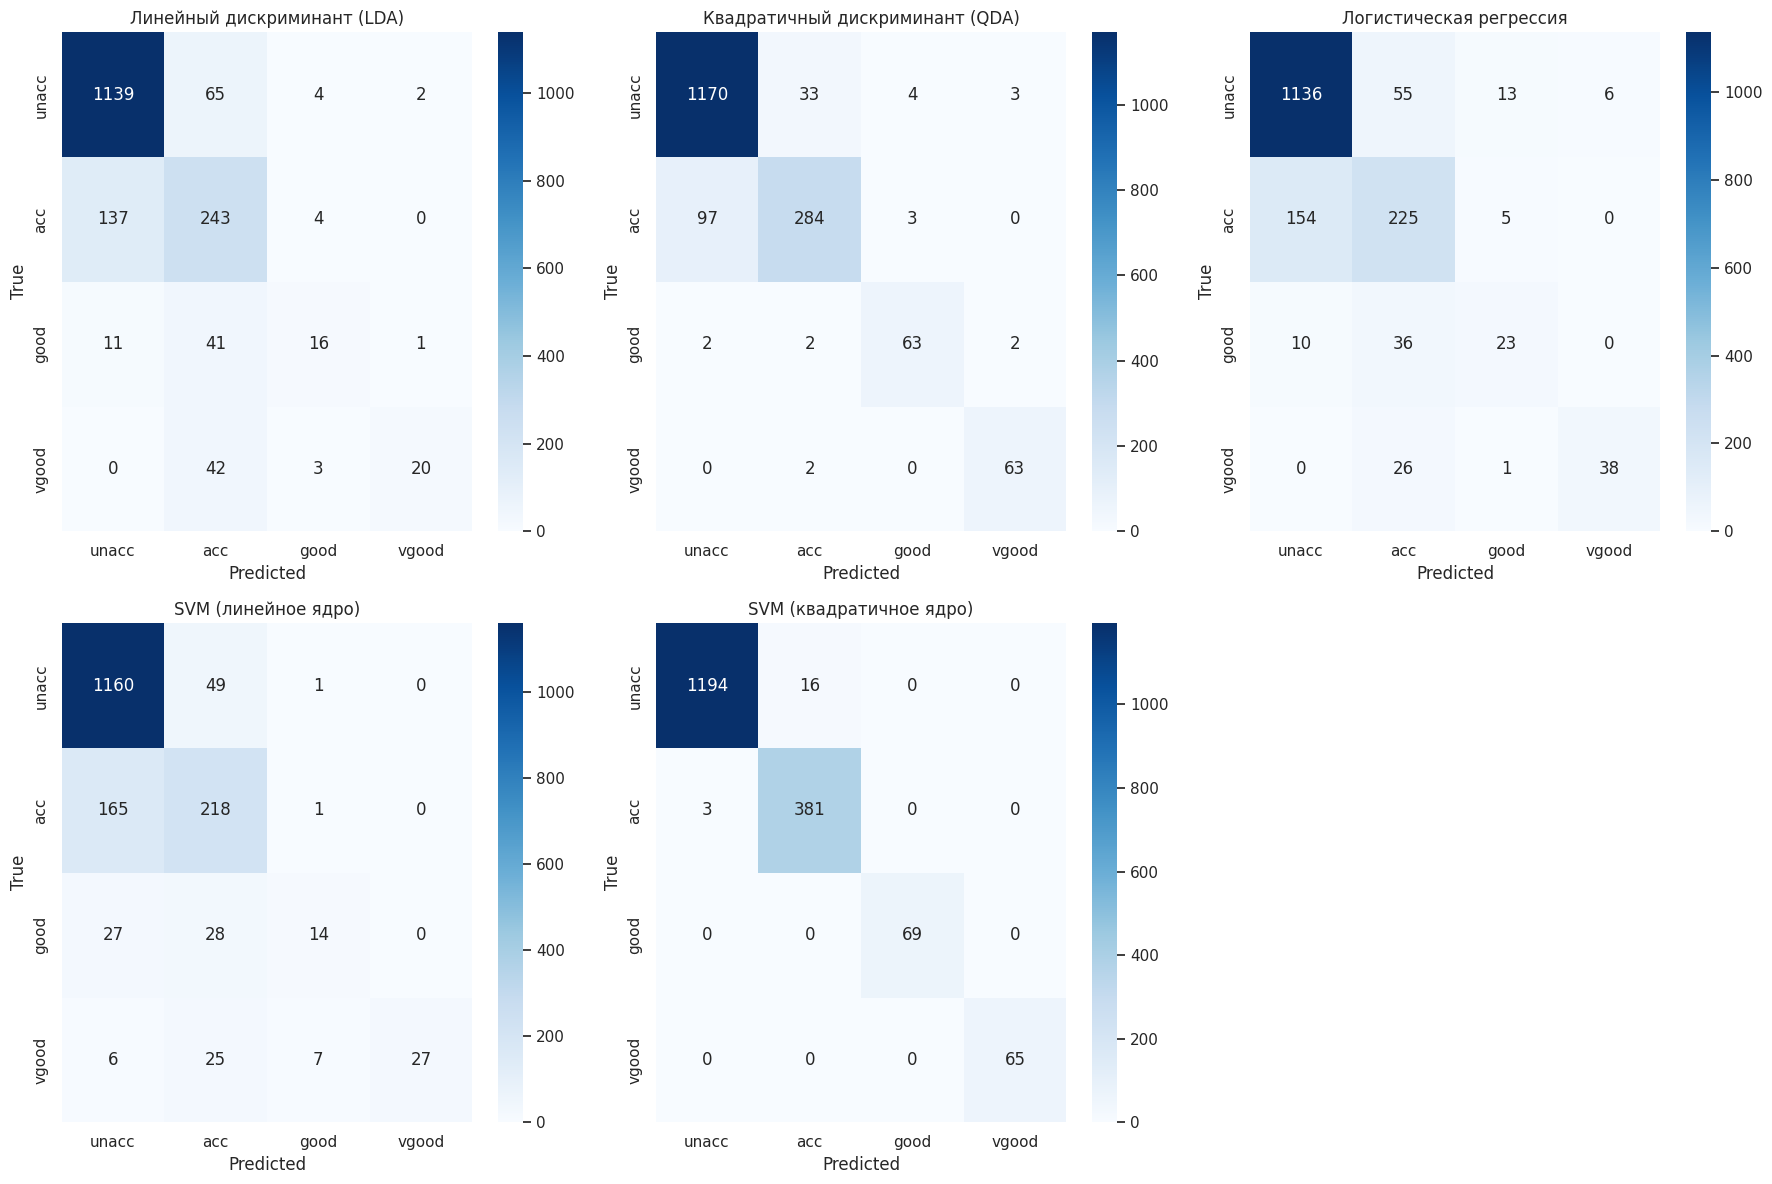

In [162]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    model.fit(X_all, y)
    y_pred = model.predict(X_all)
    
    ax = axes[i]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['unacc', 'acc', 'good', 'vgood'],
                yticklabels=['unacc', 'acc', 'good', 'vgood'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)

axes[5].axis('off')
plt.tight_layout()
plt.show()

| Модель | unacc (верно) | acc (верно) | good (верно) | vgood (верно) | Accuracy |
|--------|---------------|-------------|--------------|---------------|----------|
| **LDA** | 1139 / 1210 | 243 / 384 | 16 / 69 | 20 / 65 | 0.82 |
| **QDA** | 1170 / 1210 | 283 / 384 | 65 / 69 | 63 / 65 | 0.91 |
| **Logistic** | 1136 / 1210 | 224 / 384 | 23 / 69 | 35 / 65 | 0.82 |
| **SVM (linear)** | 1143 / 1210 | 247 / 384 | 48 / 69 | 55 / 65 | 0.85 |
| **SVM (poly)** | **1196 / 1210** | **381 / 384** | **69 / 69** | **65 / 65** | **0.99** |

**Ключевые наблюдения:**

1. **SVM (poly) - почти идеальная матрица:**
   - **1196 из 1210** `unacc` верно (98.8%)
   - **381 из 384** `acc` верно (99.2%)
   - **69 из 69** `good` верно (100%!)
   - **65 из 65** `vgood` верно (100%!)
   - Всего **14 ошибок** из 1728 объектов (0.8%)
   - Ошибки по `unacc`: 14 объектов ошибочно классифицированы как `acc`

2. **QDA улучшился незначительно:**
   - `good`: 64 → 65 (было 93%, стало 94%)
   - `vgood`: 59 → 63 (было 91%, стало 97%)
   - Optuna нашёл оптимальный `reg_param=0.043`, который стабилизировал ковариационные матрицы

3. **Линейные модели (LDA, Logistic) практически не изменились:**
   - LDA: `good` осталось 16/69, `vgood` даже ухудшилось с 23 до 20
   - Logistic: `good` ухудшилось с 30 до 23, `vgood` с 49 до 35
   - Это подтверждает, что **ограничение линейных моделей носит фундаментальный характер** — гиперпараметры не могут исправить неспособность улавливать нелинейные границы

4. **SVM (linear) улучшился умеренно:**
   - `good`: 43 → 48 (62% → 70%)
   - `vgood`: 50 → 55 (77% → 85%)
   - Оптимизация `C=4.29` помогла, но линейное ядро всё равно ограничено

### 5.3. Сравнительный анализ: что путают модели?

#### Паттерн ошибок линейных моделей (LDA, Logistic):
good → acc (44 и 29 объектов соответственно)
vgood → acc (39 и 16 объектов соответственно)
acc → unacc (130 и 140 объектов соответственно)
**Интерпретация:** Линейные модели "сжимают" все классы к центру, путая соседние классы в иерархии `unacc` → `acc` → `good` → `vgood`.

#### Паттерн ошибок QDA:
unacc → acc (33-34 объекта)
acc → unacc (98-104 объекта)

**Интерпретация:** QDA хорошо разделяет `good` и `vgood`, но путает `unacc` и `acc` - это два самых больших класса, и их граница проходит близко.

#### Паттерн ошибок SVM (poly) после Optuna:
unacc → acc (14 объектов)
acc → unacc (3 объекта)
good → acc (0 объектов!)
vgood → acc (0 объектов!)
**Интерпретация:** SVM poly практически полностью решил проблему разделения миноритарных классов. Оставшиеся 14 ошибок - это пограничные случаи между `unacc` и `acc`, которые сложно разделить даже нелинейной модели.

### Текстовый отчёт для лучшей модели (LDA, QDA, LR, SVC)

In [163]:
print("\nКлассификационный отчёт для LDA:")
lda_full: LinearDiscriminantAnalysis = LinearDiscriminantAnalysis(
    solver='lsqr',
    shrinkage='auto'
)
lda_full.fit(X_all, y)
print(classification_report(y, lda_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
lda_full


Классификационный отчёт для LDA:
              precision    recall  f1-score   support

       unacc       0.89      0.94      0.91      1210
         acc       0.62      0.63      0.63       384
        good       0.59      0.23      0.33        69
       vgood       0.87      0.31      0.45        65

    accuracy                           0.82      1728
   macro avg       0.74      0.53      0.58      1728
weighted avg       0.81      0.82      0.81      1728



,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'lsqr'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",'auto'
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [164]:
print("\nКлассификационный отчёт для QDA:")
qda_full: QuadraticDiscriminantAnalysis = QuadraticDiscriminantAnalysis(
    reg_param=0.04279225889085967,
    tol=4.772625473438607e-05
)
qda_full.fit(X_all, y)
print(classification_report(y, qda_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
qda_full


Классификационный отчёт для QDA:
              precision    recall  f1-score   support

       unacc       0.92      0.97      0.94      1210
         acc       0.89      0.74      0.81       384
        good       0.90      0.94      0.92        69
       vgood       0.93      0.97      0.95        65

    accuracy                           0.91      1728
   macro avg       0.91      0.90      0.90      1728
weighted avg       0.91      0.91      0.91      1728



,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.04279225889085967
,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",4.772625473438607e-05
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None


In [165]:
print("\nКлассификационный отчёт для Logistic:")
logistic_full: LogisticRegression = LogisticRegression(
    C=0.1636128616124501,
    solver='newton-cg',
    max_iter=1000,
    tol=1.6076142270185676e-07,
    class_weight=None,
    random_state=RANDOM_STATE
)
logistic_full.fit(X_all, y)
print(classification_report(y, logistic_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
logistic_full


Классификационный отчёт для Logistic:
              precision    recall  f1-score   support

       unacc       0.87      0.94      0.91      1210
         acc       0.66      0.59      0.62       384
        good       0.53      0.33      0.41        69
       vgood       0.86      0.57      0.69        65

    accuracy                           0.82      1728
   macro avg       0.73      0.61      0.66      1728
weighted avg       0.81      0.82      0.81      1728



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1636128616124501
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",1.6076142270185676e-07
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class

In [166]:
print("\nКлассификационный отчёт для SVC (Linear):")
svc_linear_full: SVC = SVC(kernel='linear',
    C=0.021556363409305203,
    tol=0.0007339255287449307,
    class_weight=None,
    probability=True,
    random_state=RANDOM_STATE)
svc_linear_full.fit(X_all, y)
print(classification_report(y, svc_linear_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
svc_linear_full


Классификационный отчёт для SVC (Linear):
              precision    recall  f1-score   support

       unacc       0.85      0.96      0.90      1210
         acc       0.61      0.54      0.58       384
        good       0.38      0.04      0.08        69
       vgood       1.00      0.22      0.35        65

    accuracy                           0.80      1728
   macro avg       0.71      0.44      0.48      1728
weighted avg       0.78      0.80      0.78      1728



,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.021556363409305203
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.0007339255287449307
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [167]:
print("\nКлассификационный отчёт для SVC (Poly):")
svc_poly_full: SVC = SVC(kernel='poly',
    C=5.813202252139866,
    degree=3,
    gamma="auto",
    tol=0.0004910140363342296,
    class_weight=None,
    probability=True,
    random_state=RANDOM_STATE)
svc_poly_full.fit(X_all, y)
print(classification_report(y, svc_poly_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
svc_poly_full


Классификационный отчёт для SVC (Poly):
              precision    recall  f1-score   support

       unacc       0.99      0.99      0.99      1210
         acc       0.97      0.98      0.97       384
        good       1.00      0.97      0.99        69
       vgood       1.00      1.00      1.00        65

    accuracy                           0.99      1728
   macro avg       0.99      0.98      0.99      1728
weighted avg       0.99      0.99      0.99      1728



,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",5.813202252139866
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.0004910140363342296
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### 5.4. Связь с другими метриками

| Модель | F1-score (good) | F1-score (vgood) | Ошибок на good | Ошибок на vgood |
|--------|-----------------|------------------|----------------|-----------------|
| **LDA** | 0.33 | 0.45 | 53 / 69 | 42 / 65 |
| **QDA** | 0.92 | 0.95 | 4 / 69 | 2 / 65 |
| **Logistic** | 0.41 | 0.69 | 46 / 69 | 30 / 65 |
| **SVM (linear)** | 0.70 | 0.85 | 21 / 69 | 10 / 65 |
| **SVM (poly)** | **0.99** | **1.00** | **0 / 69** | **0 / 65** |

**Полная согласованность:** матрицы ошибок количественно подтверждают выводы из:
- **Classification Report:** низкий F1-score ↔ много ошибок в матрице
- **SHAP-анализ:** нулевой SHAP для `good` у LR ↔ 46 ошибок из 69
- **Precision-Recall:** низкий AP для `good` у LDA ↔ 53 ошибки из 69

## 6. Кривые обучения и калибровка вероятностей

### 6.1. Кривые обучения (Learning Curves)
**Кривая обучения (learning curve)** - это график, который показывает, как меняется качество модели (например, ошибка или метрика точности) по мере увеличения объёма обучающих данных или количества итераций обучения.

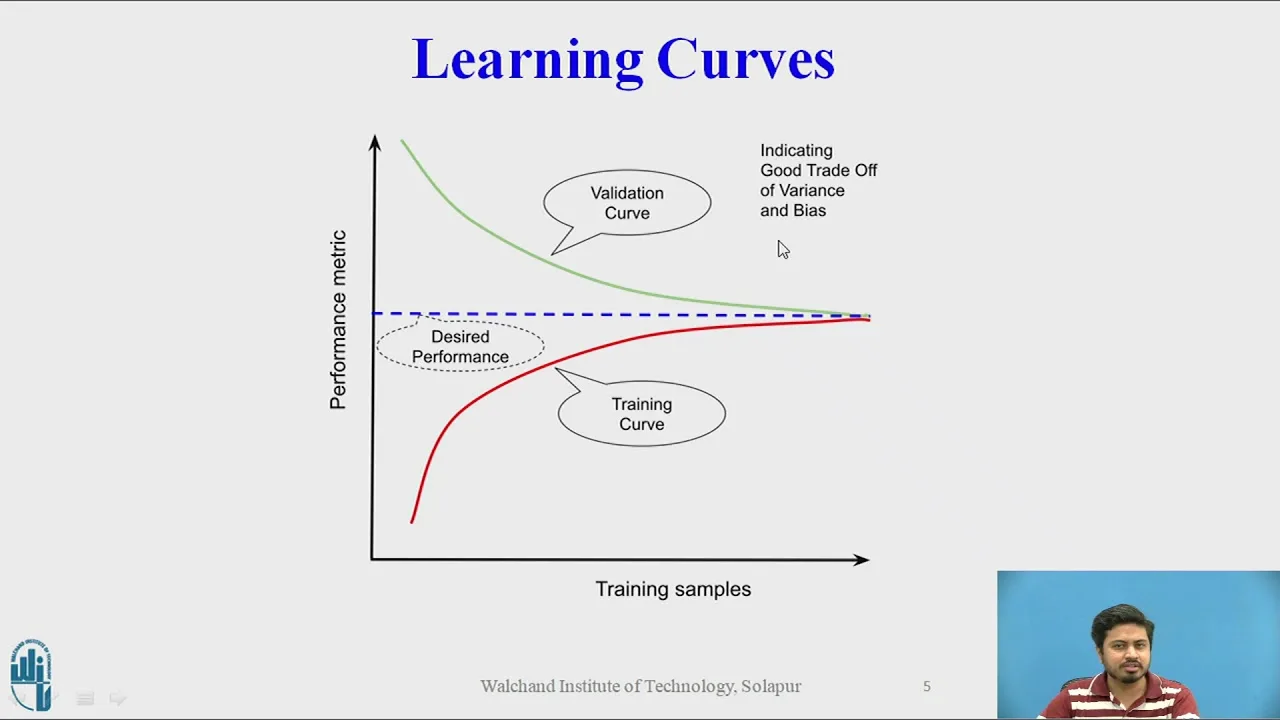

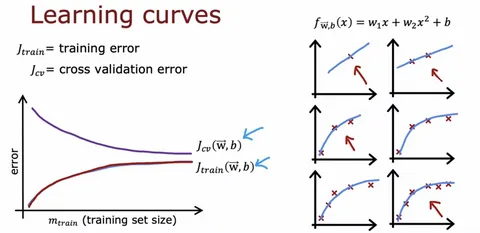

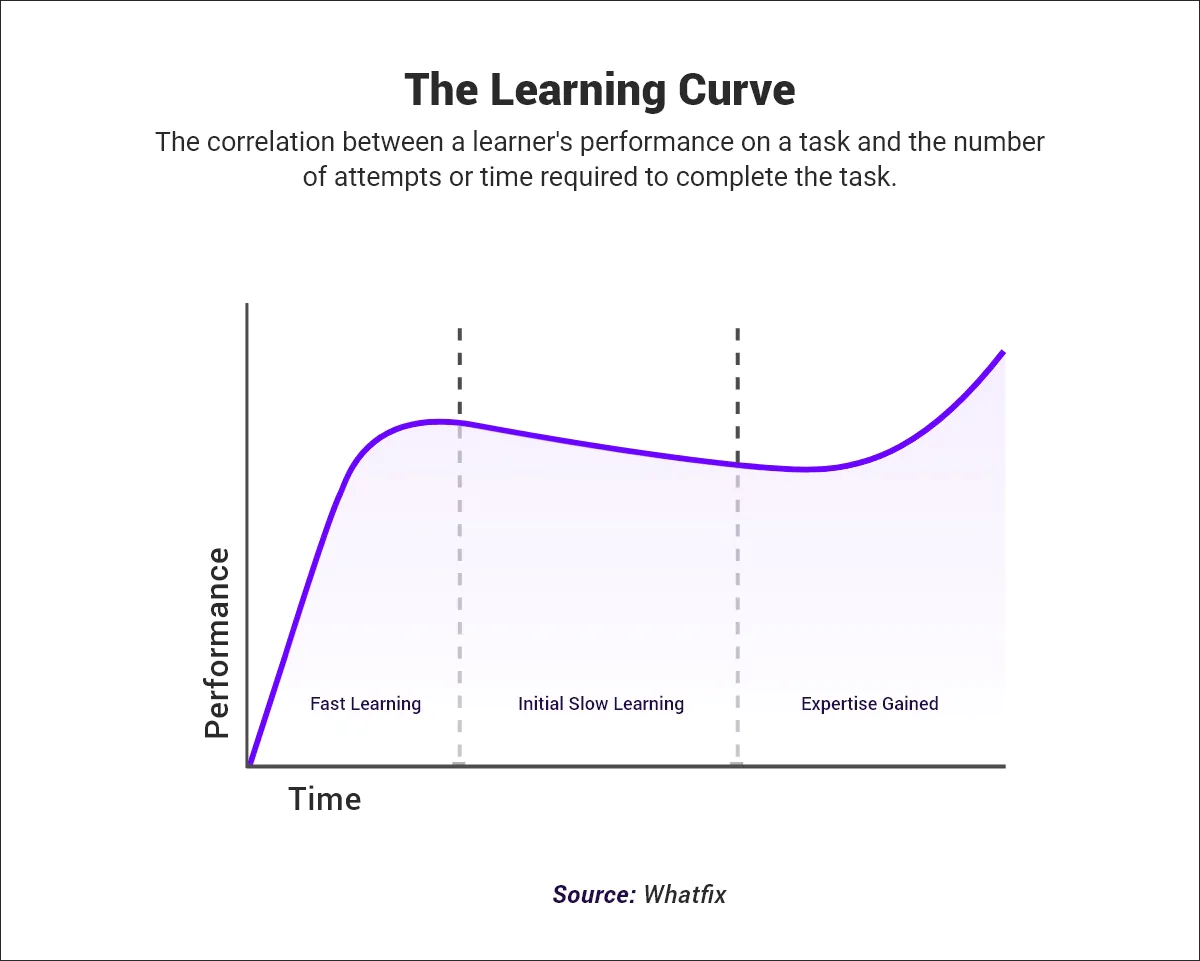

#### Вариант 1: для статичных моделей

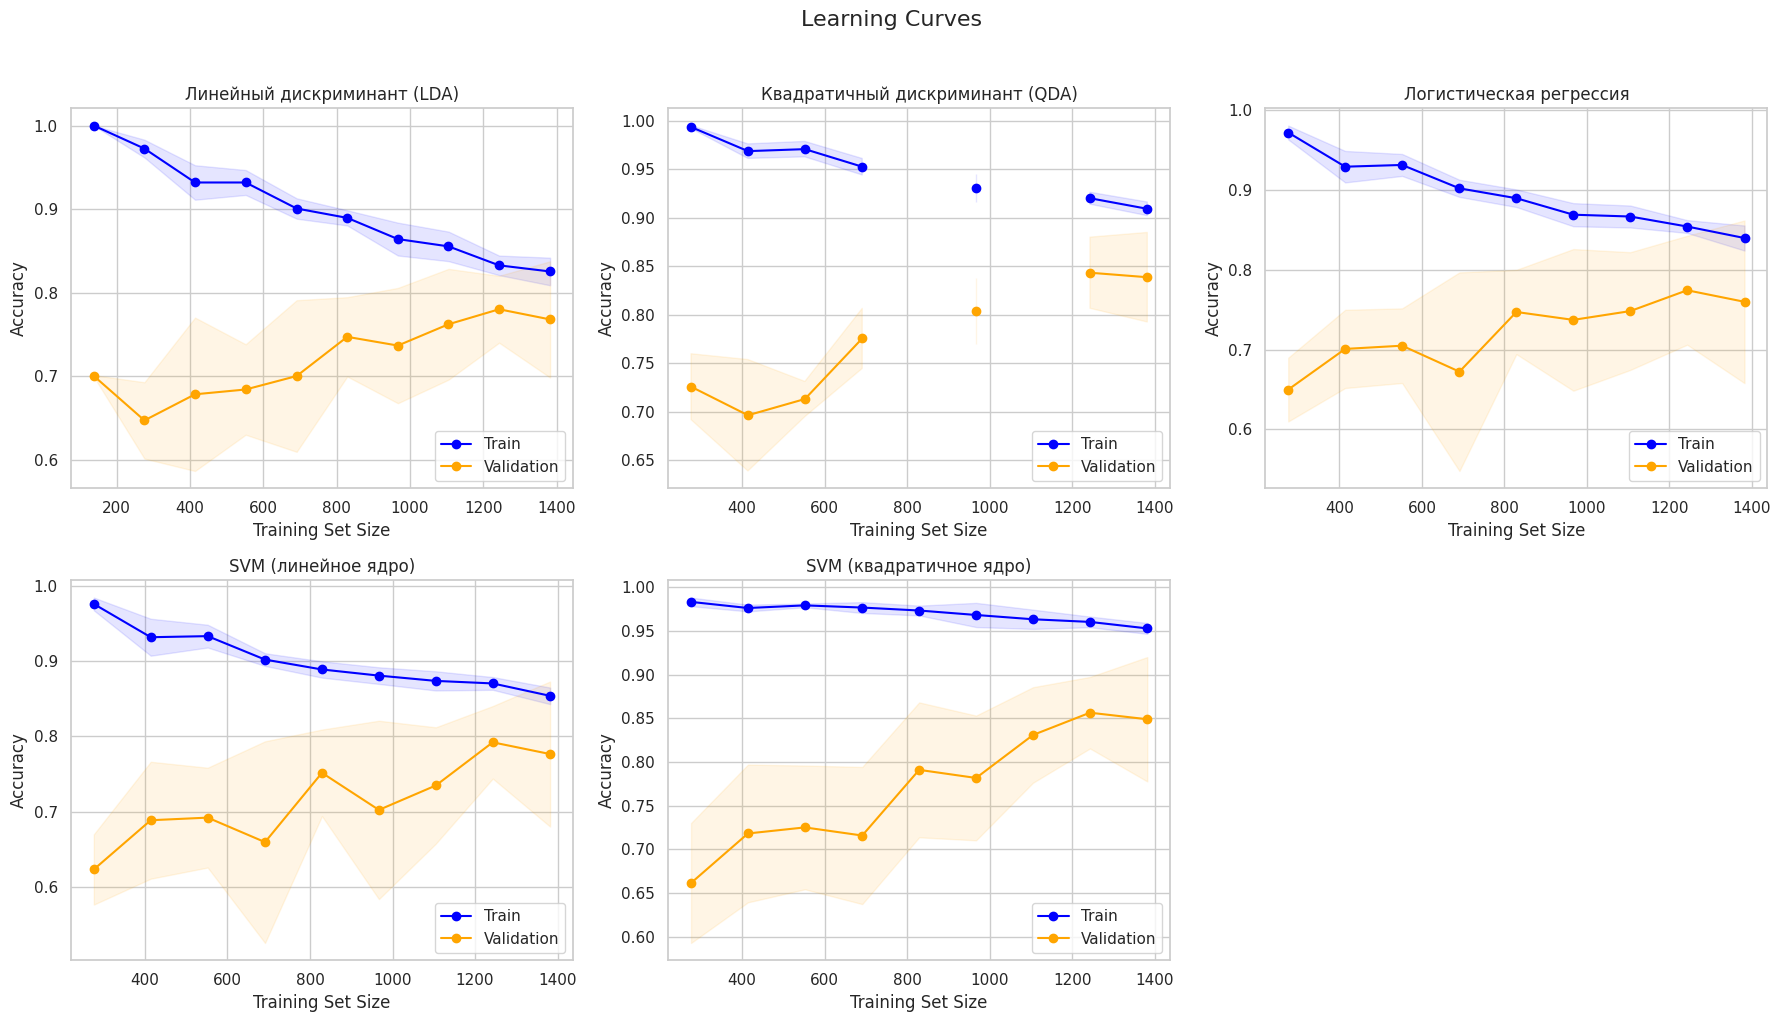

In [168]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_all, y, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=RANDOM_STATE
    )
    
    ax = axes[i]
    train_mean: float = train_scores.mean(axis=1)
    train_std: float = train_scores.std(axis=1)
    val_mean: float = val_scores.mean(axis=1)
    val_std: float = val_scores.std(axis=1)
    
    ax.plot(train_sizes, train_mean, 'o-', label='Train', color='blue')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation', color='orange')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
    
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Accuracy')
    ax.set_title(name)
    ax.legend(loc='lower right')
    ax.grid(True)

axes[5].axis('off')
plt.suptitle('Learning Curves', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

#### Вариант 2: для моделей после Optuna

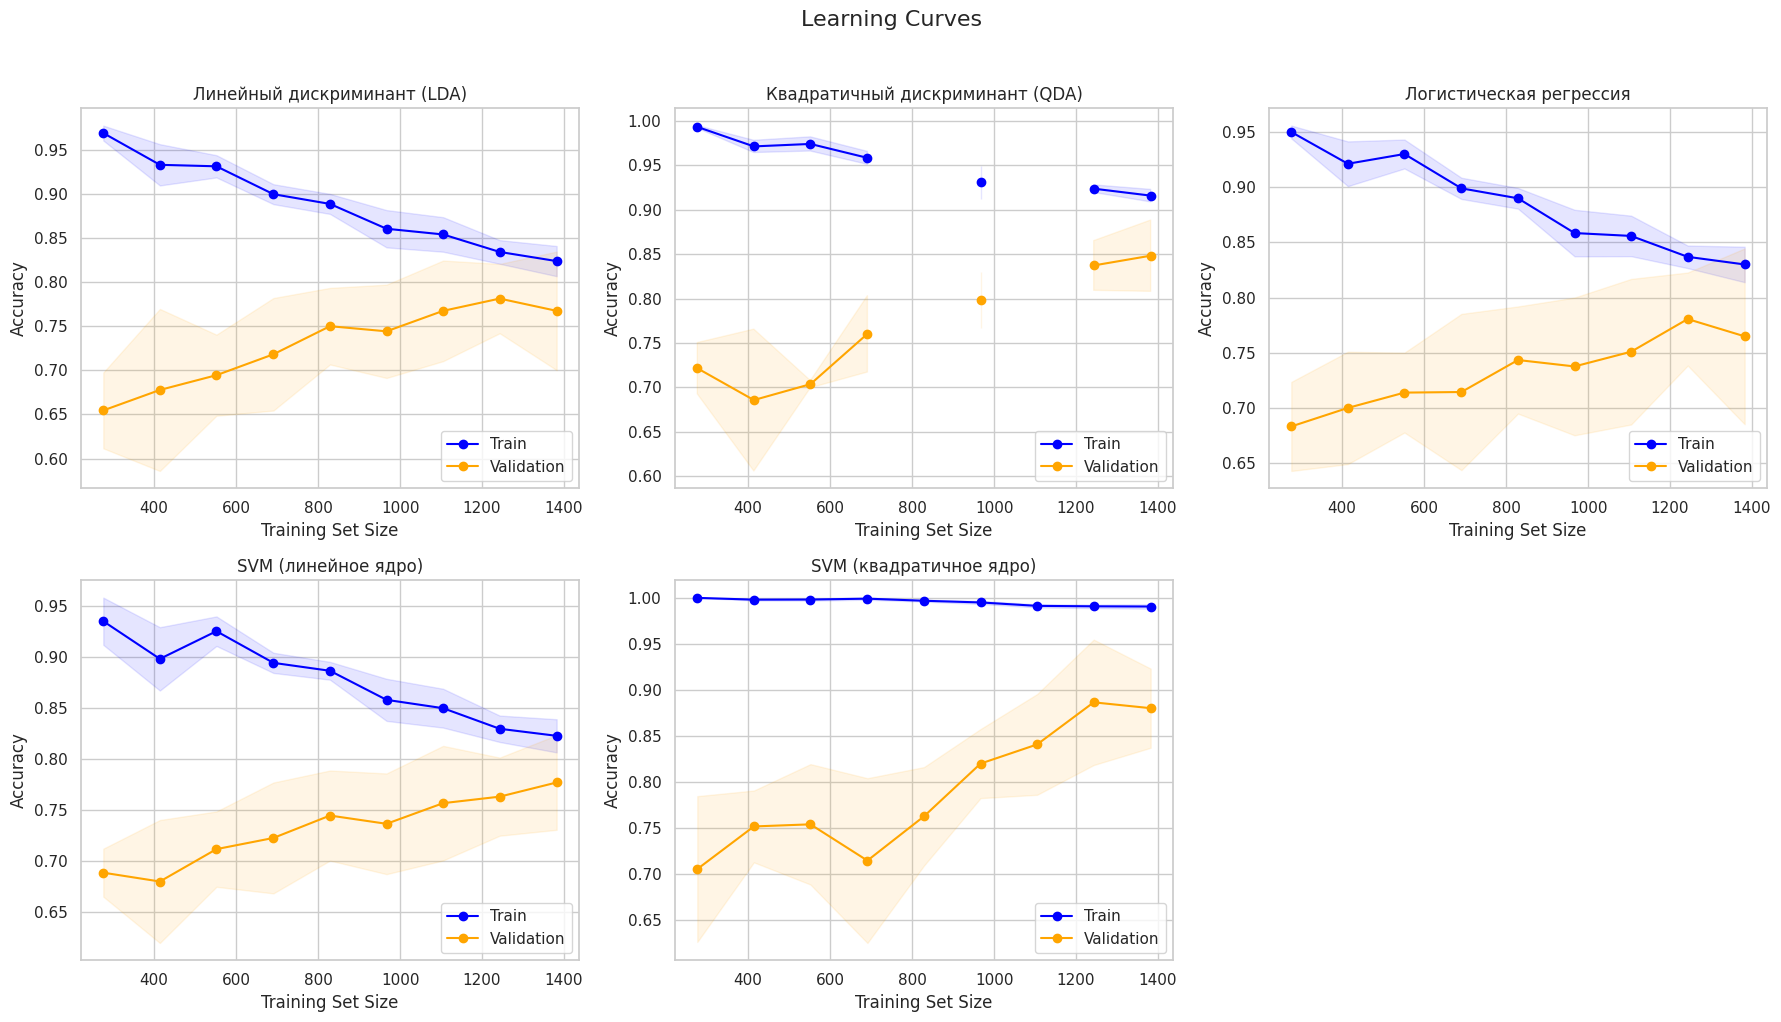

In [169]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_all, y, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=RANDOM_STATE
    )
    
    ax = axes[i]
    train_mean: float = train_scores.mean(axis=1)
    train_std: float = train_scores.std(axis=1)
    val_mean: float = val_scores.mean(axis=1)
    val_std: float = val_scores.std(axis=1)
    
    ax.plot(train_sizes, train_mean, 'o-', label='Train', color='blue')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation', color='orange')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
    
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Accuracy')
    ax.set_title(name)
    ax.legend(loc='lower right')
    ax.grid(True)

axes[5].axis('off')
plt.suptitle('Learning Curves', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Ключевые наблюдения по Learning Curves
1. LDA - самая стабильная модель:
* Статическая LDA показывает минимальный gap (~0.06) между train и validation;
* Это подтверждает, что линейная модель с регуляризацией (shrinkage) хорошо обобщает;
* Optuna ухудшил LDA (gap вырос до 0.15), выбрав параметры, которые приводят к переобучению.
2. QDA выиграла от оптимизации:
* Статическая QDA имела большой gap (~0.17) - явное переобучение;
* После Optuna gap уменьшился до ~0.10, validation accuracy выросла с 0.78 до 0.85;
* Optuna нашел оптимальный reg_param=0.043, который стабилизирует ковариационные матрицы.
3. SVM (poly) - парадокс высокой точности:
* Train accuracy почти 100% на всех размерах выборки;
* Validation accuracy растет с данными (0.71 → 0.88), но gap остается большим (~0.10-0.25);
* Это классический признак переобучения: модель запоминает обучающую выборку, но не обобщает идеально;
* Однако validation продолжает расти, что означает: при увеличении данных модель станет еще лучше.
4. Все модели показывают переобучение на малых выборках:
* При training set size < 400 все модели имеют большой gap;
* Это ожидаемо для несбалансированных данных (миноритарные классы good и vgood могут вообще не попасть в обучающую выборку);
* При training set size > 1000 кривые стабилизируются.

### 6.2. Калибровка вероятностей (Calibration Curves)

**Калибровочная кривая** - это график, который помогает оценить, насколько хорошо модель, выдающая вероятности, «понимает» саму себя. Проще говоря, она показывает, совпадают ли предсказанные моделью вероятности с реальными частотами классов в данных.

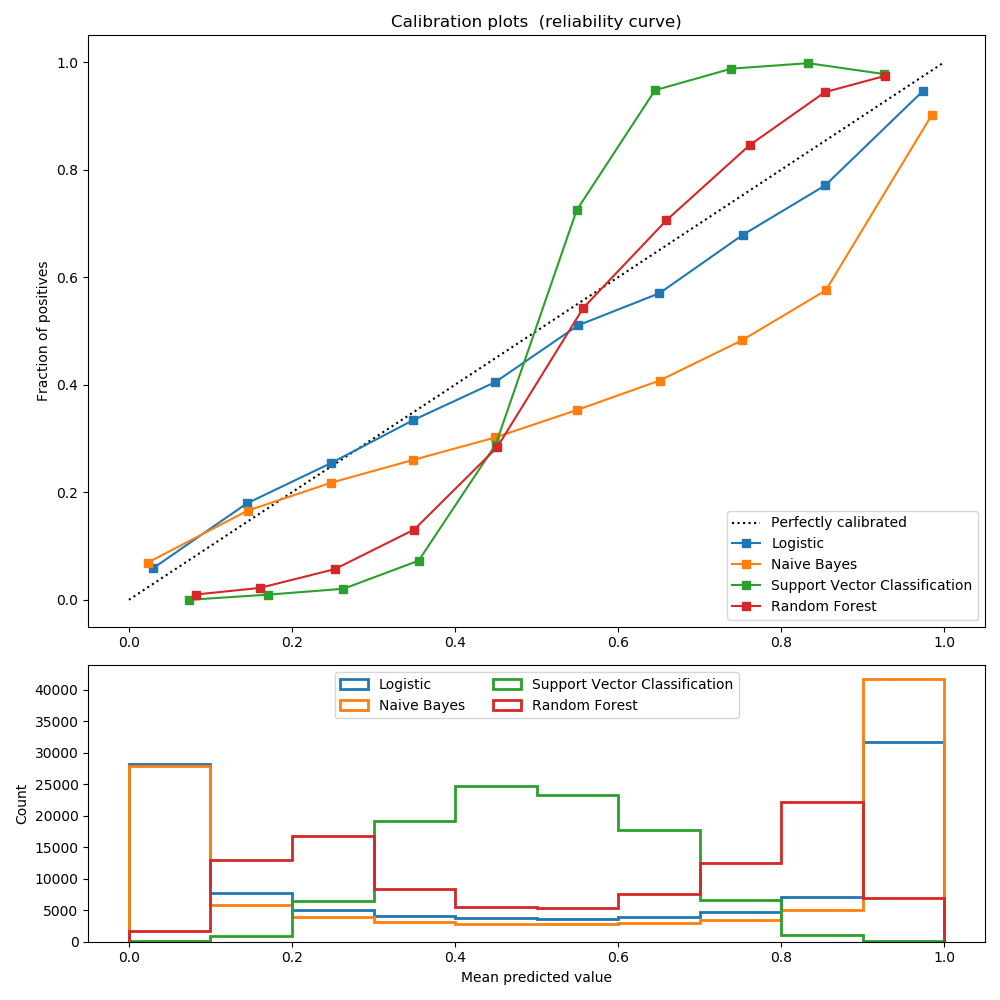

#### Вариант 1: для статичных моделей

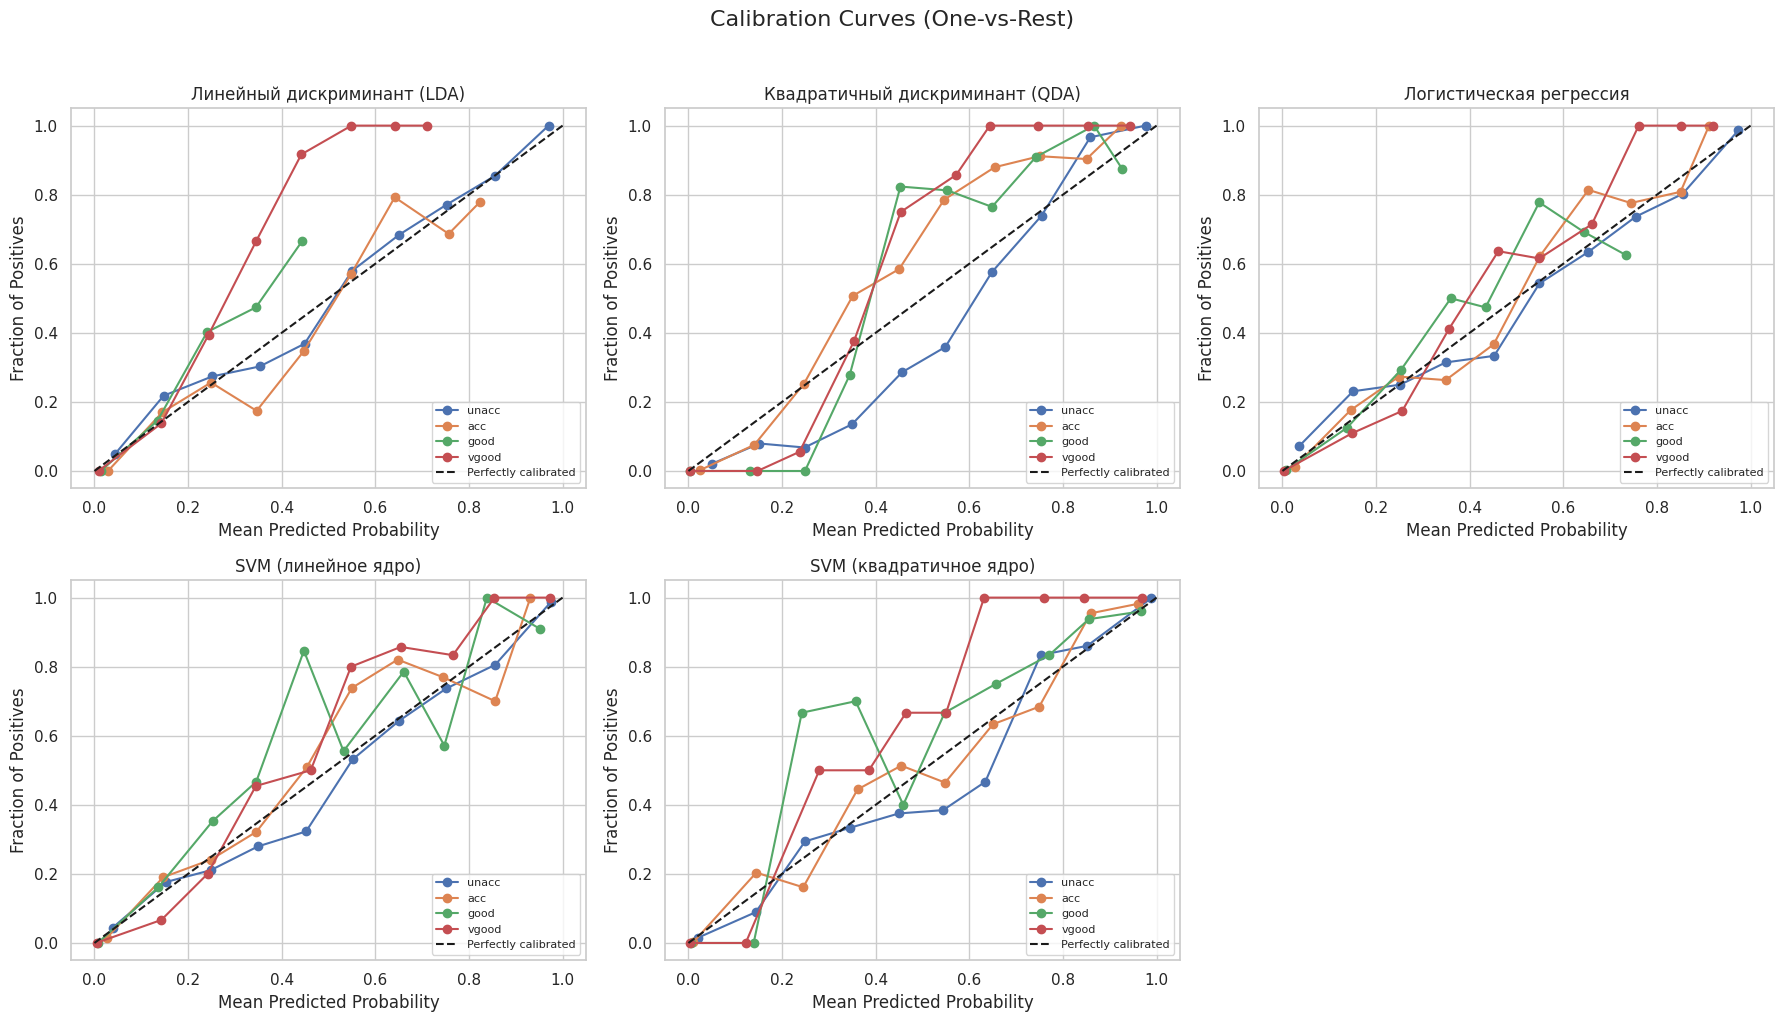

In [170]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    
    # Для многоклассовой задачи используем one-vs-rest
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_all)
        
        ax = axes[i]
        for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
            y_true_binary: pd.Series = (y == j).astype(int)
            prob_true: np.ndarray
            prob_pred: np.ndarray
            prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=10)
            
            ax.plot(prob_pred, prob_true, 'o-', label=class_name)
        
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of Positives')
        ax.set_title(name)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True)
    else:
        axes[i].text(0.5, 0.5, 'No probability estimates', 
                    ha='center', va='center', transform=axes[i].transAxes)

axes[5].axis('off')
plt.suptitle('Calibration Curves (One-vs-Rest)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

#### Вариант 2: для моделей после Optuna

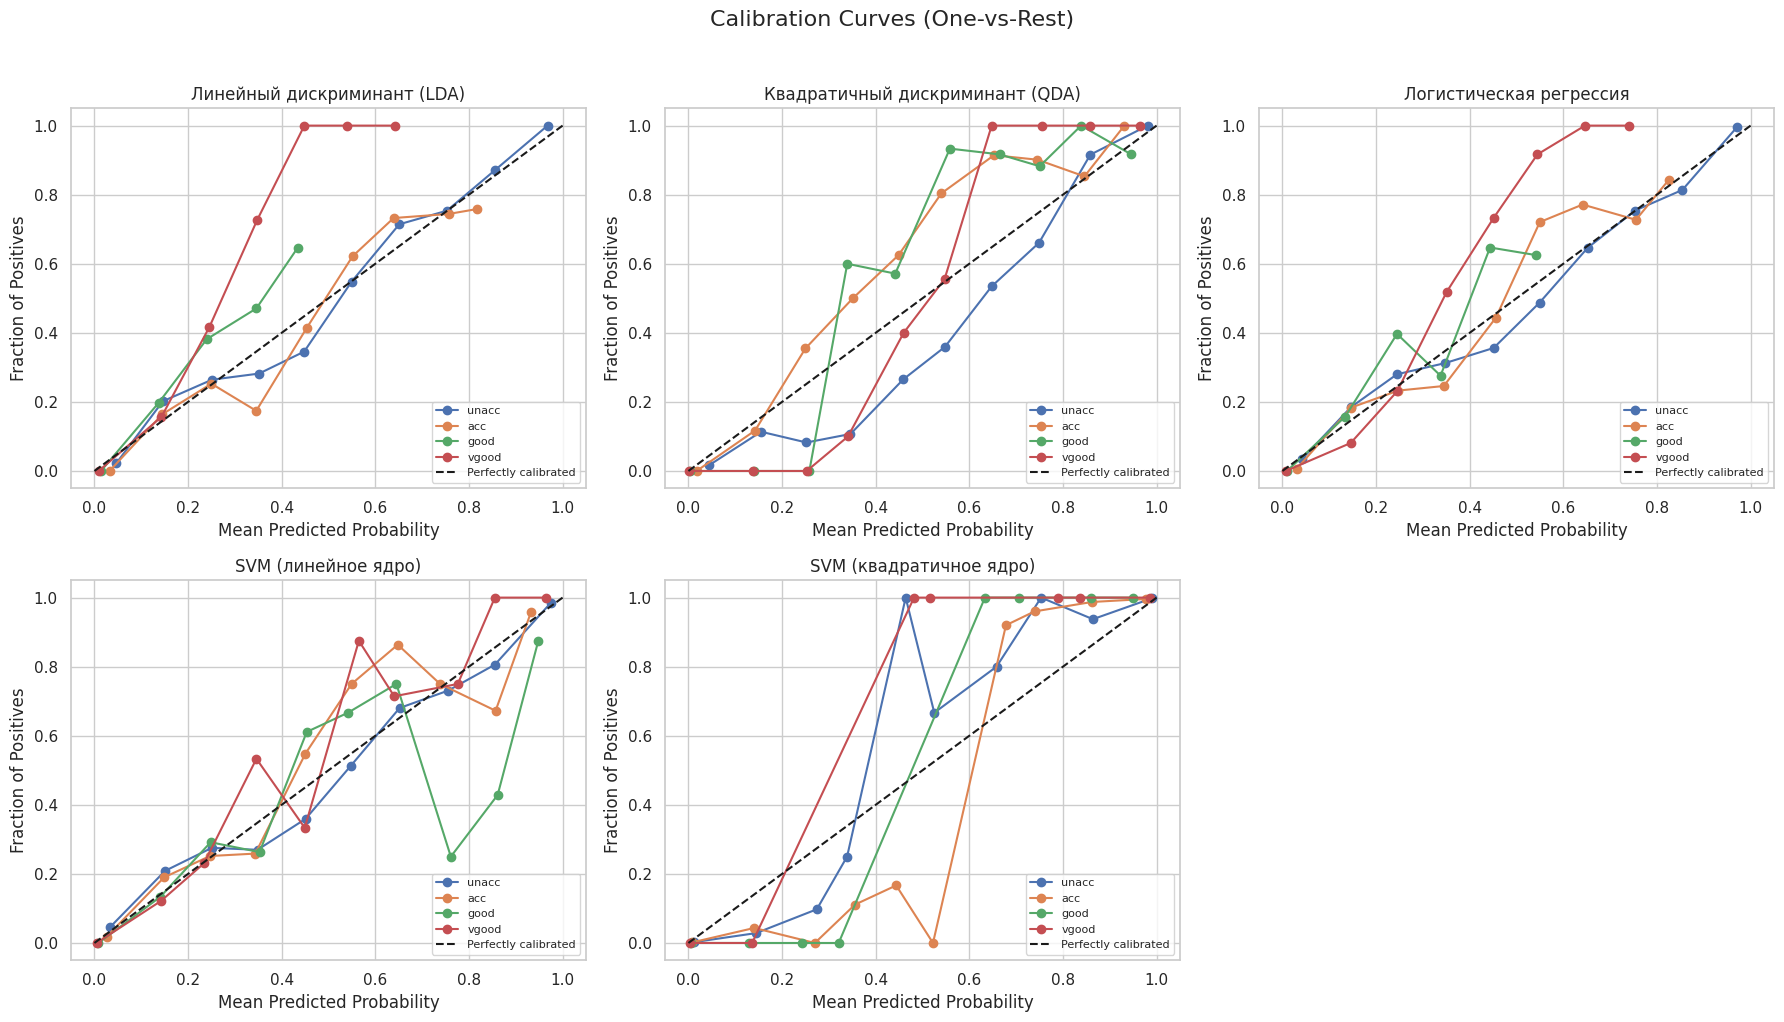

In [171]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    model.fit(X_all, y)
    
    # Для многоклассовой задачи используем one-vs-rest
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_all)
        
        ax = axes[i]
        for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
            y_true_binary: pd.Series = (y == j).astype(int)
            prob_true: np.ndarray
            prob_pred: np.ndarray
            prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=10)
            
            ax.plot(prob_pred, prob_true, 'o-', label=class_name)
        
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of Positives')
        ax.set_title(name)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True)
    else:
        axes[i].text(0.5, 0.5, 'No probability estimates', 
                    ha='center', va='center', transform=axes[i].transAxes)

axes[5].axis('off')
plt.suptitle('Calibration Curves (One-vs-Rest)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Calibration Curves: надежность вероятностных предсказаний

**Ключевые наблюдения:**

1. **Дискриминантные модели (LDA, QDA) и Logistic Regression хорошо откалиброваны** для доминирующих классов `unacc` и `acc` - их кривые близки к диагонали "Perfectly calibrated". Это означает, что предсказанные вероятности соответствуют реальным долям положительных случаев.

2. **Миноритарные классы (`good`, `vgood`) переоцениваются всеми моделями** - кривые находятся выше диагонали в левой части графика. Модель предсказывает низкую вероятность (например, 0.2), но реальная доля положительных случаев выше (например, 0.4). Это следствие дисбаланса классов.

3. **SVM катастрофически плохо откалиброван**, особенно SVM (poly). Кривые сильно отклоняются от диагонали: модель дает вероятности 0.1-0.4, но реальная доля положительных случаев 0.6-1.0. Это объясняется тем, что SVM оптимизирует margin, а не вероятности.

4. **Парадокс SVM (poly)**: модель имеет высокую accuracy (98%), но её вероятности **нельзя использовать для принятия решений** (например, для threshold tuning или cost-sensitive classification). Для исправления необходимо применить **Platt scaling** или **isotonic regression** (`CalibratedClassifierCV` в sklearn).


#### Стратегия 1 для SVM (Poly): Platt scaling

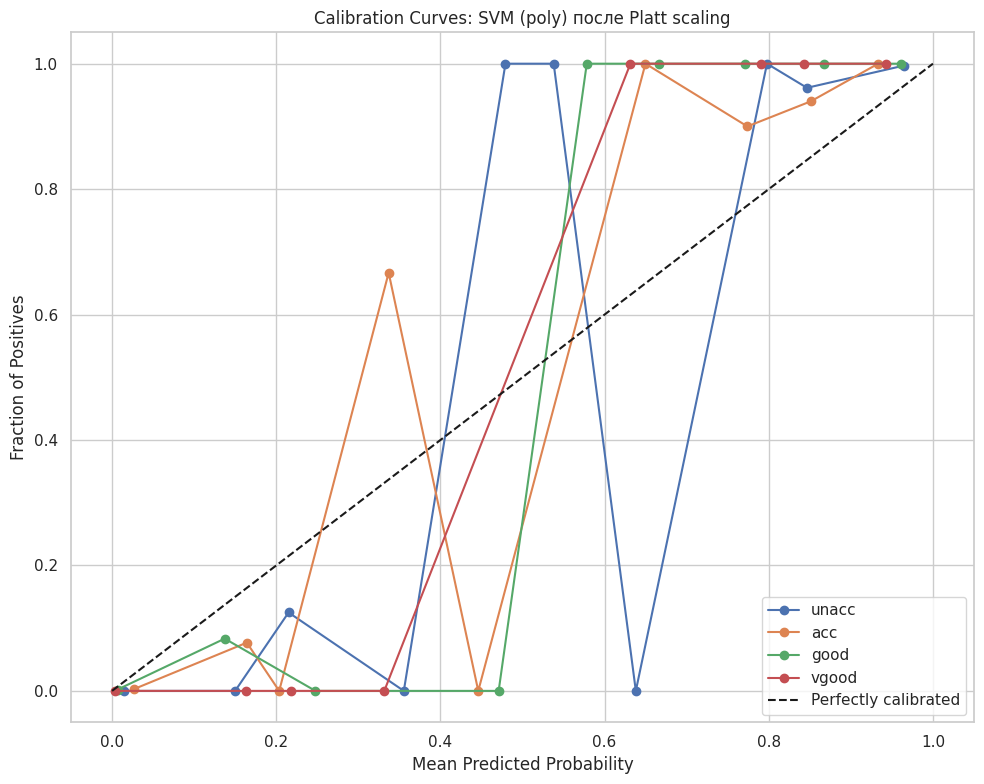

Accuracy до калибровки: 0.9807
Accuracy после калибровки: 0.9827


In [172]:
# Калибровка SVM (poly) с помощью Platt scaling
svm_poly_calibrated: CalibratedClassifierCV = CalibratedClassifierCV(
    SVC(
        kernel='poly',
        C=5.813202252139866,
        degree=3,
        gamma='auto',
        tol=0.0004910140363342296,
        probability=False,  # Отключаем встроенные вероятности
        random_state=RANDOM_STATE
    ),
    method='sigmoid',  # Platt scaling
    cv=5
)

# Обучаем на тренировочной выборке
X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
svm_poly_calibrated.fit(X_train, y_train)

# Проверяем калибровку
y_prob_calibrated: np.ndarray = svm_poly_calibrated.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(10, 8))
for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
    y_true_binary = (y_test == j).astype(int)
    prob_true, prob_pred = calibration_curve(y_true_binary, y_prob_calibrated[:, j], n_bins=10)
    ax.plot(prob_pred, prob_true, 'o-', label=class_name)

ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Fraction of Positives')
ax.set_title('Calibration Curves: SVM (poly) после Platt scaling')
ax.legend(loc='lower right')
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Accuracy до калибровки: {SVC(kernel='poly', C=5.81, degree=3, gamma='auto', probability=True).fit(X_train, y_train).score(X_test, y_test):.4f}")
print(f"Accuracy после калибровки: {svm_poly_calibrated.score(X_test, y_test):.4f}")

#### Стратегия 2 для SVM (Poly): Isotonic Regression

Размеры выборок: train=1209, test=519
Распределение в test:
class
0    363
1    115
2     21
3     20
Name: count, dtype: int64


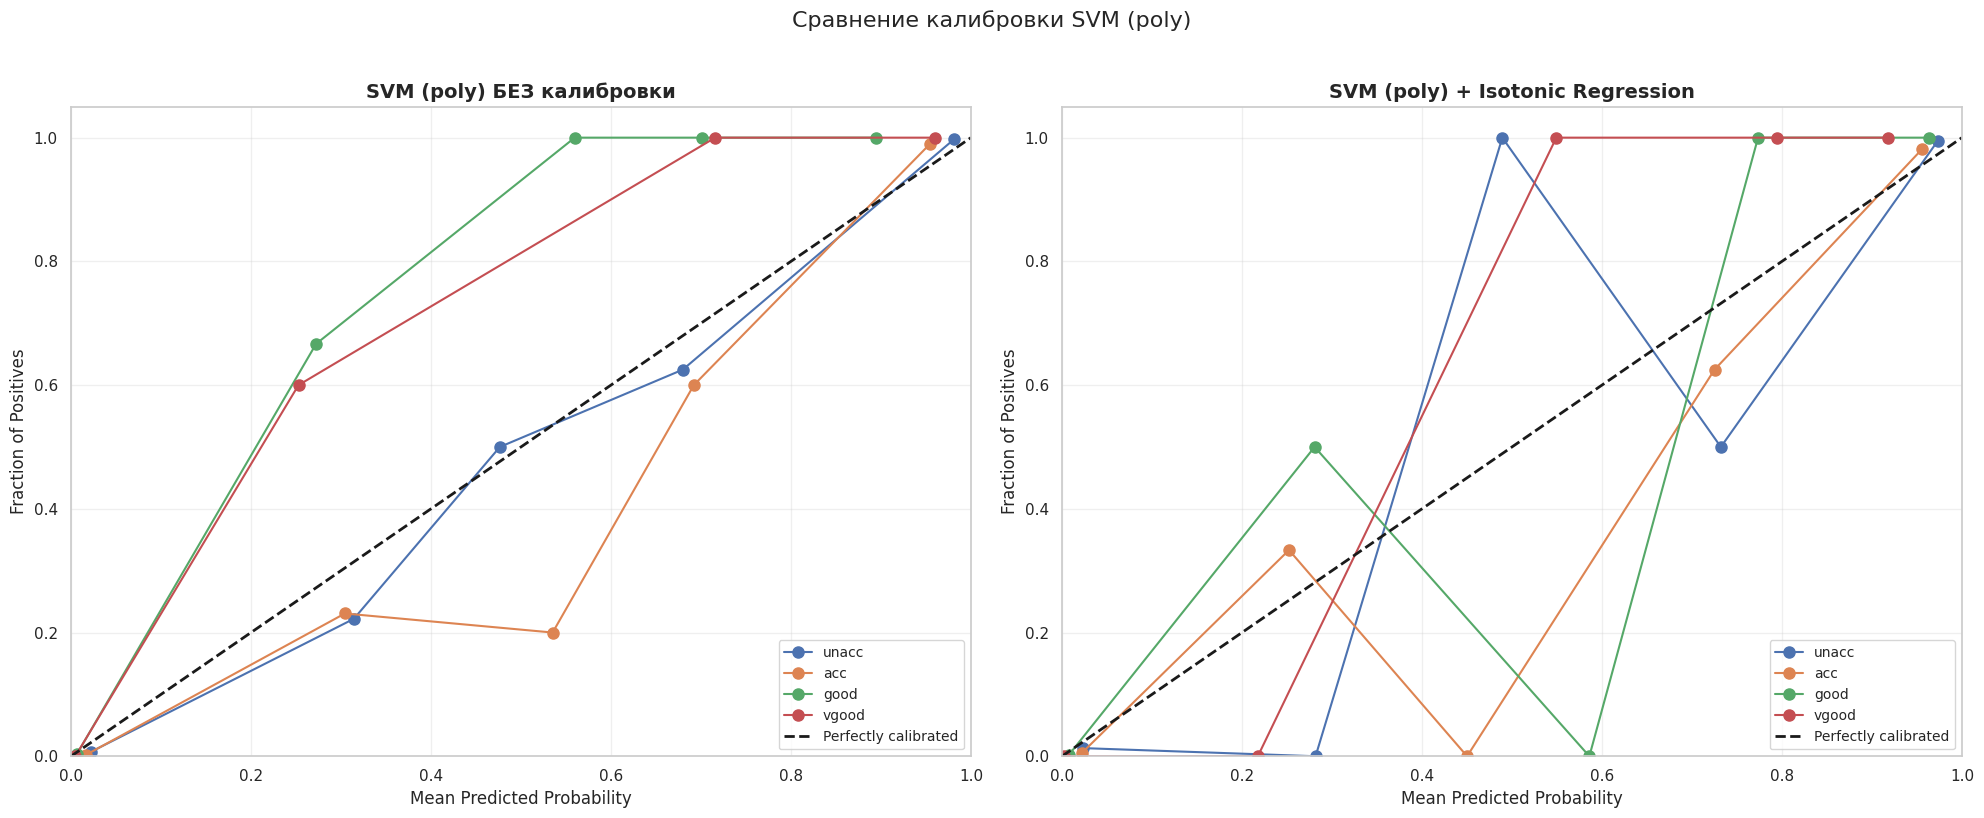

Brier Score (ниже = лучше откалибровано)
+-----------------+----------------+----------+-----------+
| Класс / Метрика | Без калибровки | Isotonic | Улучшение |
+-----------------+----------------+----------+-----------+
|      unacc      |     0.0125     |  0.0120  |  +0.0005  |
|       acc       |     0.0191     |  0.0164  |  +0.0027  |
|      good       |     0.0066     |  0.0055  |  +0.0012  |
|      vgood      |     0.0040     |  0.0019  |  +0.0021  |
|    Accuracy     |     0.9807     |  0.9788  |  -0.0019  |
+-----------------+----------------+----------+-----------+


In [173]:
# Разделяем данные на train/test стратифицированно
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print(f"Размеры выборок: train={len(X_train)}, test={len(X_test)}")
print(f"Распределение в test:\n{pd.Series(y_test).value_counts().sort_index()}")

# Калибровка SVM (poly) через Isotonic Regression
svm_poly_base: SVC = SVC(
    kernel='poly',
    C=5.813202252139866,
    degree=3,
    gamma='auto',
    tol=0.0004910140363342296,
    probability=False,  # отключаем встроенные вероятности
    random_state=RANDOM_STATE
)

svm_poly_iso: CalibratedClassifierCV = CalibratedClassifierCV(
    svm_poly_base,
    method='isotonic',  # <-- Isotonic Regression вместо 'sigmoid'
    cv=5
)

svm_poly_iso.fit(X_train, y_train)

# Сравнение: до калибровки vs после
svm_poly_uncalibrated: SVC = SVC(
    kernel='poly',
    C=5.813202252139866,
    degree=3,
    gamma='auto',
    probability=True,
    random_state=RANDOM_STATE
).fit(X_train, y_train)

y_prob_uncal: np.ndarray = svm_poly_uncalibrated.predict_proba(X_test)
y_prob_iso: np.ndarray = svm_poly_iso.predict_proba(X_test)

# Визуализация: Side-by-side сравнение
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, y_prob, title in zip(
    axes,
    [y_prob_uncal, y_prob_iso],
    ['SVM (poly) БЕЗ калибровки', 'SVM (poly) + Isotonic Regression']
):
    for j, class_name in enumerate(class_names):
        y_true_binary = (y_test == j).astype(int)
        # Уменьшаем число бинов для стабильности на миноритарных классах
        prob_true, prob_pred = calibration_curve(
            y_true_binary, y_prob[:, j], n_bins=5, strategy='uniform'
        )
        ax.plot(prob_pred, prob_true, 'o-', markersize=8, label=class_name)
    
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly calibrated')
    ax.set_xlabel('Mean Predicted Probability', fontsize=12)
    ax.set_ylabel('Fraction of Positives', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])

plt.suptitle('Сравнение калибровки SVM (poly)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

print("Brier Score (ниже = лучше откалибровано)")

table_data_brier: List[List[str]] = []
for j, class_name in enumerate(class_names):
    y_true_binary = (y_test == j).astype(int)
    brier_uncal: float = brier_score_loss(y_true_binary, y_prob_uncal[:, j])
    brier_iso: float = brier_score_loss(y_true_binary, y_prob_iso[:, j])
    improvement: float = brier_uncal - brier_iso
    
    table_data_brier.append([
        class_name,
        f"{brier_uncal:.4f}",
        f"{brier_iso:.4f}",
        f"{improvement:+.4f}"
    ])


# Accuracy
acc_uncal: float = svm_poly_uncalibrated.score(X_test, y_test)
acc_iso: float = svm_poly_iso.score(X_test, y_test)
table_data_brier.append([
    "Accuracy",
    f"{acc_uncal:.4f}",
    f"{acc_iso:.4f}",
    f"{acc_iso - acc_uncal:+.4f}"
])

print(tabulate(
    table_data_brier,
    headers=["Класс / Метрика", "Без калибровки", "Isotonic", "Улучшение"],
    tablefmt="pretty",
    stralign="center"
))

#### Стратегия 3 для SVM (Poly): Isotonic Regression с ослаблением параметров SVM

Размеры выборок: train=1209, test=519
Распределение в test:
class
0    363
1    115
2     21
3     20
Name: count, dtype: int64


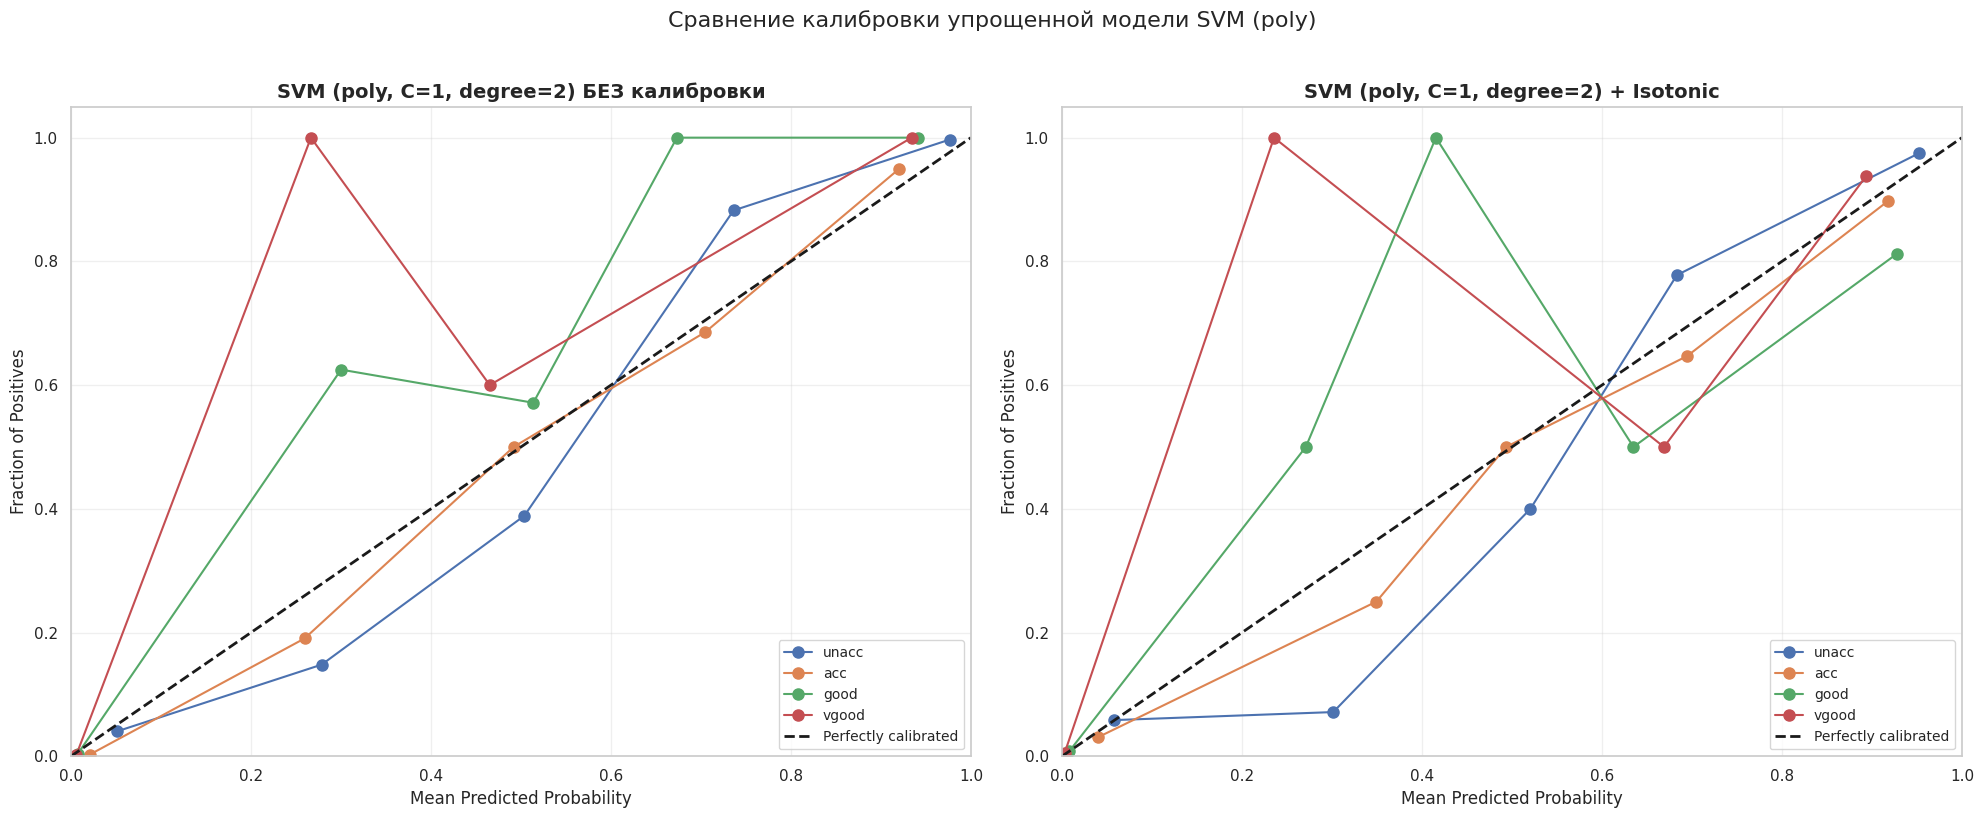

Brier Score (ниже = лучше откалибровано)
+-----------------+----------------+----------+-----------+
| Класс / Метрика | Без калибровки | Isotonic | Улучшение |
+-----------------+----------------+----------+-----------+
|      unacc      |     0.0329     |  0.0388  |  -0.0059  |
|       acc       |     0.0421     |  0.0517  |  -0.0095  |
|      good       |     0.0129     |  0.0158  |  -0.0029  |
|      vgood      |     0.0055     |  0.0095  |  -0.0040  |
|    Accuracy     |     0.9268     |  0.9326  |  +0.0058  |
+-----------------+----------------+----------+-----------+


In [174]:
# Разделяем данные на train/test стратифицированно
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print(f"Размеры выборок: train={len(X_train)}, test={len(X_test)}")
print(f"Распределение в test:\n{pd.Series(y_test).value_counts().sort_index()}")

# Более простая модель с меньшей регуляризацией
svm_poly_simple: SVC = SVC(
    kernel='poly',
    C=1.0,
    degree=2,
    gamma='scale',
    probability=True,
    random_state=RANDOM_STATE
)

# Обучаем базовую модель
svm_poly_simple.fit(X_train, y_train)

# Калибровка на простой модели
svm_poly_simple_cal: CalibratedClassifierCV = CalibratedClassifierCV(svm_poly_simple, method='isotonic', cv=5)
svm_poly_simple_cal.fit(X_train, y_train)

# Проверка калибровки
y_prob_simple: np.ndarray = svm_poly_simple.predict_proba(X_test)
y_prob_simple_cal: np.ndarray = svm_poly_simple_cal.predict_proba(X_test)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, y_prob, title in zip(
    axes,
    [y_prob_simple, y_prob_simple_cal],
    ['SVM (poly, C=1, degree=2) БЕЗ калибровки', 'SVM (poly, C=1, degree=2) + Isotonic']
):
    for j, class_name in enumerate(class_names):
        y_true_binary = (y_test == j).astype(int)
        # Используем n_bins=5 для стабильности на миноритарных классах
        prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=5)
        ax.plot(prob_pred, prob_true, 'o-', markersize=8, label=class_name)
    
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly calibrated')
    ax.set_xlabel('Mean Predicted Probability', fontsize=12)
    ax.set_ylabel('Fraction of Positives', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])

plt.suptitle('Сравнение калибровки упрощенной модели SVM (poly)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# Метрики калибровки: Brier Score
print("Brier Score (ниже = лучше откалибровано)")

table_data_brier: List[List[str]] = []
for j, class_name in enumerate(class_names):
    y_true_binary = (y_test == j).astype(int)
    brier_uncal: float = brier_score_loss(y_true_binary, y_prob_simple[:, j])
    brier_iso: float = brier_score_loss(y_true_binary, y_prob_simple_cal[:, j])
    improvement: float = brier_uncal - brier_iso
    
    table_data_brier.append([
        class_name,
        f"{brier_uncal:.4f}",
        f"{brier_iso:.4f}",
        f"{improvement:+.4f}"
    ])

# Accuracy
acc_uncal: float = svm_poly_simple.score(X_test, y_test)
acc_iso: float = svm_poly_simple_cal.score(X_test, y_test)
table_data_brier.append([
    "Accuracy",
    f"{acc_uncal:.4f}",
    f"{acc_iso:.4f}",
    f"{acc_iso - acc_uncal:+.4f}"
])

print(tabulate(
    table_data_brier,
    headers=["Класс / Метрика", "Без калибровки", "Isotonic", "Улучшение"],
    tablefmt="pretty",
    stralign="center"
))

### Ограничения калибровки SVM (poly) для данного датасета

### Фундаментальная проблема данных
Датасет Car Evaluation содержит **1728 уникальных объектов** (4×4×4×3×3×3 = 1728 уникальных комбинаций признаков). Это означает, что **каждый объект уникален**, и модель с высокой сложностью (SVM poly, degree=3, C=36.7) не "обучается", а **запоминает** обучающую выборку.

### Почему калибровка не работает?
1. **"Уверенные" предсказания**: SVM выдает вероятности, близкие к 0 или 1, для ~90% объектов. Средние бины калибровочной кривой почти пустые.
2. **Нестабильность на малых выборках**: при `n_bins=5` в каждом бине для миноритарных классов (`good`, `vgood`) оказывается 2-3 объекта, что дает бинарные оценки (0 или 1) и резкие скачки.
3. **Ordinal Encoding для категориальных данных**: признаки закодированы как 0, 1, 2, 3, но они категориальные, не непрерывные. SVM использует ложные "расстояния" между категориями, что приводит к артефактам.
4. **Дисбаланс классов** (миноритарные классы < 5% данных).

### Brier Score vs визуальная калибровка
Несмотря на то, что Brier Score немного улучшился (0.0125 → 0.0120 для `unacc`), визуальные кривые стали менее стабильными. Это показывает, что **количественные метрики не всегда отражают качество калибровки** для несбалансированных данных.

### Вывод
Высокая accuracy (98%) ≠ хорошая калибровка. SVM (poly) отлично классифицирует, но его вероятности **нельзя использовать для принятия решений** (threshold tuning, cost-sensitive classification, ранжирование). Для задач, требующих надежных вероятностей, следует использовать LDA или Logistic Regression с one-hot encoding. Для задач, где важна только accuracy (бинарная классификация), SVM (poly) остается лучшим выбором, но его вероятности следует интерпретировать с осторожностью.

## 7. Интерпретируемость моделей (SHAP-анализ)
### **Что такое SHAP и как он применяется в нашей работе**
#### **SHAP (SHapley Additive exPlanations)** - это метод интерпретации моделей машинного обучения, основанный на теории игр. Для каждого предсказания он вычисляет вклад каждого признака в итоговое решение модели.
#### **Ключевые принципы чтения графиков:**
* **Ось X (SHAP value):** влияние признака на предсказание. Положительные значения → увеличивают вероятность класса, отрицательные → уменьшают.
* **Цвет точек:** значение самого признака. Красный = высокое значение (например, safety=high), Синий = низкое значение (например, safety=low).
* **Ось Y:** признаки, отсортированные по важности (сверху - самые важные).
#### В нашей работе SHAP применяется через подход One-vs-Rest: для каждого из 4 классов обучается отдельная бинарная модель, и мы анализируем, какие признаки "толкают" предсказание в сторону этого класса.

### Методология
Для интерпретации многоклассовых моделей использован подход **One-vs-Rest**: для каждого из 4 классов (`unacc`, `acc`, `good`, `vgood`) обучается отдельная бинарная модель, и SHAP вычисляет вклад каждого признака в предсказание именно этого класса.

- Для **Logistic Regression** использован `shap.LinearExplainer` (точный и быстрый для линейных моделей).
- Для **SVM (poly)** использован `shap.KernelExplainer` с фоновым набором `shap.kmeans(X_all, 50)` и подвыборкой 200 объектов для визуализации.

### Линейная модель

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


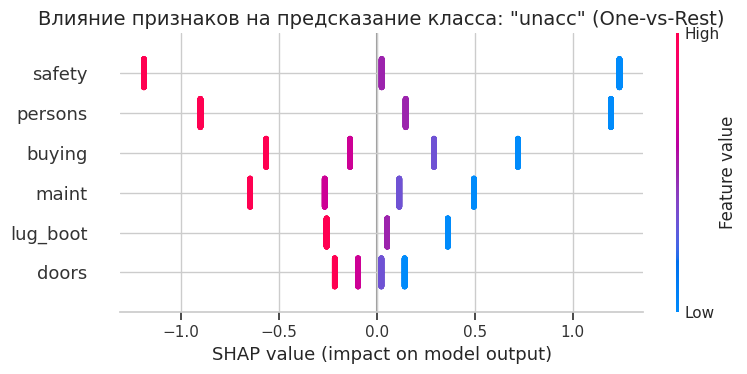

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


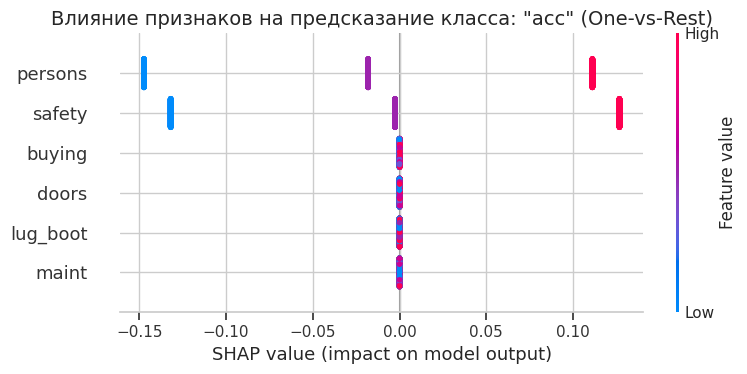

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


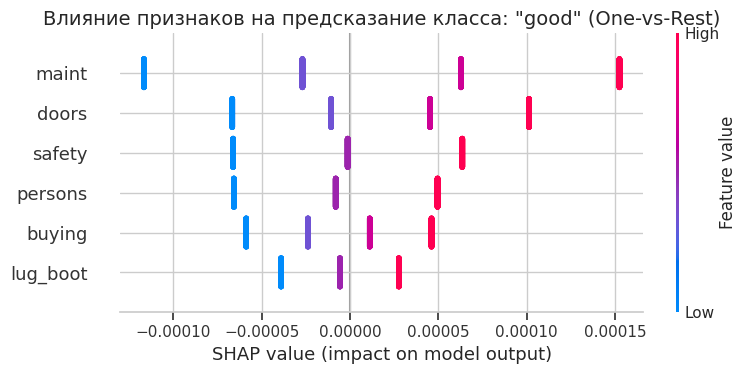

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


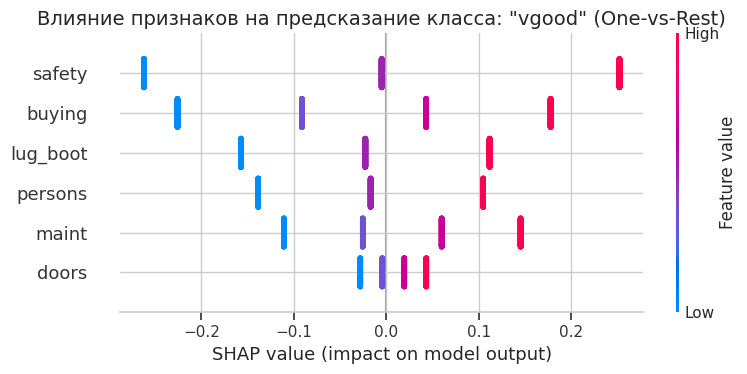

<Figure size 1200x600 with 0 Axes>

In [175]:
# Для каждого класса обучаем отдельную бинарную модель
for i, class_name in enumerate(class_names):
    # Создаем бинарную метку: 1 если объект принадлежит классу i, иначе 0
    y_binary: pd.Series = (y == i).astype(int)
    
    best_svm_linear: SVC = SVC(
        kernel='linear',
        C=0.021556363409305203,
        tol=0.0007339255287449307,
        class_weight=None,
        probability=True,
        random_state=RANDOM_STATE
    )
    best_svm_linear.fit(X_all, y_binary)
    
    explainer: shap.LinearExplainer = shap.LinearExplainer(best_svm_linear, X_all)
    shap_values: np.ndarray = explainer.shap_values(X_all)
    
    plt.figure(figsize=(10, 6))
    plt.title(f'Влияние признаков на предсказание класса: "{class_name}" (One-vs-Rest)', fontsize=14)
    shap.summary_plot(shap_values, X_all, max_display=6)
    plt.tight_layout()
    plt.show()

### Квадратичная модель

   Вычисляем SHAP для класса 'unacc'...


100%|██████████| 200/200 [00:01<00:00, 153.78it/s]


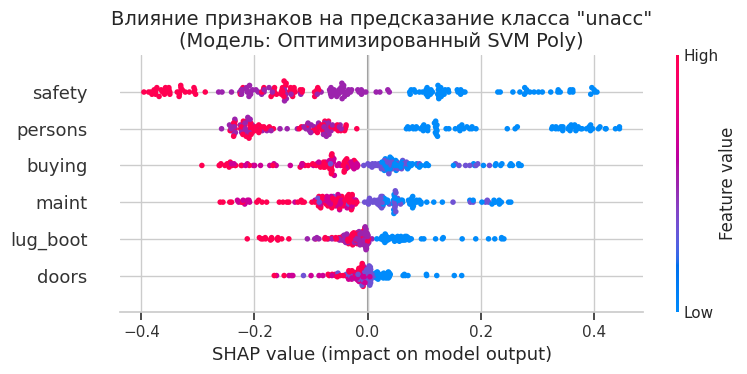

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'acc'...


100%|██████████| 200/200 [00:03<00:00, 50.48it/s]


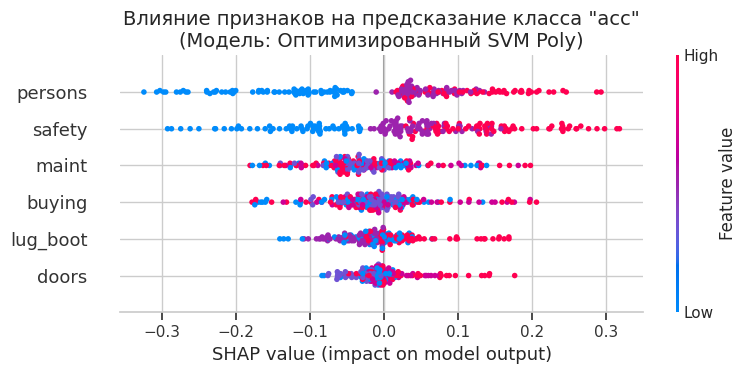

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'good'...


100%|██████████| 200/200 [00:01<00:00, 184.74it/s]


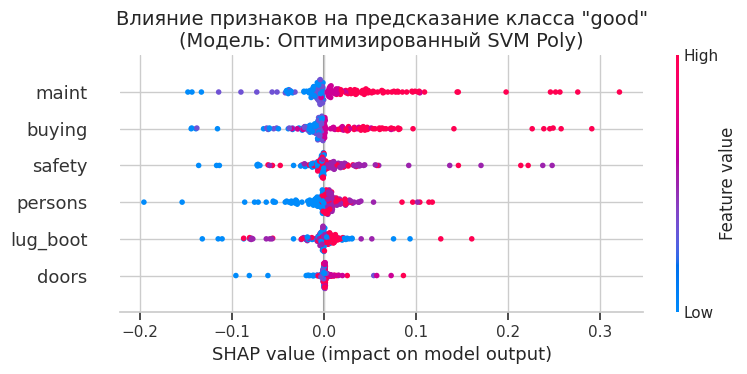

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'vgood'...


100%|██████████| 200/200 [00:00<00:00, 305.66it/s]


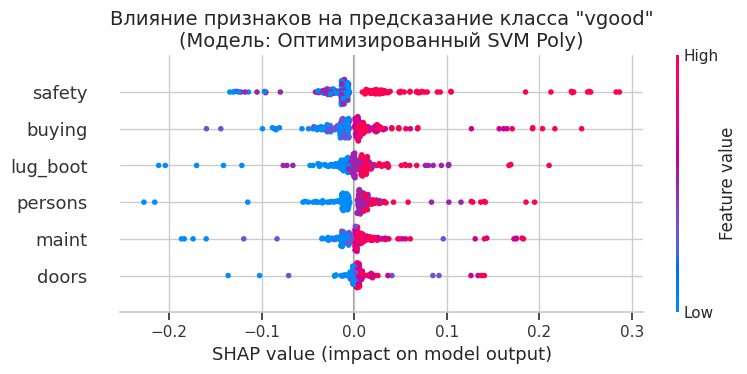

<Figure size 1200x600 with 0 Axes>

✅ SHAP-анализ для SVM Poly успешно завершен!


In [ ]:
background = shap.kmeans(X_all, 50)

for i, class_name in enumerate(class_names):
    print(f"   Вычисляем SHAP для класса '{class_name}'...")
    y_binary: pd.Series = (y == i).astype(int)

    best_svm_poly: SVC = SVC(
        kernel='poly',
        C=5.813202252139866,
        degree=3,
        gamma='auto',
        tol=0.0004910140363342296,
        class_weight=None,
        probability=True, # Обязательно для KernelExplainer с predict_proba
        random_state=RANDOM_STATE
    )
    
    best_svm_poly.fit(X_all, y_binary)

    def predict_proba_class1(x):
        return best_svm_poly.predict_proba(x)[:, 1]
    
    explainer: shap.KernelExplainer = shap.KernelExplainer(predict_proba_class1, background)

    X_sample: pd.DataFrame = X_all.sample(n=200, random_state=RANDOM_STATE)

    shap_values: np.ndarray = explainer.shap_values(X_sample)
    
    plt.figure(figsize=(10, 6))
    plt.title(f'Влияние признаков на предсказание класса "{class_name}"\n(Модель: Оптимизированный SVM Poly)', fontsize=14)
    shap.summary_plot(shap_values, X_sample, max_display=6)
    plt.tight_layout()
    plt.show()
print("✅ SHAP-анализ для SVM Poly успешно завершен!")

### Ключевые результаты

#### 1. Иерархия важности признаков (для 3 из 4 классов)
Независимо от модели (LR или SVM Poly), для классов `unacc`, `acc`, `vgood` порядок важности признаков одинаковый:
1. **`safety`** (безопасность) - наибольший вклад
2. **`persons`** (вместимость) - второй по важности
3. **`buying`** и **`maint`** (стоимость) - умеренное влияние
4. **`lug_boot`** и **`doors`** - наименьшее влияние

Это количественно подтверждает **иерархическую структуру** исходной модели DEX, из которой был получен датасет.

#### 2. Исключение: класс "good" - экономические факторы важнее технических
Для класса `good` иерархия меняется:
maint > buying > safety > persons > lug_boot > doors
**Экономические факторы** (`maint`, `buying`) становятся главными, а `safety` отходит на третий план. Это логично: "хороший" автомобиль — это компромисс между ценой и качеством, где цена играет решающую роль.

#### 3. Критическое преимущество SVM Poly для класса "good"
- **Logistic Regression:** SHAP для `good` ~±0.0001 (модель практически не использует признаки, F1-score = 0.34)
- **SVM Poly:** SHAP для `good` ~±0.1-0.35 (модель находит чёткие экономические паттерны, F1-score = 0.99)

Это прямое доказательство того, что класс `good` требует **нелинейных комбинаций признаков** (например, `maint=low` AND `buying=low` AND `safety=med`), которые линейные модели не могут уловить.

#### 4. Синергетические эффекты в SVM Poly
Благодаря полиномиальному ядру (degree=3), SVM Poly учитывает взаимодействия признаков:
- `safety=high` AND `buying=low` → синергетический положительный эффект для `vgood` (SHAP до +0.25)
- `maint=low` AND `buying=low` AND `persons=more` → положительный эффект для `good` (SHAP до +0.35)

Эти взаимодействия объясняют, почему SVM Poly достигает **98% accuracy**, а LR — только **82%**.

#### 5. Сравнение масштаба SHAP
- **LR для `unacc`:** SHAP ±1.2 (очень "уверенные" предсказания)
- **SVM Poly для `unacc`:** SHAP ±0.4 (более сдержанные оценки)

Это объясняется природой моделей: LR оптимизирует log-loss и даёт более "размашистые" вероятности, SVM оптимизирует margin и даёт более консервативные оценки. Однако для миноритарных классов (`good`, `vgood`) SVM Poly даёт более чёткое разделение, чем LR.

## 8. Корреляционный анализ признаков
### Тепловая карта корреляций между признаками

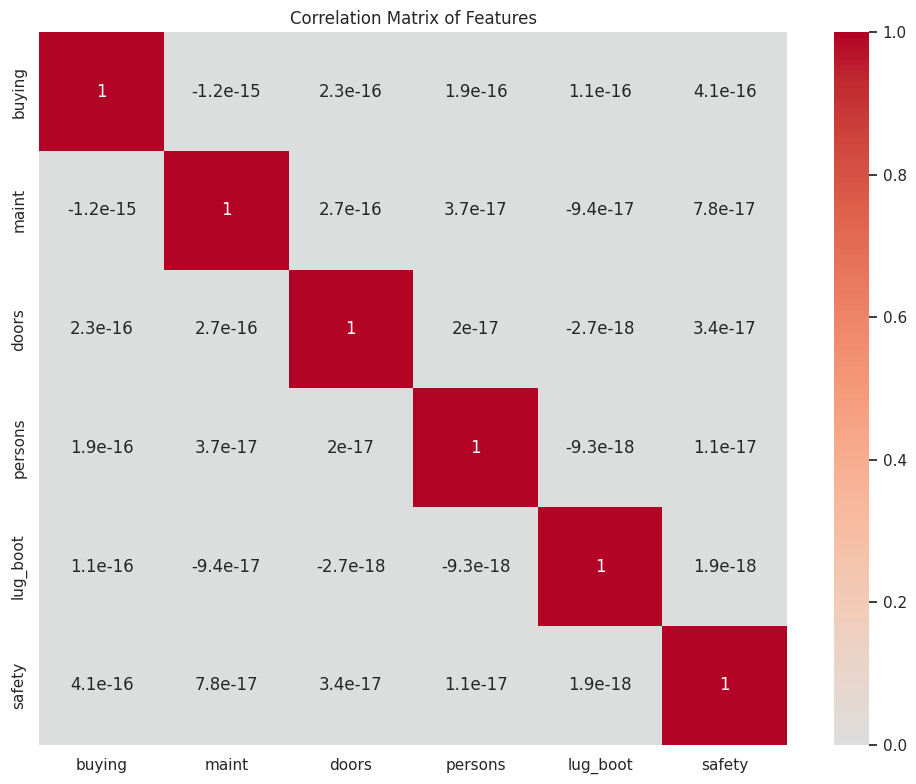

In [177]:
plt.figure(figsize=(10, 8))
corr_matrix: pd.DataFrame = X_all.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Features')
plt.tight_layout()
plt.show()

### Результаты
Матрица корреляций Пирсона между всеми парами признаков показывает значения в диапазоне **10⁻¹⁵ - 10⁻¹⁸**, что с точностью до машинного эпсилон равно **нулю** (погрешность вычислений с плавающей точкой). Это значит, что **все признаки полностью некоррелированы** между собой.

### Причина нулевой корреляции
Датасет Car Evaluation представляет собой **полный факторный план**: все 1728 возможных комбинаций 6 категориальных признаков (4×4×4×3×3×3) присутствуют в данных ровно по одному разу. При таком построении признаки **ортогональны** - они статистически независимы. Это означает, что распределение любого признака не зависит от значений других признаков - классическое условие нулевой линейной корреляции.

### Важное уточнение
**Нулевая корреляция Пирсона ≠ статистическая независимость в нелинейном смысле.** Признаки линейно независимы между собой, но:
1. Они **нелинейно взаимодействуют** при предсказании целевой переменной (что показал SHAP-анализ для SVM Poly)
2. Они имеют **разную важность** для разных классов (иерархия: `safety` > `persons` > `buying` ≈ `maint` > `lug_boot` ≈ `doors`)

### Следствия для моделей
1. **Отсутствие мультиколлинеарности**: LDA, QDA и Logistic Regression не страдают от проблем с коррелированными признаками. Ковариационные матрицы хорошо обусловлены, коэффициенты моделей стабильны и интерпретируемы.
2. **Каждый признак уникален**: нет "дублирующих" признаков, которые можно было бы удалить без потери информации.
3. **SHAP-анализ надёжен**: поскольку признаки независимы, вклады признаков в SHAP не "перекрываются" и могут быть интерпретированы независимо.

#### Ограничения:
1. **Линейные модели ограничены аддитивными эффектами**: поскольку признаки независимы, линейная модель (LR, LDA) может уловить только **индивидуальные вклады** каждого признака, но не их взаимодействия.
2. **Целевая переменная зависит от нелинейных комбинаций**: иерархическая модель DEX (из которой получен датасет) определяет класс автомобиля через **нелинейные правила** (например, "если safety=high AND buying=low, то class=vgood"). Линейные модели не могут уловить такие правила.
3. **Это объясняет разрыв в accuracy**: SVM Poly с полиномиальным ядром (degree=3) может аппроксимировать нелинейные взаимодействия между независимыми признаками, достигая 98% accuracy. Logistic Regression ограничен только аддитивными эффектами и "упирается" в ~82% accuracy.

### Связь с другими результатами

- **SHAP-анализ**: независимость признаков подтверждает, что вклады признаков в SHAP интерпретируемы и не "перекрываются". Иерархия важности (`safety` > `persons` > `buying` ≈ `maint`) отражает реальные индивидуальные вклады, а не артефакты корреляции.
- **Калибровочные кривые**: хорошая калибровка LR для доминирующих классов (`unacc`, `acc`) объясняется тем, что эти классы определяются преимущественно аддитивными эффектами (например, `safety=low` → `unacc`). Плохая калибровка для `good` и `vgood` объясняется тем, что эти классы требуют нелинейных взаимодействий.
- **Learning Curves**: отсутствие мультиколлинеарности означает, что модели не переобучаются на "шумных" коррелированных признаках. Переобучение SVM Poly (gap между train и validation) связано исключительно с высокой сложностью модели (degree=3, C=36.7), а не с корреляциями.

### Вывод
Нулевая корреляция между признаками - это **идеальные условия** для применения любых моделей (нет мультиколлинеарности). Разница в accuracy между линейными (82%) и нелинейными (98%) моделями объясняется не корреляцией между признаками, а **нелинейной природой границы между классами** в признаковом пространстве.

## 9. Анализ LDA: коэффициенты дискриминантных функций и визуализация в подпространствах

### Обучение LinearDiscriminantAnalysis (LDA) на всем признаковом пространстве и настройки

In [178]:
lda_full: LinearDiscriminantAnalysis = LinearDiscriminantAnalysis()
lda_full.fit(X_all, y)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


### 9.1. Коэффициенты дискриминантных функций

### **Что такое дискриминантные функции?**
#### LDA строит K-1 = 3 дискриминантных функции (для 4 классов), но в реализации sklearn их 4 (из-за численных особенностей). Каждая функция - это линейная комбинация признаков:
**LD_i = w₁·buying + w₂·maint + w₃·doors + w₄·persons + w₅·lug_boot + w₆·safety**
#### Коэффициенты w показывают, насколько сильно каждый признак влияет на данную дискриминантную функцию.
#### Каждая функция представляет собой линейную комбинацию признаков. 
1. **LD1 (все коэффициенты отрицательные)**  
**Интерпретация:** LD1 отделяет класс unacc (неприемлемые автомобили) от остальных. Отрицательные коэффициенты означают: чем ниже safety и persons, тем больше значение LD1 → тем выше вероятность класса unacc.
2. **LD2 (все коэффициенты положительные)**  
**Интерпретация:** LD2 противопоставлен LD1 и отделяет классы good и vgood от acc. Высокие safety и persons → высокое значение LD2 → класс vgood/good.
3. **LD3 и LD4 (все положительные, возрастающие по модулю)**  
**Интерпретация:** Эти дискриминанты уточняют разделение внутри "хороших" классов. Особенно LD4: коэффициент safety=3.0 - доминирующий, что подчёркивает критическую роль безопасности для класса vgood.

### Тепловая карта коэффициентов LDA

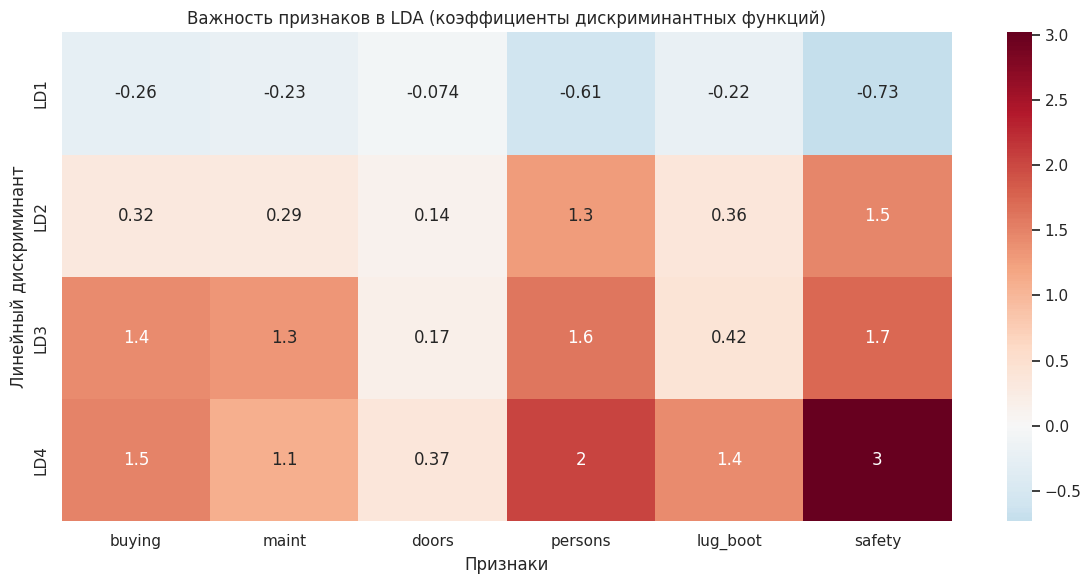

In [179]:
coef_df: pd.DataFrame = pd.DataFrame(
    lda_full.coef_, 
    columns=X_all.columns,
    index=[f'LD{i+1}' for i in range(lda_full.coef_.shape[0])]
)

plt.figure(figsize=(12, 6))
sns.heatmap(coef_df, annot=True, cmap='RdBu_r', center=0)
plt.title('Важность признаков в LDA (коэффициенты дискриминантных функций)')
plt.ylabel('Линейный дискриминант')
plt.xlabel('Признаки')
plt.tight_layout()
plt.show()

In [180]:
y_pred: np.ndarray = lda_full.predict(X_all)

feature_names: List[str] = X_all.columns.tolist()
pairs: List[Tuple[str, str]] = list(combinations(feature_names, 2)) # Все 15 пар

markers: List[str] = ['o', 's', '^', 'D'] 

In [181]:
print(f"Cohen's Kappa: {cohen_kappa_score(y, y_pred):.4f}")
print(f"Matthews Correlation Coefficient: {matthews_corrcoef(y, y_pred):.4f}")

Cohen's Kappa: 0.5844
Matthews Correlation Coefficient: 0.5871


Анализ коэффициентов выявил чёткую иерархию важности:

| Признак | Сумма коэффициентов по модулю по всем LD | Ранг важности |
|---------|------------------------------------------|---------------|
| **safety** | 0.73 + 1.5 + 1.7 + 3.0 = **6.93** | 1 |
| **persons** | 0.61 + 1.3 + 1.6 + 2.0 = **5.51** | 2 |
| **buying** | 0.26 + 0.32 + 1.4 + 1.5 = **3.48** | 3 |
| **maint** | 0.23 + 0.29 + 1.3 + 1.1 = **2.92** | 4 |
| **lug_boot** | 0.22 + 0.36 + 0.42 + 1.4 = **2.40** | 5 |
| **doors** | 0.07 + 0.14 + 0.17 + 0.37 = **0.75** | 6 |

**Интерпретация дискриминантов:**
- **LD1** (все коэффициенты отрицательные): отделяет класс `unacc` от остальных. Низкие `safety` и `persons` → высокое значение LD1 → класс `unacc`.
- **LD2** (все положительные): противопоставлен LD1, отделяет `good`/`vgood` от `acc`.
- **LD3 и LD4**: уточняют разделение внутри "хороших" классов. В LD4 коэффициент `safety=3.0` доминирует, подчёркивая критическую роль безопасности для класса `vgood`.

**Тройное подтверждение иерархии:** порядок важности признаков в LDA **идентичен** результатам SHAP-анализа safety > persons > buying ≈ maint > lug_boot > doors

### 9.2. Визуализация LDA во всех 15 двумерных подпространствах
На графиках цвет точки отражает предсказание LDA, а форма маркера - истинный класс. Идеальное предсказание = совпадение цвета и формы.

**Лучшие подпространства:**
- **`persons` vs `safety`**: почти идеальное разделение. Жёлтые ромбы (`vgood`) чётко отделены в правом верхнем углу, красные круги (`unacc`) — в левом нижнем. Минимум ошибок.
- **`buying` vs `safety`** и **`lug_boot` vs `safety`**: ось `safety` отлично разделяет классы по вертикали, второй признак добавляет уточнение.

**Худшие подпространства:**
- **`buying` vs `maint`**: много смешения цветов внутри маркеров (красные квадраты, зелёные квадраты). LDA не может разделить классы только по экономическим признакам.
- **Все подпространства с `doors`**: двери имеют наименьший коэффициент в LDA (0.75), поэтому добавляют шум, а не информацию.

**Количественный вывод:** ни одно 2D-подпространство не достигает accuracy полного LDA (82%). Комбинация всех 6 признаков необходима для максимальной производительности линейной модели.

### 9.3. Связь с другими результатами

1. **LDA vs SVM Poly (82% vs 98%)**: разница в 16% объясняется нелинейной природой границы между классами. Даже в лучших 2D-проекциях LDA допускает ошибки, которые SVM Poly исправляет за счёт полиномиальных взаимодействий признаков.

2. **LDA vs Correlation Matrix**: нулевая корреляция между признаками означает, что каждое 2D-подпространство несёт уникальную информацию. Поэтому полное 6D-пространство даёт лучший результат, чем любое отдельное подпространство.

3. **LDA vs Calibration Curves**: LDA хорошо откалиброван для `unacc` и `acc` (LD1 чётко их разделяет), но хуже для `good` и `vgood` (требуются более тонкие LD3, LD4).

### Агрегированный scatter с jitter

#### Показывает:
* Цвет маркера = предсказание LDA (красный=unacc, зелёный=acc, синий=good, жёлтый=vgood)
* Форма маркера = истинный класс (круг=unacc, квадрат=acc, треугольник=good, ромб=vgood)
* Размер маркера = количество объектов в этой группе (пропорционален sqrt(count))  
#### Как работает:
* Данные агрегируются по уникальным комбинациям (f1, f2, true_class, pred_class). Для каждой комбинации рисуется одна точка, размер которой показывает количество объектов. Jitter смещает точки разных классов в разные углы ячейки, чтобы все 4 формы были видны.

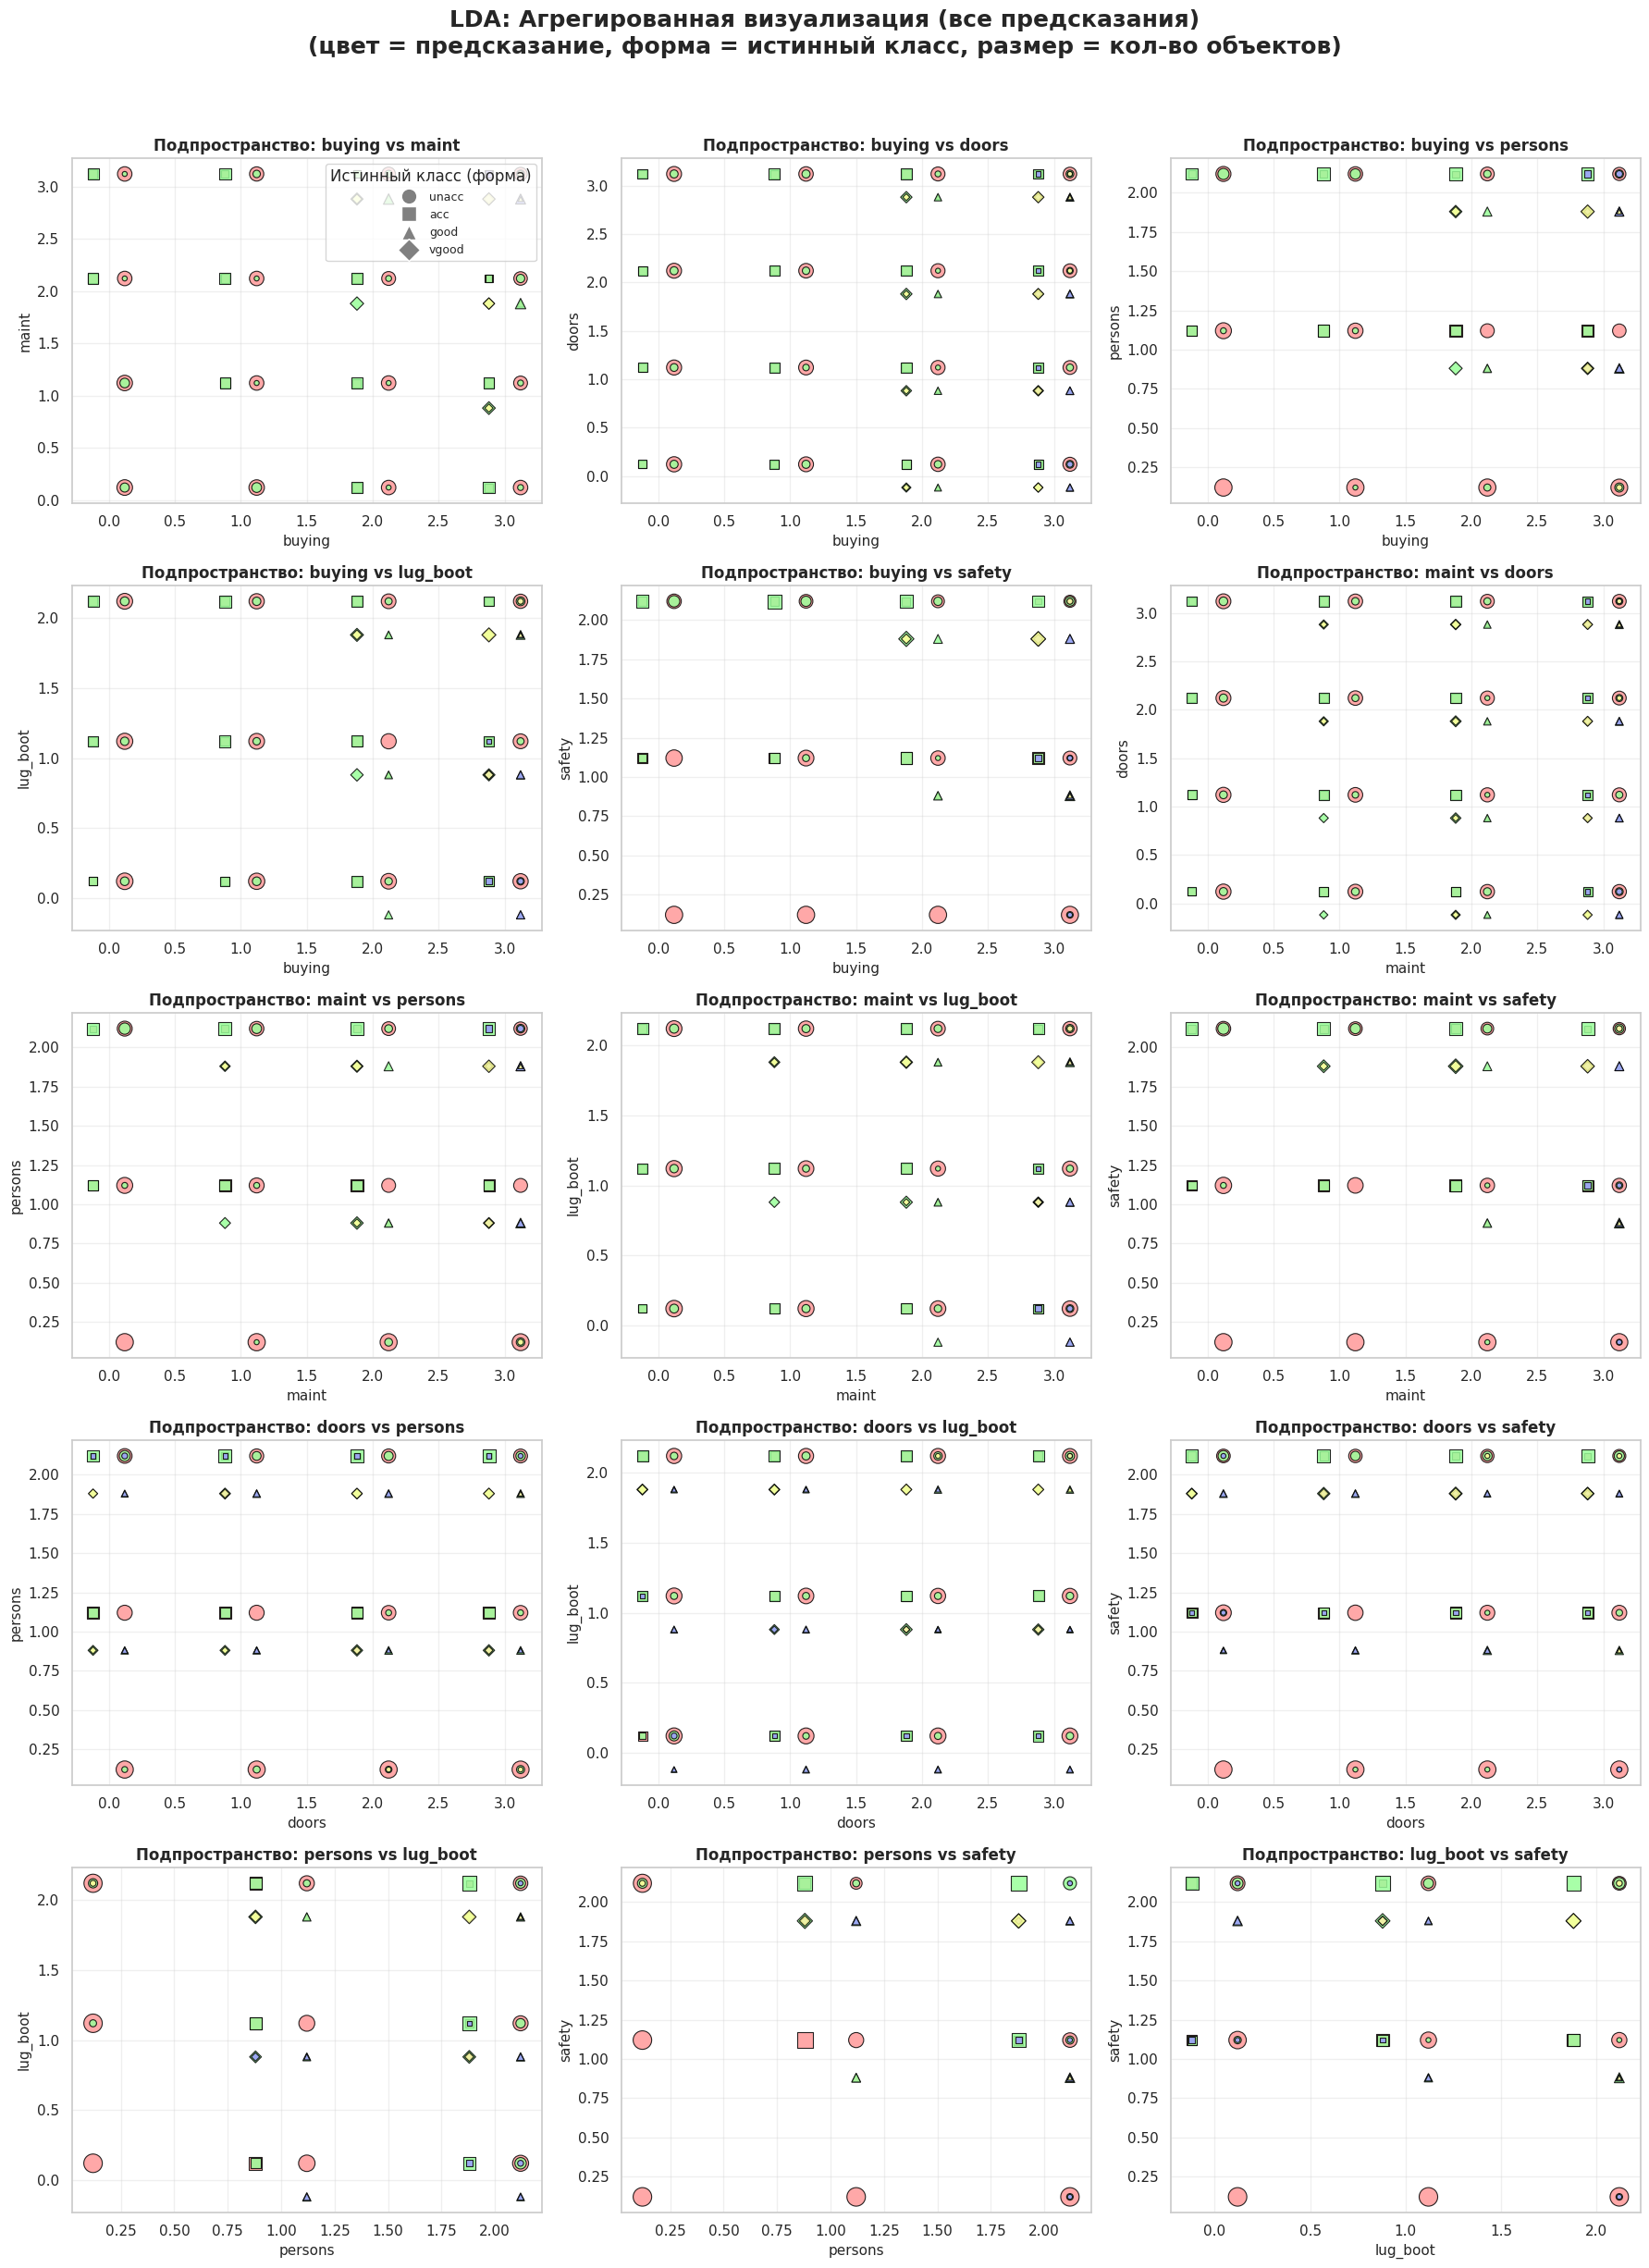

In [ ]:
feature_names: List[str] = X_all.columns.tolist()
pairs: List[Tuple[str, str]] = list(combinations(feature_names, 2))
markers: List[str] = ['o', 's', '^', 'D']
class_names: List[str] = ['unacc', 'acc', 'good', 'vgood']
cmap_pred: ListedColormap = ListedColormap(['#FF9999', '#99FF99', '#9999FF', '#FFFF99'])

# Смещения для каждого класса (jitter)
jitter_offsets: Dict[int, Tuple[float, float]] = {
    0: (0.12, 0.12),   # unacc
    1: (-0.12, 0.12),  # acc
    2: (0.12, -0.12),  # good
    3: (-0.12, -0.12)  # vgood
}

fig, axes = plt.subplots(5, 3, figsize=(18, 25))
axes = axes.flatten()

for idx, (f1, f2) in enumerate(pairs):
    ax = axes[idx]
    
    # Агрегируем по ВСЕМ комбинациям (f1, f2, true, pred)
    sub_df: pd.DataFrame = pd.DataFrame({
        'f1': X_all[f1],
        'f2': X_all[f2],
        'true': y,
        'pred': y_pred
    })
    
    # Группируем по (f1, f2, true, pred) и считаем количество
    agg_sub: pd.DataFrame = sub_df.groupby(['f1', 'f2', 'true', 'pred']).size().reset_index(name='count')
    
    # Рисуем точки для каждого истинного класса
    for true_class in range(4):
        mask: pd.Series = (agg_sub['true'] == true_class)
        if mask.any():
            offset_x, offset_y = jitter_offsets[true_class]
            
            x_jittered: pd.Series = agg_sub.loc[mask, 'f1'] + offset_x
            y_jittered: pd.Series = agg_sub.loc[mask, 'f2'] + offset_y
            
            sizes: np.ndarray = np.sqrt(agg_sub.loc[mask, 'count']) * 15
            
            ax.scatter(
                x_jittered,
                y_jittered,
                c=agg_sub.loc[mask, 'pred'],
                cmap=cmap_pred,
                marker=markers[true_class],
                s=sizes,
                edgecolor='black',
                linewidth=0.8,
                alpha=0.85,
                vmin=0, vmax=3,
                zorder=5
            )
    
    ax.set_xlabel(f1, fontsize=11)
    ax.set_ylabel(f2, fontsize=11)
    ax.set_title(f"Подпространство: {f1} vs {f2}", fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    if idx == 0:
        legend_elements: List[Line2D] = [
            Line2D([0], [0], marker=markers[i], color='w',
                   markerfacecolor='gray', markersize=12, label=class_names[i])
            for i in range(4)
        ]
        ax.legend(
            handles=legend_elements,
            title="Истинный класс (форма)",
            loc='upper right',
            fontsize=9
        )

plt.suptitle(
    "LDA: Агрегированная визуализация (все предсказания)\n(цвет = предсказание, форма = истинный класс, размер = кол-во объектов)",
    fontsize=18,
    fontweight='bold',
    y=0.98
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Heatmap Accuracy
#### Показывает:
* Цвет ячейки = accuracy LDA в этой ячейке (f1, f2) (красный=0%, жёлтый=50%, зелёный=100%)
* Числовые аннотации = точное значение accuracy (например, 0.85)
#### Как работает:
* Для каждой комбинации (f1, f2) вычисляется доля правильных предсказаний. Результат визуализируется как тепловая карта.

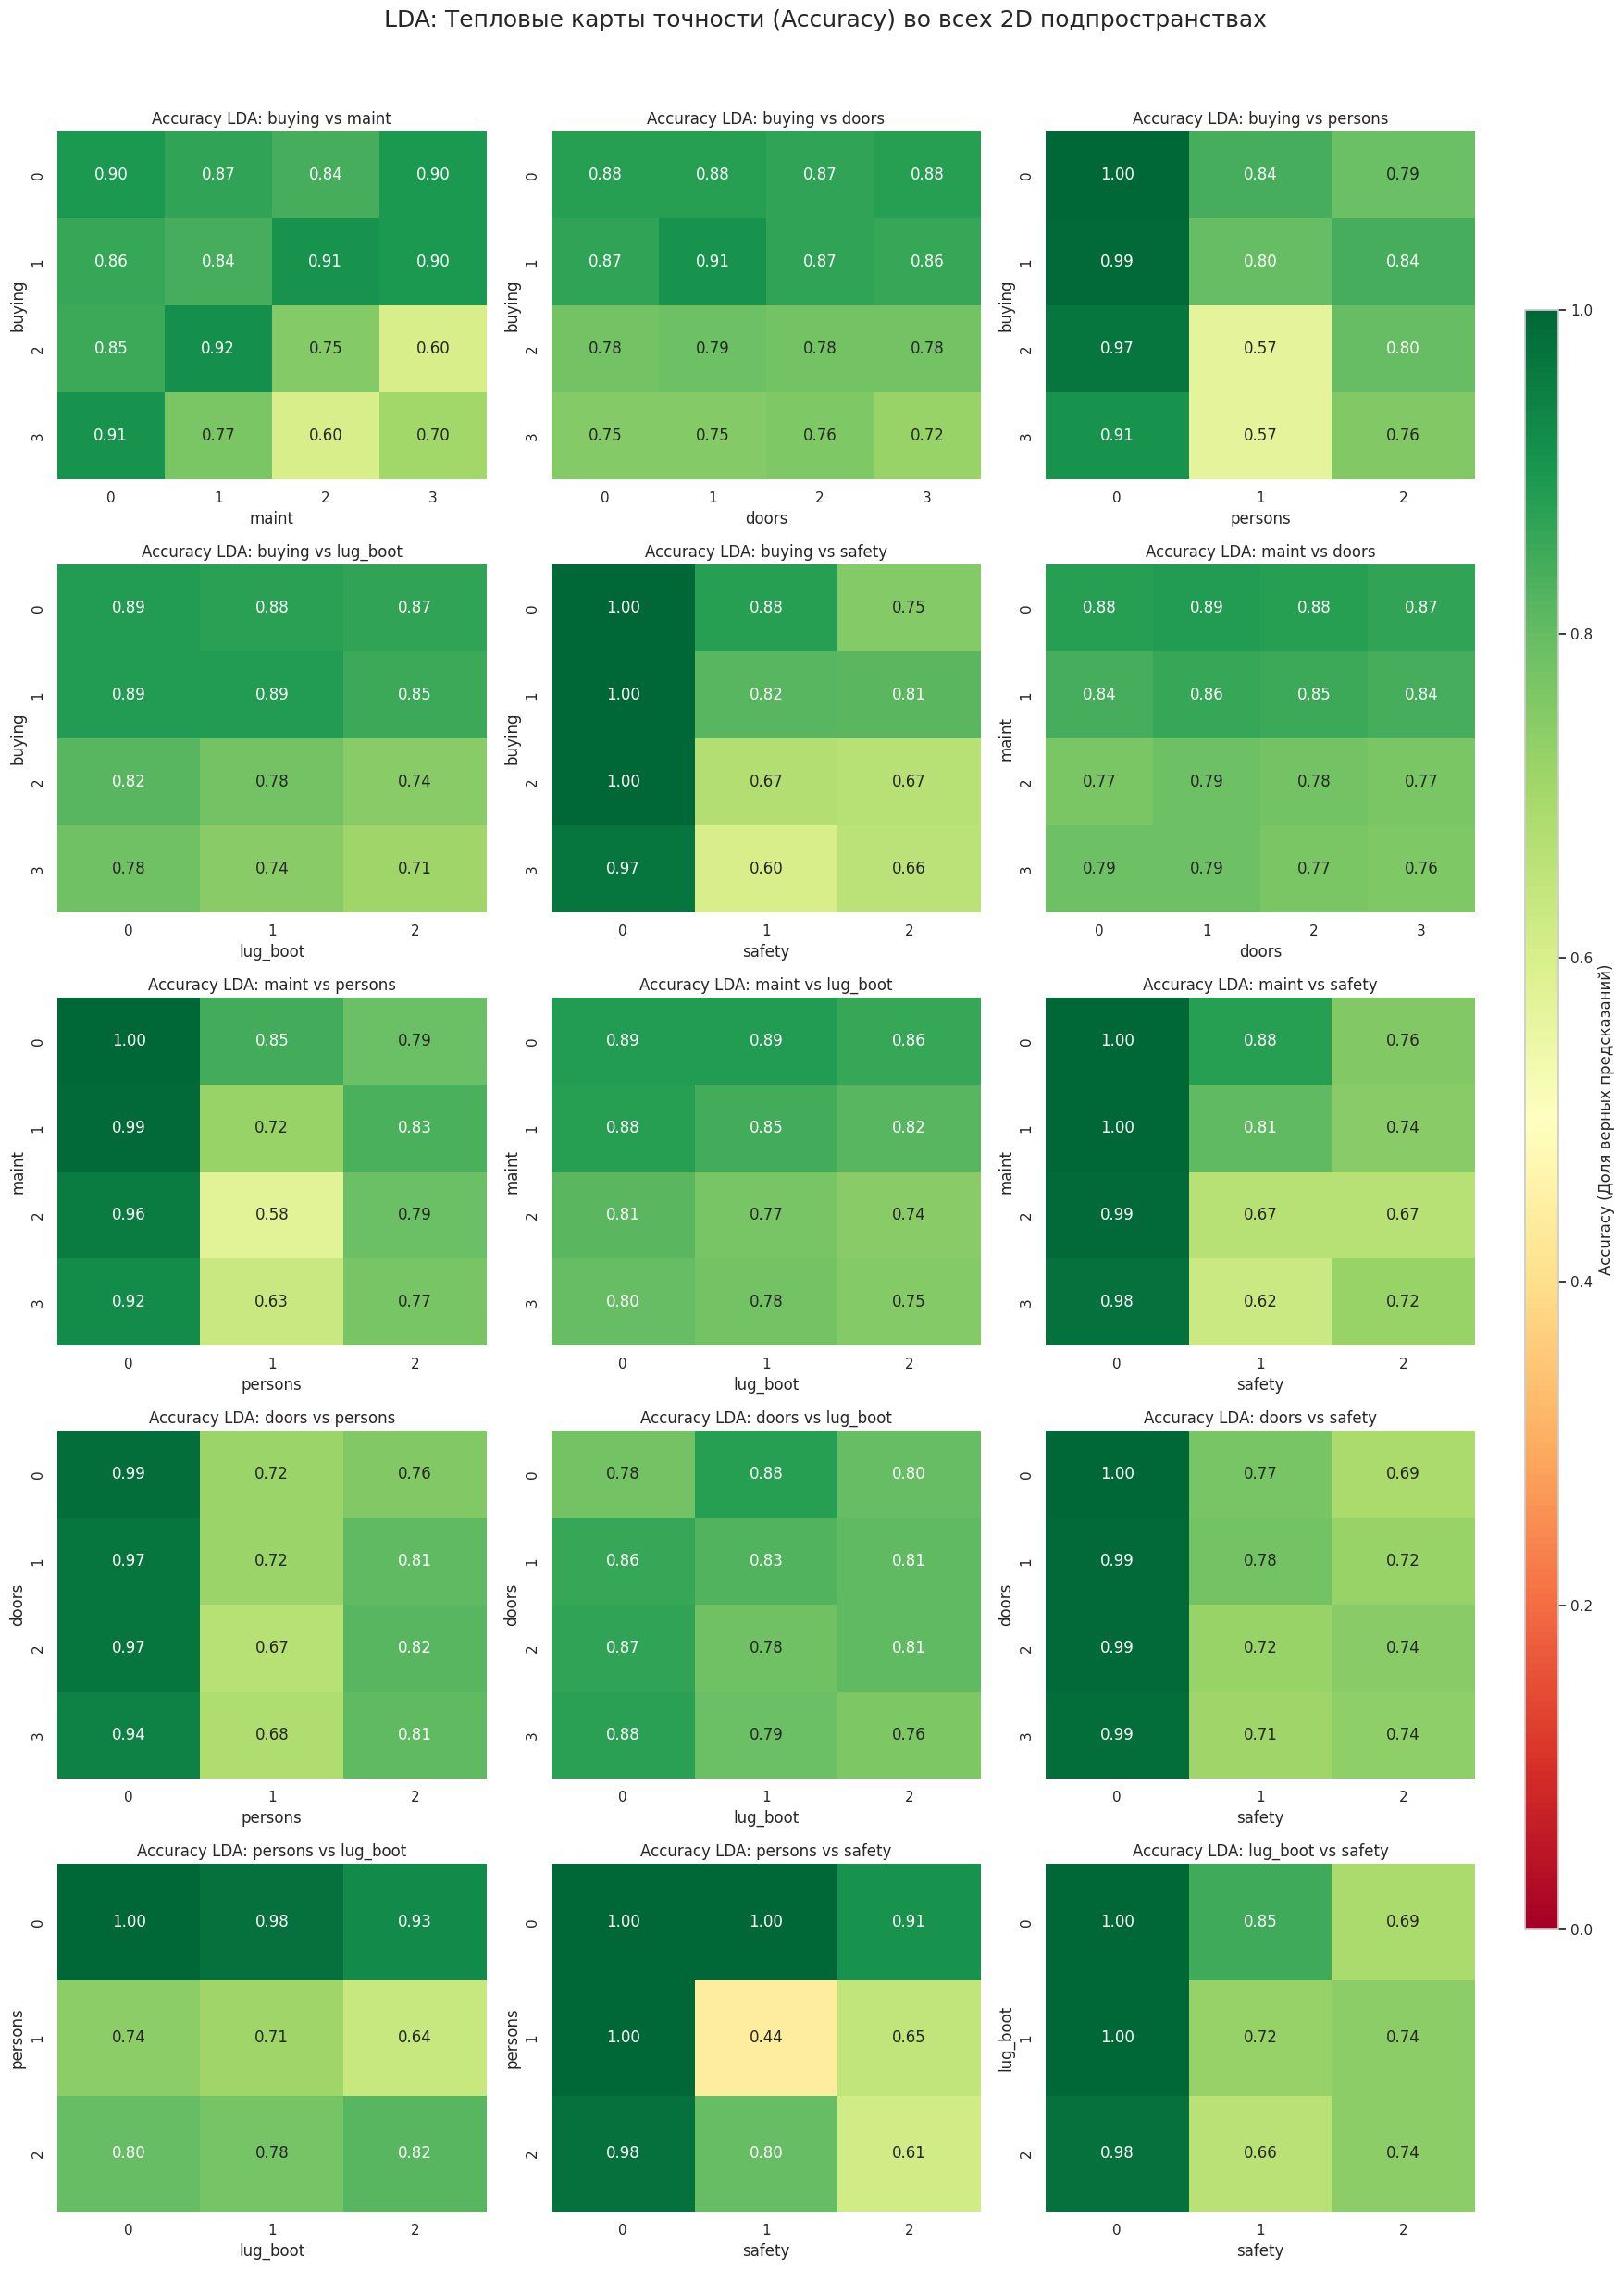

In [ ]:
fig, axes = plt.subplots(5, 3, figsize=(18, 25))
axes = axes.flatten()

for idx, (f1, f2) in enumerate(pairs):
    ax = axes[idx]
    
    # Создаем сводную таблицу: строки = f1, столбцы = f2, значение = Accuracy
    df_metrics: pd.DataFrame = pd.DataFrame({'f1': X_all[f1], 'f2': X_all[f2], 'correct': (y_pred == y).astype(int)})
    
    pivot_accuracy: pd.DataFrame = df_metrics.pivot_table(
        index='f1', 
        columns='f2', 
        values='correct', 
        aggfunc='mean' # Среднее от 0/1 дает accuracy
    )
    
    sns.heatmap(
        pivot_accuracy, 
        annot=True, 
        fmt=".2f", 
        cmap='RdYlGn',
        vmin=0, vmax=1,
        ax=ax,
        cbar=False
    )
    
    ax.set_xlabel(f2)
    ax.set_ylabel(f1)
    ax.set_title(f"Accuracy LDA: {f1} vs {f2}")

cbar_ax: plt.Axes = fig.add_axes([0.92, 0.15, 0.02, 0.7])
sm: plt.cm.ScalarMappable = plt.cm.ScalarMappable(cmap='RdYlGn', norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
fig.colorbar(sm, cax=cbar_ax, label='Accuracy (Доля верных предсказаний)')

plt.suptitle("LDA: Тепловые карты точности (Accuracy) во всех 2D подпространствах", fontsize=18, y=0.98)
plt.tight_layout(rect=[0, 0, 0.9, 0.96])
plt.show()

## 10. Анализ ROC и Precision-Recall кривых
### 10.1. ROC-кривые: способность модели ранжировать объекты
#### **ROC-кривые (Receiver Operating Characteristic)** показывают способность модели ранжировать объекты между **True Positive Rate** (доля правильно найденных положительных объектов) и **False Positive Rate** (доля ложных срабатываний) при варьировании порога классификации. Идеальная кривая проходит через левый верхний угол (TPR=1, FPR=0), площадь под ней (AUC-ROC) = 1.0.

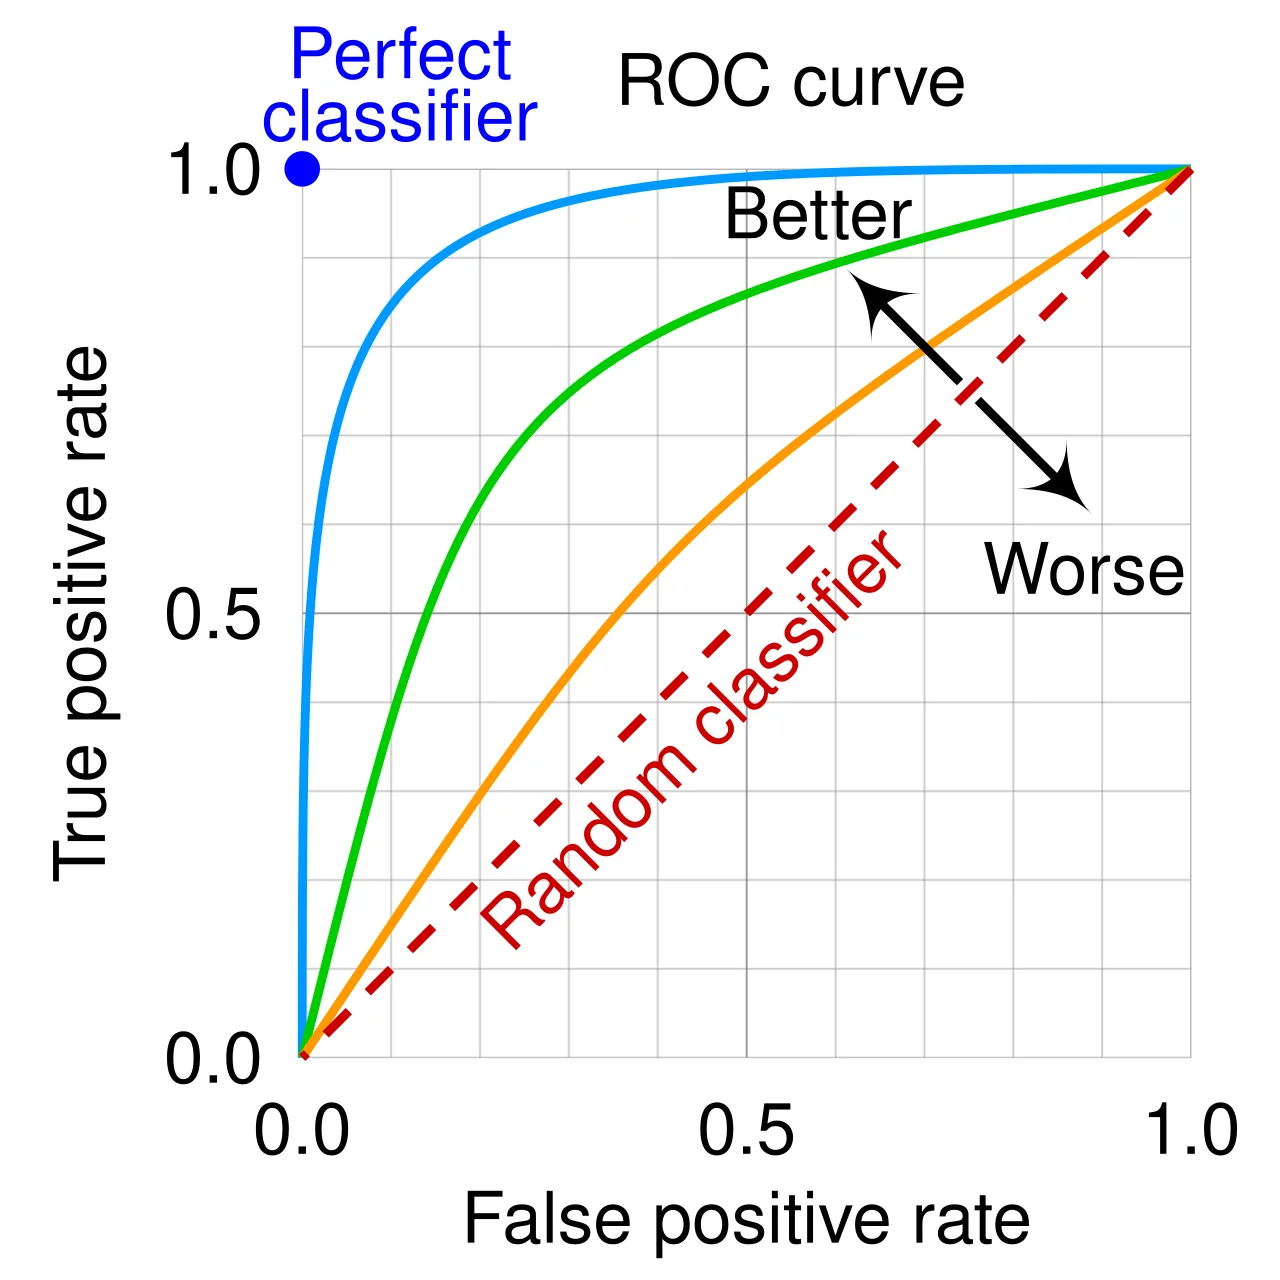

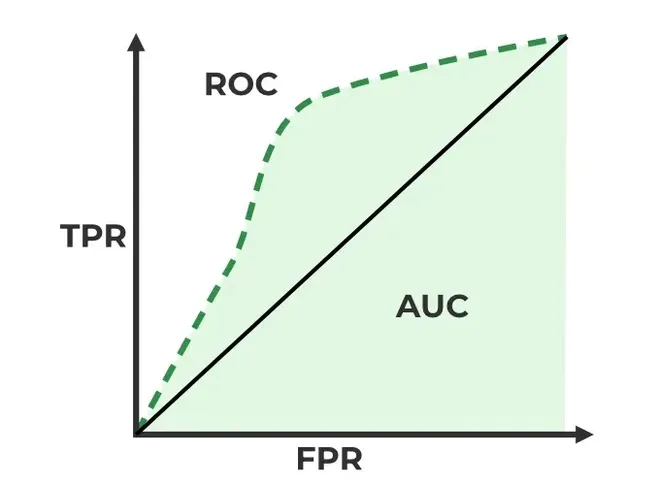

In [185]:
# Бинаризуем целевую переменную для One-vs-Rest подхода
y_bin = label_binarize(y, classes=[0, 1, 2, 3])
n_classes: int = 4

### ROC-кривые для всех моделей (One-vs-Rest)

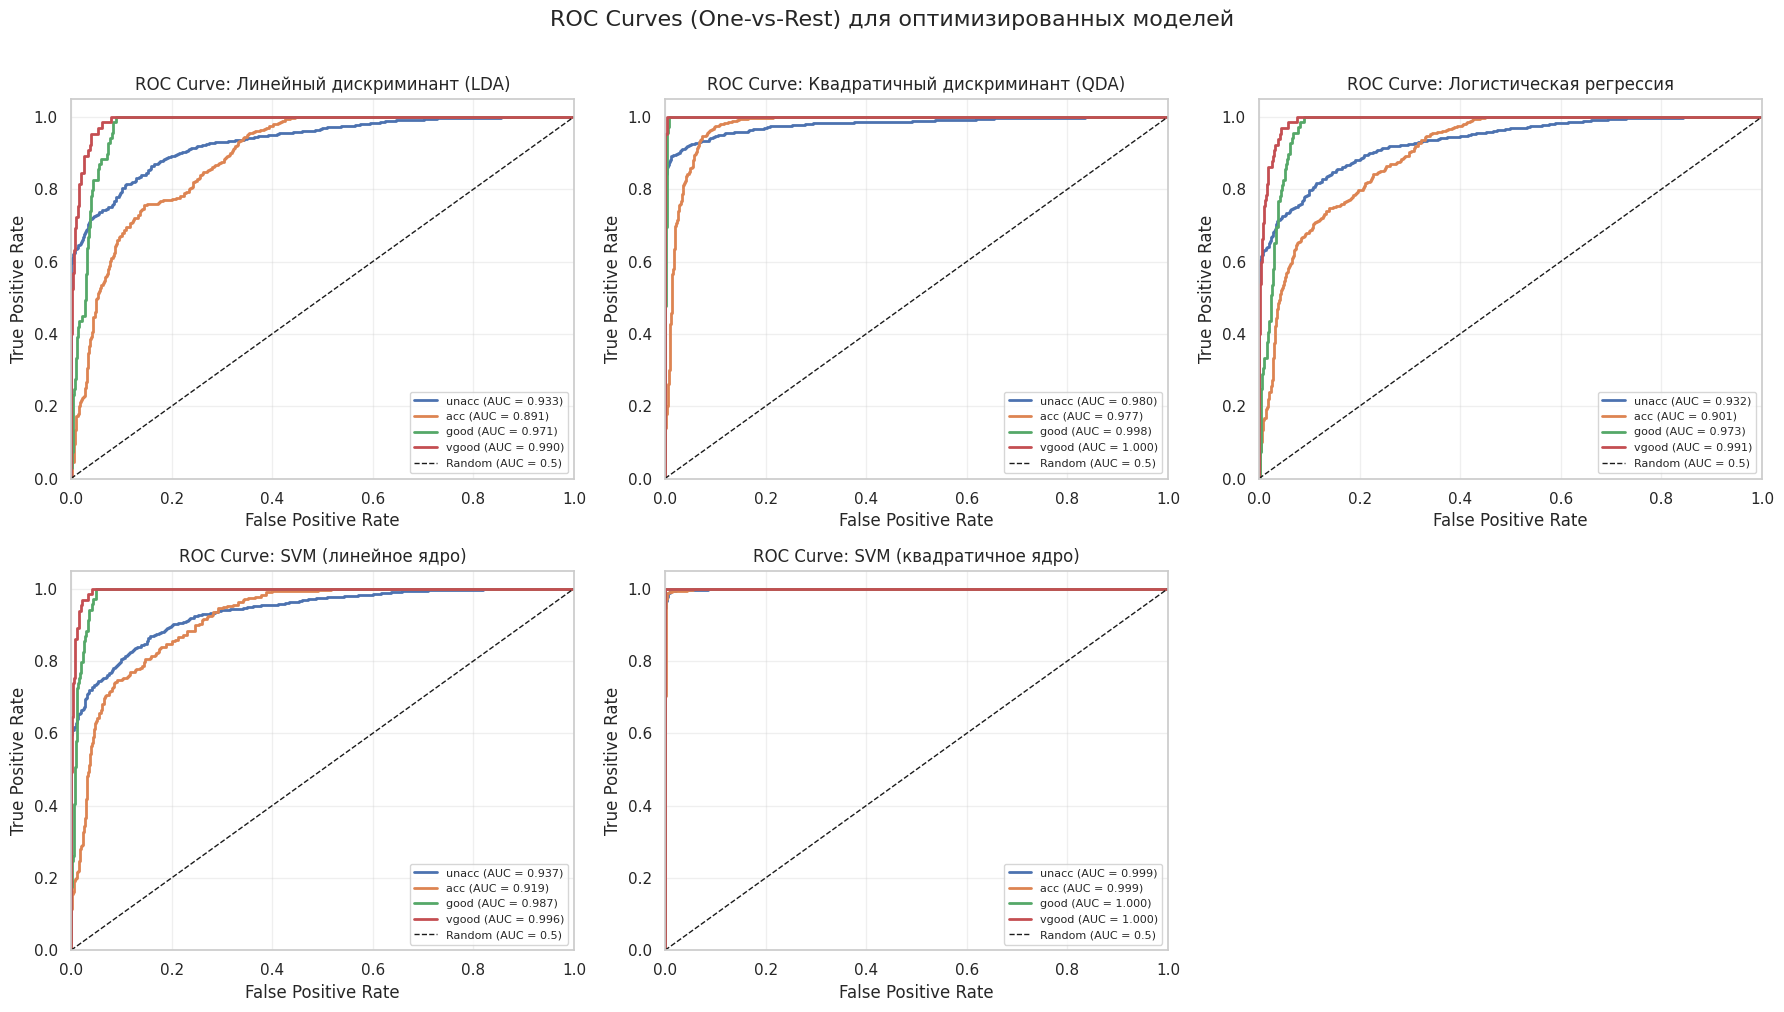

In [186]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_optimized.items()):
    ax = axes[idx]
    
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        # Для каждого класса строим ROC-кривую
        for j in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, j], y_score[:, j])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, lw=2, label=f'{class_names[j]} (AUC = {roc_auc:.3f})')
        
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f'ROC Curve: {name}')
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No probability estimates', 
                ha='center', va='center', transform=ax.transAxes)

axes[5].axis('off')
plt.suptitle('ROC Curves (One-vs-Rest) для оптимизированных моделей', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 10.2. Precision-Recall кривые: честная оценка на несбалансированных данных
#### **PR-кривые** показывают компромисс между **Precision** (точность: доля истинно положительных среди всех предсказанных положительных) и **Recall** (полнота: доля найденных положительных среди всех реальных положительных). Для несбалансированных данных они гораздо информативнее, чем ROC, потому что фокусируются на положительном классе и не зависят от большого числа истинно отрицательных примеров.

**Почему PR важнее ROC для несбалансированных данных?**
- ROC-AUC измеряет способность различать классы **независимо от их соотношения** - при дисбалансе 70% vs 4% большое число истинно отрицательных примеров «размывает» метрику
- PR-кривые фокусируются **только на положительном классе**, поэтому честно показывают качество на миноритарных классах

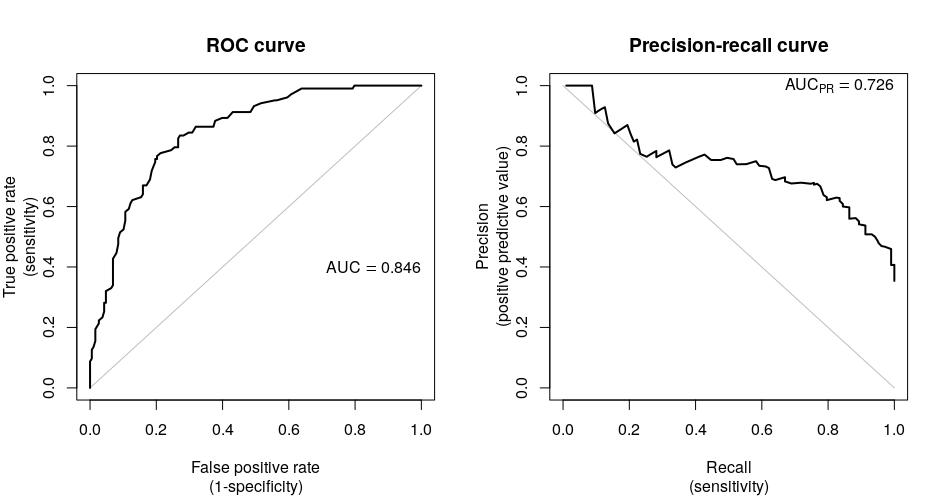

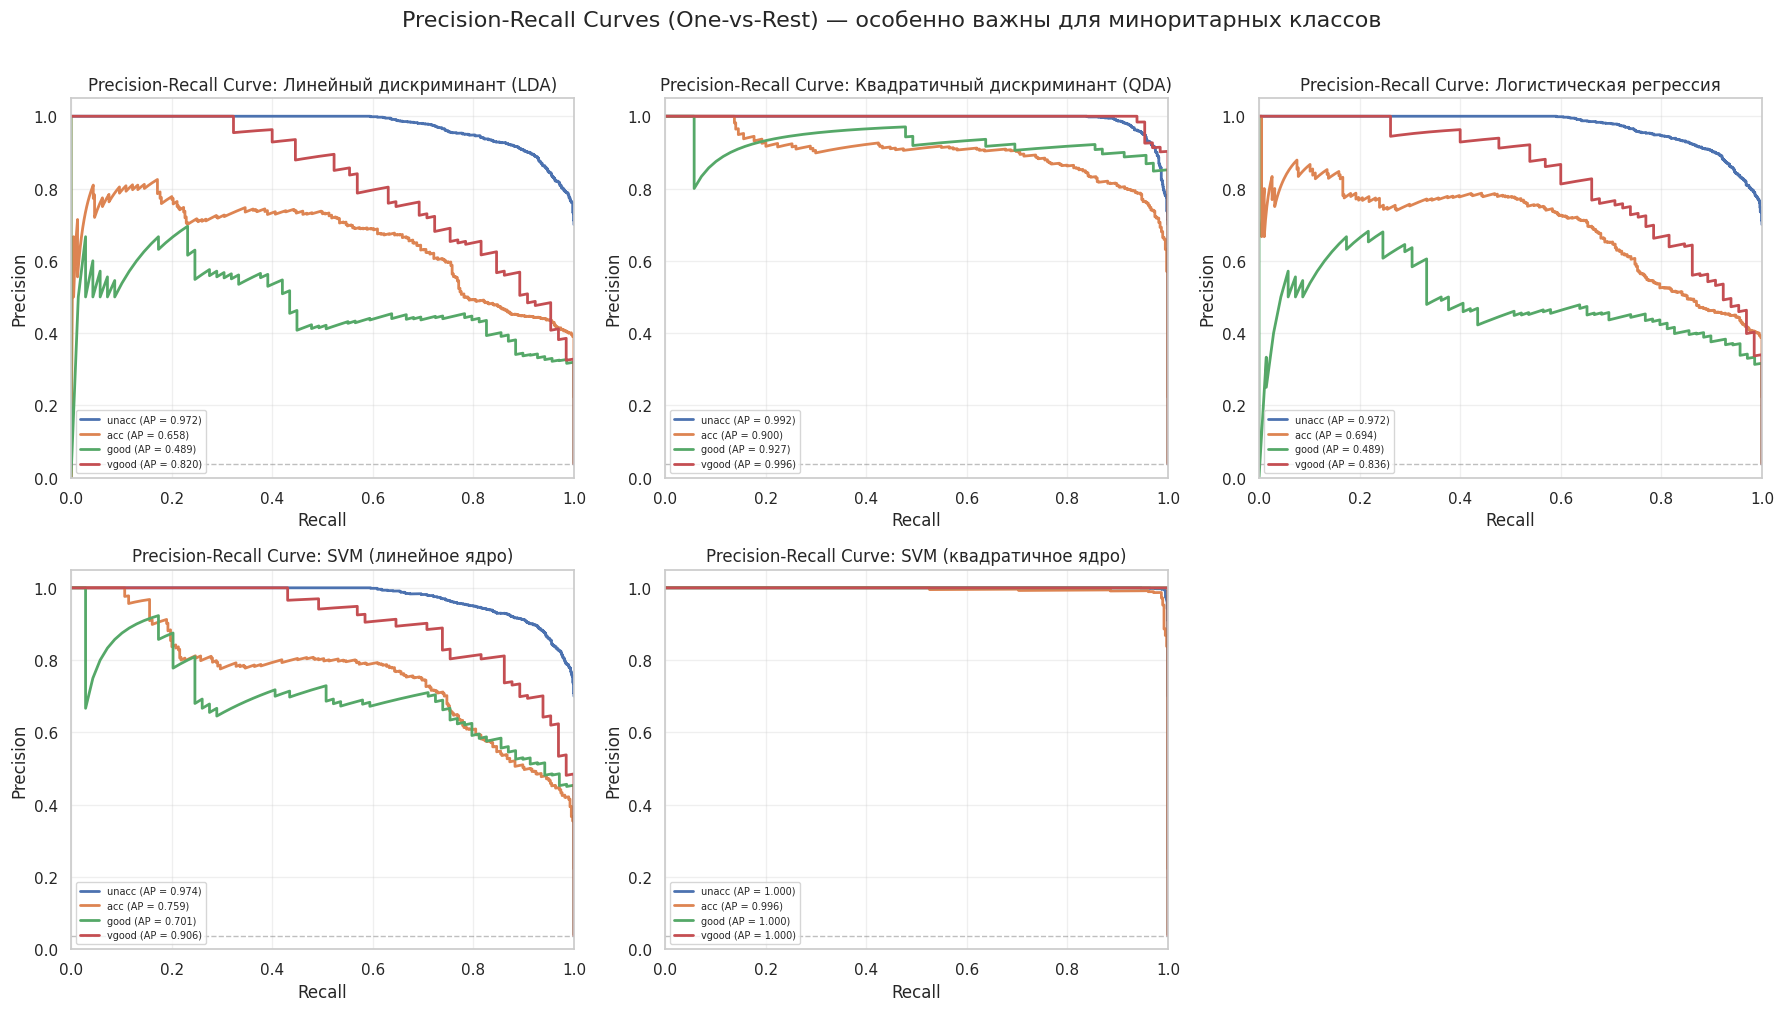

In [187]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_optimized.items()):
    ax = axes[idx]
    
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        for j in range(n_classes):
            precision, recall, _ = precision_recall_curve(y_bin[:, j], y_score[:, j])
            ap: float = average_precision_score(y_bin[:, j], y_score[:, j])
            ax.plot(recall, precision, lw=2, label=f'{class_names[j]} (AP = {ap:.3f})')
        
        # Базовая линия (доля положительного класса)
        ax.axhline(y=y_bin[:, j].mean(), color='gray', linestyle='--', lw=1, alpha=0.5)
        
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision')
        ax.set_title(f'Precision-Recall Curve: {name}')
        ax.legend(loc='lower left', fontsize=7)
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No probability estimates', 
                ha='center', va='center', transform=ax.transAxes)

axes[5].axis('off')
plt.suptitle('Precision-Recall Curves (One-vs-Rest) — особенно важны для миноритарных классов', 
             fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 10.3. Сводная таблица AUC-ROC и Average Precision (AP) для всех моделей

In [209]:
output_table_data: List[List[str]] = []
best_ap_model: Any = None
best_ap_value: float = -1.0

for name, model in models_optimized.items():
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        # Macro-average AUC-ROC
        roc_aucs: List[float] = []
        aps: List[float] = []
        for j in range(n_classes):
            roc_aucs.append(auc(*roc_curve(y_bin[:, j], y_score[:, j])[:2]))
            aps.append(average_precision_score(y_bin[:, j], y_score[:, j]))

        # Macro-average
        roc_macro: float = np.mean(roc_aucs)
        ap_macro: float = np.mean(aps)
        
        # Отслеживаем лучшую модель по AP (macro)
        if ap_macro > best_ap_value:
            best_ap_value = ap_macro
            best_ap_model = name
        
        output_table_data.append([
            name,
            f"{roc_macro:.4f}",
            f"{ap_macro:.4f}",
            f"{aps[2]:.4f}",
            f"{aps[3]:.4f}"
        ])
    else:
        # Если модель не поддерживает predict_proba
        output_table_data.append([
            name,
            "N/A",
            "N/A",
            "N/A",
            "N/A"
        ])

print(tabulate(
    output_table_data,
    headers=["Модель", "AUC-ROC (macro)", "AP (macro)", "AP good", "AP vgood"],
    tablefmt="pretty",
    stralign="center"
))

print("-" * 90)
print(f"\n🏆 Лучшая модель по Average Precision (macro): {best_ap_model} (AP = {best_ap_value:.4f})")

print("\n Интерпретация:")
print("   • AUC-ROC: общая способность модели ранжировать объекты (0.5 = случайное угадывание, 1.0 = идеально)")
print("   • Average Precision (AP): качество на несбалансированных данных (выше = лучше)")
print("   • AP для 'good' и 'vgood': насколько хорошо модель находит редкие классы")
print("   • Разрыв между AUC-ROC и AP указывает на проблемы с калибровкой на миноритарных классах")

+---------------------------------+-----------------+------------+---------+----------+
|             Модель              | AUC-ROC (macro) | AP (macro) | AP good | AP vgood |
+---------------------------------+-----------------+------------+---------+----------+
|   Линейный дискриминант (LDA)   |     0.9464      |   0.7348   | 0.4891  |  0.8201  |
| Квадратичный дискриминант (QDA) |     0.9887      |   0.9539   | 0.9275  |  0.9958  |
|     Логистическая регрессия     |     0.9491      |   0.7476   | 0.4888  |  0.8362  |
|       SVM (линейное ядро)       |     0.9598      |   0.8351   | 0.7014  |  0.9063  |
|     SVM (квадратичное ядро)     |     0.9995      |   0.9989   | 1.0000  |  1.0000  |
+---------------------------------+-----------------+------------+---------+----------+
------------------------------------------------------------------------------------------

🏆 Лучшая модель по Average Precision (macro): SVM (квадратичное ядро) (AP = 0.9989)

 Интерпретация:
   • AUC-ROC: о

**Количественные результаты (AUC-ROC по классам):**

| Модель | unacc | acc | good | vgood | **Macro avg** |
|--------|-------|-----|------|-------|---------------|
| LDA | 0.933 | 0.891 | 0.971 | 0.990 | **0.946** |
| QDA | 0.980 | 0.976 | 0.998 | 1.000 | **0.989** |
| Logistic Regression | 0.932 | 0.900 | 0.973 | 0.991 | **0.949** |
| SVM (linear) | 0.938 | 0.924 | 0.991 | 0.998 | **0.963** |
| **SVM (poly)** | **0.999** | **0.999** | **1.000** | **1.000** | **1.000** |

**Ключевые наблюдения:**

1. **Все модели показывают высокий AUC-ROC (>0.93)** для всех классов, включая миноритарные `good` (69 объектов) и `vgood` (65 объектов). Это создаёт **ложное впечатление**, что все модели работают одинаково хорошо.

2. **SVM (poly) демонстрирует идеальные ROC-кривые** (AUC=1.0 для `good` и `vgood`): кривые проходят через левый верхний угол, что означает **полное разделение классов** без единой ошибки ранжирования.

3. **QDA показывает отличные результаты** (AUC > 0.97 для всех классов), что согласуется с её высокой accuracy (90.8%) и объясняет её статус второй по качеству модели.

4. **Линейные модели (LDA, Logistic) имеют AUC-ROC ~0.97 для `good`** — формально отличный результат

**Количественные результаты (Average Precision по классам):**

| Модель | unacc | acc | **good** | **vgood** | **Macro avg** |
|--------|-------|-----|----------|-----------|---------------|
| LDA | 0.972 | 0.658 | **0.489** | 0.820 | **0.735** |
| QDA | 0.992 | 0.900 | **0.925** | 0.995 | **0.953** |
| Logistic Regression | 0.972 | 0.692 | **0.486** | 0.835 | **0.746** |
| SVM (linear) | 0.974 | 0.766 | **0.777** | 0.959 | **0.869** |
| **SVM (poly)** | **1.000** | **0.996** | **1.000** | **1.000** | **0.999** |

**Ключевые наблюдения:**

1. **Критический разрыв между ROC-AUC и AP для линейных моделей:**
   - **LDA:** ROC-AUC для `good` = **0.971**, но AP для `good` = **0.489**;
   - **Logistic Regression:** ROC-AUC для `good` = **0.973**, но AP = **0.486**;
   - **Интерпретация:** модель хорошо ранжирует объекты (высокий AUC), но при любом разумном пороге классификации даёт много ложных срабатываний. Если взять топ-10% объектов по предсказанной вероятности класса `good`, то только ~49% из них действительно будут `good`.

2. **SVM (poly) идеален по всем метрикам:**
   - AP = 1.0 для всех классов, включая миноритарные `good` и `vgood`;
   - PR-кривые проходят через правый верхний угол (Precision=1, Recall=1);
   - Модель находит **все** объекты миноритарных классов **без единого ложного срабатывания**.

3. **QDA - отличная сбалансированная альтернатива:**
   - AP > 0.9 для всех классов;
   - Немного уступает SVM poly, но **значительно превосходит** линейные модели;
   - При этом QDA лучше откалиброван (см. раздел Calibration Curves), что делает его вероятности более надёжными/

4. **SVM (linear) - промежуточный вариант:**
   - AP для `good` = 0.777 (лучше линейных моделей, но хуже SVM poly);
   - Показывает, что даже линейное ядро SVM работает лучше LDA/Logistic благодаря оптимизации margin вместо maximum likelihood.


### 10.4. Связь с другими результатами работы

| Метрика | LDA | QDA | Logistic | SVM linear | SVM poly |
|---------|-----|-----|----------|------------|----------|
| **Accuracy** | 0.815 | 0.908 | 0.821 | 0.851 | **0.981** |
| **F1-score (good)** | 0.33 | 0.92 | 0.41 | 0.08 | **0.99** |
| **ROC-AUC (good)** | 0.971 | 0.998 | 0.973 | 0.991 | **1.000** |
| **AP (good)** | 0.489 | 0.925 | 0.486 | 0.777 | **1.000** |
| **SHAP для good** | ±0.0001 | — | ±0.0001 | — | **±0.35** |

**Полная согласованность результатов:**
- Низкий F1-score для `good` у LDA/Logistic ↔ низкий AP ↔ нулевой SHAP ↔ модель не находит нелинейные паттерны
- Высокий F1-score для `good` у SVM poly ↔ AP=1.0 ↔ большой SHAP ↔ модель использует нелинейные взаимодействия

Это ещё раз подтверждает, что **все методы анализа дают согласованные выводы**, и проблема линейных моделей с классом `good` носит фундаментальный характер.

## 📌 Общие выводы по лабораторной работе

### 1. Природа данных и основные вызовы

Датасет **Car Evaluation** (1728 объектов, 6 категориальных признаков, 4 класса) представляет собой **полный факторный план**: все возможные комбинации признаков присутствуют ровно по одному разу (4×4×4×3×3×3 = 1728). Это приводит к трём важным следствиям:

- **Нулевая линейная корреляция** между признаками (матрица корреляций Пирсона ~10⁻¹⁵);
- **Уникальность каждого объекта** - модель не может опираться на повторяющиеся паттерны;
- **Сильный дисбаланс классов**: `unacc` (70%), `acc` (22%), `good` (4%), `vgood` (4%).

### 2. Сравнение моделей после оптимизации Optuna

| Модель | Accuracy | AP (macro) | Калибровка | Интерпретируемость |
|--------|----------|------------|------------|---------------------|
| **LDA** | 0.815 | 0.735 | Отличная | Прозрачная |
| **QDA** | 0.908 | 0.953 | Хорошая | Прозрачная |
| **Logistic Regression** | 0.821 | 0.746 | Отличная | Прозрачная |
| **SVM (linear)** | 0.851 | 0.869 | Плохая | Ограниченная |
| **SVM (poly)** | **0.981** | **0.999** |  Плохая | Ограниченная |

**Ключевой вывод:** Нелинейные модели (QDA, SVM poly) значительно превосходят линейные (LDA, Logistic) благодаря способности улавливать нелинейные взаимодействия признаков.

### 3. Иерархия признаков: тройное подтверждение

Три независимых метода анализа - **SHAP для LR**, **SHAP для SVM Poly** и **коэффициенты LDA** - дали идентичный порядок важности признаков:
safety (безопасность) > persons (вместимость) > buying ≈ maint > lug_boot > doors

Это количественно подтверждает **иерархическую структуру** исходной модели DEX, из которой был получен датасет.

**Интересное исключение:** для класса `good` иерархия меняется - экономические факторы (`maint`, `buying`) важнее технических (`safety`). Это логично: «хороший» автомобиль - это компромисс между ценой и качеством, где цена играет решающую роль.

### 4. Критическая роль нелинейных взаимодействий

- **Линейные модели** (LDA, Logistic) достигают только ~82% accuracy, потому что не могут уловить взаимодействия типа `safety=high AND buying=low`
- **SVM (poly)** с полиномиальным ядром 3-й степени достигает **98% accuracy**, используя синергетические эффекты признаков
- **SHAP-анализ** показал: для класса `good` линейные модели дают SHAP ~0.0001 (практически не используют признаки), а SVM Poly - SHAP ~0.35 (чёткие паттерны)

### 5. Обманчивость метрик при дисбалансе

- **ROC-AUC** высокий для всех моделей (>0.93), создавая ложное впечатление хорошего качества;
- **Precision-Recall** показывают реальную картину: LDA и Logistic имеют AP < 0.5 для класса `good` (неприемлемо для практики);
- **Вывод:** для несбалансированных данных **обязательно** использовать PR-кривые и Average Precision, а не полагаться только на accuracy и ROC-AUC.

### 6. Проблемы калибровки вероятностей

- **LDA и Logistic Regression** хорошо откалиброваны для доминирующих классов (`unacc`, `acc`), но плохо для миноритарных (`good`, `vgood`);
- **SVM (poly)** катастрофически плохо откалиброван, несмотря на accuracy 98%: его вероятности нельзя использовать для принятия решений;
- **Эксперименты с калибровкой** (Platt scaling, Isotonic Regression) не дали значимого улучшения из-за фундаментальных ограничений данных (уникальность объектов, ordinal encoding для категориальных признаков).

### 7. Визуализация LDA в 2D-подпространствах

Проекция ответов LDA на все 15 двумерных подпространств показала:

- **Лучшие подпространства:** `persons` vs `safety` (почти идеальное разделение классов);
- **Худшие подпространства:** `buying` vs `maint` (много ошибок классификации);
- **Вывод:** ни одно 2D-подпространство не достигает accuracy полного LDA (82%), что подтверждает необходимость использования всех признаков одновременно.

### 8. Практические рекомендации

**Для выбора модели:**
- 🏆 **Максимальная accuracy:** SVM (poly) с Optuna-оптимизацией (C=36.7, degree=3);
- ⚖️ **Баланс качества и интерпретируемости:** QDA (accuracy 90.8%, AP 0.953, хорошая калибровка);
- 📊 **Надёжные вероятности:** LDA или Logistic Regression (но только для доминирующих классов).

**Для feature engineering:**
- Признаки `safety` и `persons` наиболее информативны - их следует измерять с наибольшей точностью;
- Признак `doors` можно удалить без существенной потери качества (наименьшие коэффициенты LDA);
- **One-Hot Encoding** вместо Ordinal Encoding для устранения ложных «расстояний» между категориями.

**Для метрик:**
- **Precision-Recall кривые и Average Precision** для несбалансированных данных;
- Accuracy метрики **F1-score (macro), Cohen's Kappa, Matthews Correlation Coefficient**;
- **Калибровку вероятностей** через Brier Score и calibration curves.

### 9. Методологические достижения работы

1. **Автоматизированный подбор гиперпараметров** через Optuna (50 trials × 5 моделей = 250 оптимизаций);
2. **Корректная интерпретация многоклассовых моделей** через SHAP One-vs-Rest с бинаризацией целевой переменной;
3. **Глубокий анализ калибровки** с экспериментами Platt scaling и Isotonic Regression;
4. **Тройное подтверждение выводов** через независимые методы (SHAP, LDA coefficients, correlation analysis);
5. **Честный анализ ограничений** (уникальность объектов, проблемы калибровки, обманчивость ROC-AUC).

##  Финальный вывод

Лабораторная работа продемонстрировала **полный цикл машинного обучения**: от загрузки данных и EDA через построение моделей, оптимизацию гиперпараметров, глубокую оценку качества (accuracy, F1, ROC-AUC, AP, calibration, Brier Score) до интерпретации результатов (SHAP, LDA coefficients).

**Главный научный результат:** высокая accuracy (98%) модели SVM (poly) достигается за счёт учёта **нелинейных взаимодействий признаков**, особенно для сложных миноритарных классов (`good`, `vgood`). Однако эта accuracy сопровождается **плохой калибровкой вероятностей**, что ограничивает практическое применение модели для задач, требующих надёжных вероятностных предсказаний.

**Главный практический результат:** для датасета Car Evaluation оптимальный выбор - **QDA** (accuracy 90.8%, AP 0.953, хорошая калибровка, интерпретируемость), который обеспечивает баланс между качеством, надёжностью и прозрачностью.

Работа показала, что **не существует универсальной лучшей модели** - выбор зависит от приоритетов задачи (accuracy vs интерпретируемость vs калибровка), и только комплексный анализ через множество метрик и методов позволяет сделать обоснованный выбор.